# **Analyzing the Importance of Audio Features in Music Genre Classification Using Data Mining Techniques**

**An Exploratory Data Analysis (EDA) for the FMA-Small Dataset**
<br>
**Notebook by: Elia Fel P. Bado**

#**I. Introduction**





####**Data Source & Origin**
*   Repository Link: [FMA GitHub Repository](https://github.com/mdeff/fma)
*   Citation: Defferrard, M., Benzi, K., Vandergheynst, P., & Bresson, X. (2017). *FMA: A Dataset for Music Analysis*. arXiv:1612.01840.
<br>

####**Who collected the data, when, how, and for what purpose?**
* The dataset was created by Michaël Defferrard, Kirell Benzi, Pierre Vandergheynst, and Xavier Bresson in 2017 for the 18th International Society for Music Information Retrieval Conference (ISMIR). It was designed to provide an open, easily accessible audio dataset for evaluating tasks in Music Information Retrieval (MIR), aiming to overcome hurdles from the limited availability of large public audio datasets. The data was collected by querying the Free Music Archive (FMA) web API.
<br>

####**What does one row represent?**
* `tracks.csv`: One row represents a single music track.
* `features.csv`: One row represents extracted audio features (via librosa) for a track.
<br>

####**What does each column mean?**
* `tracks.csv`: Contains track metadata such as track ID, title, artist, genres, tags, and play counts.
* `features.csv`: Contains statistical descriptors of common audio features extracted using `librosa` (e.g., MFCCs, spectral centroid, chroma).

<br>

####**Questions to Explore**
1.   How accurately can baseline machine learning models perform genre recognition using extracted audio features vs. raw audio?
2.   How does the hierarchical genre taxonomy affect classification performance across top-level genres?
3.   Can representation learning on artist labels transfer effectively to genre classification tasks?
4.   How do Echonest audio features compare with librosa-extracted features in predicting track play counts?

In [2]:
import os

# connecting colab to gdrive, check if folder exists, and return folder size
from google.colab import drive
drive.mount('/content/drive')

#paths
base_path = '/content/drive/MyDrive/Music_Genre_Classification'
dataset_path = os.path.join(base_path, 'dataset')

raw_dataset_path = os.path.join(dataset_path, 'raw')
fma_metadata_path = os.path.join(raw_dataset_path, 'fma_metadata')
fma_small_path = os.path.join(raw_dataset_path, 'fma_small')

processed_dataset_path = os.path.join(dataset_path, 'processed')


#for fetching folder size
def get_dir_size(path):
    total_size = 0
    for dirpath, dirnames, filenames in os.walk(path):
        for f in filenames:
            fp = os.path.join(dirpath, f)
            if not os.path.islink(fp):
                total_size += os.path.getsize(fp)
    return total_size

#to check if folders has contents
folder_exists = os.path.exists(base_path)
print(f"Music_Genre_Classification file exists: {folder_exists}")
print(f"dataset/raw/fma_metadata exists: {os.path.exists(fma_metadata_path)}")
print(f"dataset/raw/fma_small exists: {os.path.exists(fma_small_path)}")

if folder_exists:
    fma_metadata_file_size = (get_dir_size(fma_metadata_path))/(1024*1024)
    fma_small_file_size = (get_dir_size(fma_small_path))/(1024*1024)
    print(f"fma_metadata Folder Size: {fma_metadata_file_size:.2f} MB")
    print(f"fma_small Folder Size: {fma_small_file_size:.2f} MB")
else:
    print("Folder Size: N/A")

Mounted at /content/drive
Music_Genre_Classification file exists: True
dataset/raw/fma_metadata exists: True
dataset/raw/fma_small exists: True
fma_metadata Folder Size: 1396.98 MB
fma_small Folder Size: 7606.00 MB


# **II. Data loading and first look**

This section loads and inspects the two core tables needed for FMA-Small genre analysis: `tracks.csv` (track metadata, dataset splits, and top-level genre labels) and `features.csv` (518 pre-extracted `librosa` audio descriptors per track). Both files are parsed with their multi-index headers, filtered and index-aligned to the 8,000-track `fma-small` subset, and reviewed for shape, sample records, data types, summary statistics, and variable classifications to establish a verified baseline before data quality checks.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import Markdown

In [4]:
# DATA LOADING FOR tracks.csv

tracks_path = os.path.join(fma_metadata_path, 'tracks.csv')

# load the raw metadata handling the multi-index header
tracks = pd.read_csv(tracks_path, index_col=0, header=[0, 1])

# filtering the tracks to tee fma-small dataset
small_tracks = tracks[tracks[('set', 'subset')] == 'small']

#print the shape, sample, info, and description
display(Markdown("\n###--- **Tracks Shape ---**"))
print("Tracks Shape: ",small_tracks.shape)

display(Markdown("\n###--- **Tracks Random Sample (5 rows) ---**"))
display(small_tracks.sample(5, random_state=67))

display(Markdown("\n###--- **Tracks Info ---**"))
small_tracks.info()

display(Markdown("\n###--- **Tracks Description ---**"))
# Enable pandas to display all rows/columns so nothing gets truncated in the summary
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(small_tracks.describe(include='all').T)


###--- **Tracks Shape ---**

Tracks Shape:  (8000, 52)



###--- **Tracks Random Sample (5 rows) ---**

album                                                           \
         comments         date_created        date_released       engineer   
track_id                                                                     
60736           0  2012-02-16 12:21:38                  NaN            NaN   
35534           0  2010-09-13 21:34:29  2008-08-30 00:00:00  Mark Whitcomb   
131939          0  2016-02-05 17:24:58                  NaN            NaN   
71508           5  2012-10-19 17:36:21                  NaN            NaN   
76079           2  2013-01-14 16:39:08  2012-12-24 00:00:00            NaN   

                                                                              \
         favorites     id                                        information   
track_id                                                                       
60736            0  11111  <p><span style="color:#222222;font-family:Aria...   
35534            1   7319                                            <p></p>   
131939           0  19874  <p>Psychedelic electric Albanian, Macedonian, ...   
71508            3  12672  <p style="margin: 0px; padding: 8px 0px; font-...   
76079            0  13312  <p>The Koliadnyky are a group of Hutsuls from ...   

                                                                              \
         listens producer                                               tags   
track_id                                                                       
60736      20604      NaN  ['live', 'newyx', 'suicidal birds', 'recipe bo...   
35534      30930      NaN                                                 []   
131939      8794      NaN                                                 []   
71508     115471      NaN                                    ['peter swimm']   
76079      10119      NaN  ['trembita', 'ukraine', 'tsymbaly', 'koliadnyk...   

          ...       track                         \
          ... information interest language_code   
track_id  ...                                      
60736     ...         NaN     9012           NaN   
35534     ...         NaN     6328           NaN   
131939    ...         NaN     1041           NaN   
71508     ...         NaN     6193           NaN   
76079     ...         NaN     1105           NaN   

                                                                              \
                                                    license listens lyricist   
track_id                                                                       
60736     Attribution-Noncommercial-Share Alike 3.0 Unit...    7628      NaN   
35534              Attribution-ShareAlike 3.0 International    3553      NaN   
131939    Creative Commons Attribution-NonCommercial-NoD...     867      NaN   
71508                          Creative Commons Attribution    4609      NaN   
76079     Attribution-NonCommercial-NoDerivatives (aka M...     979      NaN   

                                                                              \
         number publisher                                               tags   
track_id                                                                       
60736        10       NaN  ['live', 'newyx', 'suicidal birds', 'recipe bo...   
35534        11       NaN                                                 []   
131939        1       NaN                                                 []   
71508         9       NaN                                    ['peter swimm']   
76079        13       NaN  ['trembita', 'ukraine', 'tsymbaly', 'koliadnyk...   

                                                             
                                                      title  
track_id                                                     
60736                   Mexican Holiday live at the Winston  
35534                                          Feed The One  
131939                                 Rreth e qark beratit  
71508                             


###--- **Tracks Info ---**

<class 'pandas.core.frame.DataFrame'>
Index: 8000 entries, 2 to 155066
Data columns (total 52 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   (album, comments)            8000 non-null   int64  
 1   (album, date_created)        8000 non-null   object 
 2   (album, date_released)       5337 non-null   object 
 3   (album, engineer)            1142 non-null   object 
 4   (album, favorites)           8000 non-null   int64  
 5   (album, id)                  8000 non-null   int64  
 6   (album, information)         6502 non-null   object 
 7   (album, listens)             8000 non-null   int64  
 8   (album, producer)            1404 non-null   object 
 9   (album, tags)                8000 non-null   object 
 10  (album, title)               8000 non-null   object 
 11  (album, tracks)              8000 non-null   int64  
 12  (album, type)                7769 non-null   object 
 13  (artist, active_year_


###--- **Tracks Description ---**

count unique  \
album  comments           8000.0    NaN   
       date_created         8000   2459   
       date_released        5337   1223   
       engineer             1142    145   
       favorites          8000.0    NaN   
       id                 8000.0    NaN   
       information          6502   1942   
       listens            8000.0    NaN   
       producer             1404    191   
       tags                 8000    378   
       title                8000   2417   
       tracks             8000.0    NaN   
       type                 7769      4   
artist active_year_begin    1542     49   
       active_year_end       358     32   
       associated_labels     849    180   
       bio                  5914   1357   
       comments           8000.0    NaN   
       date_created         8000   2301   
       favorites          8000.0    NaN   
       id                 8000.0    NaN   
       latitude           2899.0    NaN   
       location             5471    754   
       longitude          2899.0    NaN   
       members              3525    865   
       name                 8000   2306   
       related_projects      694    171   
       tags                 8000   2262   
       website              6452   1481   
       wikipedia_page        410    102   
set    split                8000      3   
       subset               8000      1   
track  bit_rate           8000.0    NaN   
       comments           8000.0    NaN   
       composer              180     68   
       date_created         8000   7000   
       date_recorded         465    116   
       duration           8000.0    NaN   
       favorites          8000.0    NaN   
       genre_top            8000      8   
       genres               8000    586   
       genres_all           8000    442   
       information           159    112   
       interest           8000.0    NaN   
       language_code        1005     13   
       license              7995     62   
       listens            8000.0    NaN   
       lyricist               26     12   
       number             8000.0    NaN   
       publisher              76     19   
       tags                 8000    378   
       title                8000   7767   

                                                                        top  \
album  comments                                                         NaN   
       date_created                                     2015-05-21 17:43:17   
       date_released                                    2007-01-01 00:00:00   
       engineer                                                Irene Trudel   
       favorites                                                        NaN   
       id                                                               NaN   
       information                    <p>Instrumental - Various styles.</p>   
       listens                                                          NaN   
       producer                                                Rob Weisberg   
       tags                                                              []   
       title                               Live at the 2014 Golden Festival   
       tracks                                                           NaN   
       type                                                           Album   
artist active_year_begin                                2008-01-01 00:00:00   
       active_year_end                                  2015-01-01 00:00:00   
       associated_labels  Time-Lag, Phase!, Feeding Tube, Peasant Magik,...   
       bio                <p><a title="Blue Dot Website" href="/contribu...   
       comments                                                         NaN   
       date_created                                     2015-02-03 12:05:36   
       favorites                                                        NaN   
       id                                                               NaN   
       la

In [5]:
# DATA LOADING FOR features.csv

features_path = os.path.join(fma_metadata_path, 'features.csv')

# load the raw metadata handling the multi-index header
features = pd.read_csv(features_path, index_col=0, header=[0, 1, 2])

#filter features to match the track_ids of the small subset
small_features = features.loc[small_tracks.index]

#print the shape, sample, and info
display(Markdown("\n###--- **Features Shape ---**"))
print("Features Shape: ",small_features.shape)

display(Markdown("\n###--- **Features Random Sample (5 rows) ---**"))
display(small_features.sample(5, random_state=67))

display(Markdown("\n###--- **Features Info ---**"))
small_features.info()

display(Markdown("\n###--- **Features Description ---**"))
# Enable pandas to display all rows/columns so nothing gets truncated in the summary
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(small_features.describe(include='all').T)


###--- **Features Shape ---**

Features Shape:  (8000, 518)



###--- **Features Random Sample (5 rows) ---**

feature    chroma_cens                                                    \
statistics    kurtosis                                                     
number              01        02        03        04        05        06   
track_id                                                                   
60736         3.666378  4.473220  4.830767  1.744571  1.397857  1.820356   
35534        -0.647455 -0.984537 -0.435043 -0.678039 -0.683269  0.023716   
131939       -1.180873 -0.374147 -1.011606 -0.172726 -0.229813  0.281381   
71508         1.639837 -1.019516  0.208297  3.664822  1.336885  0.702219   
76079        -1.134631 -0.795856 -1.140404 -1.008961  1.580629 -0.199513   

feature                                             ...   tonnetz            \
statistics                                          ...       std             
number            07        08        09        10  ...        04        05   
track_id                                            ...                       
60736       1.757500  4.938700  0.215622 -0.046953  ...  0.044820  0.015213   
35534      -0.257244 -0.170678  0.088068 -0.125568  ...  0.092387  0.019067   
131939     -0.905243  0.048887 -0.177934  0.298722  ...  0.121513  0.025258   
71508       3.188430  1.107264 -0.845742  0.570397  ...  0.068503  0.031183   
76079      -0.664471 -0.564692 -0.145973  0.189562  ...  0.111757  0.018231   

feature                     zcr                                          \
statistics             kurtosis       max      mean    median       min   
number            06         01        01        01        01        01   
track_id                                                                  
60736       0.011291   0.315925  0.107910  0.066835  0.067383  0.014160   
35534       0.018861  10.991987  0.349609  0.064351  0.056152  0.008789   
131939      0.022618   4.100006  0.149414  0.034082  0.030273  0.001953   
71508       0.014314   3.373695  0.228027  0.054972  0.052246  0.002441   
76079       0.019553   9.288609  0.406738  0.075960  0.060059  0.013184   

feature                         
statistics      skew       std  
number            01        01  
track_id                        
60736      -0.353675  0.012615  
35534       2.836525  0.037081  
131939      1.676785  0.015956  
71508       1.088970  0.025137  
76079       2.881972  0.056434  

[5 rows x 518 columns]


###--- **Features Info ---**

<class 'pandas.core.frame.DataFrame'>
Index: 8000 entries, 2 to 155066
Columns: 518 entries, ('chroma_cens', 'kurtosis', '01') to ('zcr', 'std', '01')
dtypes: float64(518)
memory usage: 31.7 MB



###--- **Features Description ---**

count         mean          std  \
feature            statistics number                                     
chroma_cens        kurtosis   01      8000.0     0.111983     1.656377   
                              02      8000.0     0.007180     1.934319   
                              03      8000.0     0.200494     6.073813   
                              04      8000.0     0.005261     1.288859   
                              05      8000.0     0.067485     1.636802   
                              06      8000.0     0.077369     1.599574   
                              07      8000.0     0.021349     2.086226   
                              08      8000.0     0.139799     2.983964   
                              09      8000.0     0.012609     1.810619   
                              10      8000.0     0.091662     1.984203   
                              11      8000.0     0.178579     5.393973   
                              12      8000.0     0.135284     2.260764   
                   max        01      8000.0     0.625050     0.081653   
                              02      8000.0     0.593938     0.080088   
                              03      8000.0     0.614813     0.085414   
                              04      8000.0     0.591072     0.083029   
                              05      8000.0     0.613068     0.084733   
                              06      8000.0     0.601139     0.087980   
                              07      8000.0     0.593704     0.084820   
                              08      8000.0     0.618332     0.085818   
                              09      8000.0     0.593066     0.082448   
                              10      8000.0     0.613302     0.089511   
                              11      8000.0     0.592615     0.087695   
                              12      8000.0     0.602501     0.086897   
                   mean       01      8000.0     0.251411     0.081668   
                              02      8000.0     0.247304     0.073219   
                              03      8000.0     0.246081     0.083013   
                              04      8000.0     0.248013     0.072828   
                              05      8000.0     0.251655     0.080661   
                              06      8000.0     0.243285     0.074201   
                              07      8000.0     0.243659     0.069708   
                              08      8000.0     0.251214     0.078578   
                              09      8000.0     0.250265     0.070979   
                              10      8000.0     0.242505     0.080035   
                              11      8000.0     0.231333     0.072339   
                              12      8000.0     0.229890     0.075132   
                   median     01      8000.0     0.241075     0.097057   
                              02      8000.0     0.239812     0.087417   
                              03      8000.0     0.234581     0.099444   
                              04      8000.0     0.240343     0.086907   
                              05      8000.0     0.241656     0.096697   
                              06      8000.0     0.233047     0.088789   
                              07      8000.0     0.235382     0.083456   
                              08      8000.0     0.240620     0.093835   
                              09      8000.0     0.243980     0.084434   
                              10      8000.0     0.229967     0.096487   
                              11      8000.0     0.220313     0.086823   
                              12      8000.0     0.217519     0.090408   
                   min        01      8000.0     0.007271     0.028201   
                              02      8000.0     0.007201     0.027493   
                              03      8000.0     0.006771     0.026500   
                              04      8000.0     0.007337     0.026097   
                              05      8000.

### **Variable Classification Schema & Rules**
This framework establishes which statistical summaries and visualization plots are valid for each data category in the dataset:

| Variable type | Examples | Summaries | Plots |
| :--- | :--- | :--- | :--- |
| Continuous numeric | `track/duration`, `features.csv` (all 518 float64 audio metrics like MFCC mean, chroma std, spectral centroid) | Mean, Median, Standard Deviation, Min/Max, Percentiles, Skewness, Kurtosis | Histograms, Kernel Density Estimate (KDE) plots, Box plots, Violin plots |
| Discrete numeric (counts) | `album/comments`, `album/favorites`, `artist/comments`, `track/favorites`, `track/interest`, `track/listens` | Median, Mode, Range, Min/Max, Frequency distributions | Bar charts, Rootograms, Frequency polygons, Step plots |
| Nominal categorical | `track/genre_top`, `track/license`, `album/type`, `track/language_code` | Frequency counts, Mode, Percentages, Contingency tables (for relationships) | Bar plots (ordered by frequency), Pie charts, Countplots |
| Ordinal categorical | `set/subset` (small < medium < large) | Median, Mode, Cumulative frequencies, Percentages | Ordered bar charts, Cumulative distribution frequency line plots |
| Binary | Dummy encoded features, or custom splits (e.g., `is_instrumental` from track genres/tags) | Proportions, Mode, Success/Failure rates | Bar charts, Pie charts, Stacked bar charts |
| Date/time | `album/date_created`, `album/date_released`, `artist/date_created`, `track/date_created` | Minimum/Maximum date, Range, Seasonality/Trend decompositions | Time series line plots, Seasonal subseries plots, Calendar heatmaps |
| Free text | `track/title`, `artist/bio`, `album/information`, `artist/name`, `track/tags` | Word counts, Character lengths, Most frequent tokens/n-grams, Lexicon analysis | Word clouds, Bar charts of top terms, Text length histograms |
| Identifier | `track_id` (Index), `album/id`, `artist/id` | Uniqueness ratio, Total count, Cardinality | None (strictly used for join keys and record reference) |

### **Key Takeaways**

#### **1. Row & Column Count Verification Against FMA Source Specification**
* **`tracks.csv` (`small_tracks`):** Loaded with **8,000 rows × 52 columns** under a 2-level multi-index (`album`, `artist`, `set`, `track`) and indexed by `track_id` (`2` to `155066`). This matches the official FMA-Small benchmark specification: exactly 8,000 tracks (`set / subset` has 1 unique value, `'small'`), 8 top-level genres (`track / genre_top` has 8 unique values, with 1,000 tracks in the top class), and 3 predefined partitions (`set / split`, with 6,400 tracks in `'training'`).
* **`features.csv` (`small_features`):** Loaded with **8,000 rows × 518 columns** under a 3-level multi-index (`feature`, `statistics`, `number`) spanning `('chroma_cens', 'kurtosis', '01')` to `('zcr', 'std', '01')`. This matches the FMA source specification of 518 pre-extracted `librosa` audio descriptors and aligns 1-to-1 with `small_tracks` on `track_id`, with 8,000 non-null entries in every column.

#### **2. Data Type Verification & Parsing Checks**
* **Audio features (`small_features` — 518 `float64`):** All 518 feature columns were read cleanly as continuous `float64` values (31.7 MB), confirming **no numeric features were stored as text**.
* **Numeric metadata (`small_tracks` — 15 `int64`, 2 `float64`):** All true numeric counts and measurements (`bit_rate`, `duration`, `listens`, `favorites`, `comments`, `interest`, `tracks`, `number`, and `latitude`/`longitude`) loaded with appropriate numeric types, with **no scalar numbers misread as text**.
* **Dates read as strings (`object`) — Requires conversion:** All **7 temporal columns** were read as plain strings (`YYYY-MM-DD HH:MM:SS`) instead of `datetime64`: `('album', 'date_created')`, `('album', 'date_released')`, `('artist', 'date_created')`, `('artist', 'active_year_begin')`, `('artist', 'active_year_end')`, `('track', 'date_created')`, and `('track', 'date_recorded')`. These require `pd.to_datetime()` parsing before temporal analysis (notably, `active_year_begin` and `active_year_end` are stored as full timestamps rather than integer years).
* **ID codes read as numbers (`int64`) — Do not treat as numeric:** `('album', 'id')` and `('artist', 'id')` (along with the `track_id` index) were read as `int64`, causing `describe()` to compute meaningless averages (e.g., mean `album/id` = 13,529.0; mean `artist/id` = 12,984.2). They must be treated strictly as nominal identifiers/join keys rather than quantitative variables.
* **Serialized lists, categoricals, and HTML text (`object`):** Five list-valued columns—`('track', 'genres')`, `('track', 'genres_all')`, `('album', 'tags')`, `('artist', 'tags')`, and `('track', 'tags')`—were read as literal list strings (e.g., `[21]`, `[]`) and would require `ast.literal_eval()` if unpacked. Low-cardinality categoricals (`genre_top`, `split`, `subset`, `album/type`, `language_code`) loaded as `object` and can be cast to `category`, while free-text fields (`album/information`, `artist/bio`, `track/information`) contain embedded HTML markup.

# **III. Data quality assessment**

This section audits the integrity and reliability of `small_tracks` and `small_features` before any cleaning is applied. It systematically checks both tables for missing values, duplicate records and track IDs, inconsistent categorical levels, and logically or numerically impossible values (such as non-positive durations, infinite values, or negative standard deviations). It then tests whether metadata missingness is random or structurally biased across genres and time, and inspects flagged outliers (via the 1.5 × IQR rule and `|z| > 3`) at the row level to separate true data or extraction errors from genuine extreme recordings—directly informing the cleaning decisions in the next section.

## **III.1 Completeness, Duplicates & Validity Checks (`small_tracks` & `small_features`)**

Audits both tables for missing values, duplicate rows and track IDs, categorical level consistency, and logically or numerically impossible values—including non-positive track durations in `small_tracks` as well as infinite values and negative standard deviations across the 518 audio descriptors in `small_features`.

In [6]:
#tracks.csv

# Missing values: count and percent per column
print("--- Missing Values ---")
missing = small_tracks.isna().sum().to_frame("n_missing")
missing["pct"] = (missing["n_missing"] / len(small_tracks) * 100).round(1)
display(missing.sort_values("pct", ascending=False).head(20))

# Duplicate rows and duplicate IDs
print("\n--- Duplicate Rows and Duplicate IDs ---")
print(f"Duplicate rows in tracks: {small_tracks.duplicated().sum()}")
print(f"Duplicate track IDs in tracks (Index): {small_tracks.index.duplicated().sum()}")

# Categorical levels: look for typos, mixed case, stray spaces
print("\n--- Categorical Levels ---")
print("Unique values per column")
for col in small_tracks.select_dtypes("object").columns:
    print(col, small_tracks[col].nunique(), small_tracks[col].unique()[:5])

# Impossible values: check against what is physically or logically possible (e.g. non-positive duration)
print("\n--- Impossible Values ---")
impossible_durations = small_tracks[small_tracks[("track", "duration")] <= 0]
print(f"Tracks with non-positive duration: {len(impossible_durations)}")

# Displaying the 16 tracks with a duration of 0 or less
if len(impossible_durations) > 0:
    print("\n--- Impossible Duration Tracks ---")
    impossible_tracks_view = impossible_durations[[
        ('track', 'title'),
        ('artist', 'name'),
        ('track', 'duration'),
        ('set', 'subset')
    ]]
    display(impossible_tracks_view)

--- Missing Values ---


n_missing   pct
track  lyricist                7974  99.7
       publisher               7924  99.1
       information             7841  98.0
       composer                7820  97.8
artist active_year_end         7642  95.5
       wikipedia_page          7590  94.9
track  date_recorded           7535  94.2
artist related_projects        7306  91.3
       associated_labels       7151  89.4
track  language_code           6995  87.4
album  engineer                6858  85.7
       producer                6596  82.4
artist active_year_begin       6458  80.7
       longitude               5101  63.8
       latitude                5101  63.8
       members                 4475  55.9
album  date_released           2663  33.3
artist location                2529  31.6
       bio                     2086  26.1
       website                 1548  19.4


--- Duplicate Rows and Duplicate IDs ---
Duplicate rows in tracks: 0
Duplicate track IDs in tracks (Index): 0

--- Categorical Levels ---
Unique values per column
('album', 'date_created') 2459 ['2008-11-26 01:44:45' '2008-11-26 01:45:08' '2008-11-26 01:49:59'
 '2008-11-26 01:49:57' '2008-11-26 01:50:19']
('album', 'date_released') 1223 ['2009-01-05 00:00:00' '2008-02-06 00:00:00' '2007-05-22 00:00:00'
 '2009-01-16 00:00:00' '2009-01-15 00:00:00']
('album', 'engineer') 145 [nan 'self-recorded' 'Michael Goodstein' 'Irene Trudel' 'Scott Williams']
('album', 'information') 1942 ['<p></p>' nan
 '<p>Alec K. Redfearn &amp; The Eyesores: Ellen Santaniello (soprano); Domenick Panzarella (guitar); Steve Jobe (hurdy-gurdy); Sarah Tolan-Mee, Olivia Geiger (violin); Laura Gulley (viola); Alec K. Redfearn (accordion); Erica Schattle (bassoon); Jason <span id="switchNoteSnippet" style="display: none;">...&nbsp;&nbsp;&nbsp; <a class="notimportantlink" style="cursor: pointer;" onclick="javascript:sho

In [7]:
# features.csv

# 1. Missing values: count and percent per column
print("--- Missing Values in Features ---")
missing = small_features.isna().sum().to_frame("n_missing")
missing["pct"] = (missing["n_missing"] / len(small_features) * 100).round(1)
display(missing.sort_values("pct", ascending=False).head(20))

# 2. Duplicate rows and duplicate IDs
print("\n--- Duplicate Rows and Duplicate Track IDs in Features ---")
print(f"Duplicate rows in features: {small_features.duplicated().sum()}")
print(f"Duplicate track IDs (Index): {small_features.index.duplicated().sum()}")

# 3. Numeric boundaries: check for Infinite values, which can disrupt machine learning models
print("\n--- Infinite Values check ---")
inf_counts = np.isinf(small_features).sum().sum()
print(f"Total infinite (inf / -inf) values: {inf_counts}")

# 4. Check for invalid feature metrics (like negative standard deviations)
print("\n--- Statistical Sanity Check ---")
# Extracting columns that represent standard deviation
std_cols = [col for col in small_features.columns if col[1] == 'std']
invalid_stds = (small_features[std_cols] < 0).sum().sum()
print(f"Standard deviation columns with negative values: {invalid_stds}")

--- Missing Values in Features ---


n_missing  pct
feature     statistics number                
chroma_cens kurtosis   01              0  0.0
                       02              0  0.0
                       03              0  0.0
                       04              0  0.0
                       05              0  0.0
                       06              0  0.0
                       07              0  0.0
                       08              0  0.0
                       09              0  0.0
                       10              0  0.0
                       11              0  0.0
                       12              0  0.0
            max        01              0  0.0
                       02              0  0.0
                       03              0  0.0
                       04              0  0.0
                       05              0  0.0
                       06              0  0.0
                       07              0  0.0
                       08              0  0.0


--- Duplicate Rows and Duplicate Track IDs in Features ---
Duplicate rows in features: 17
Duplicate track IDs (Index): 0

--- Infinite Values check ---
Total infinite (inf / -inf) values: 0

--- Statistical Sanity Check ---
Standard deviation columns with negative values: 0


### **Summary of the Data Quality Assessment Results**

**1. `tracks.csv` (`small_tracks`, 8,000 rows)**

**Missing Values:** There is an extremely high percentage of missing values (> 90%) in optional metadata columns such as `('track', 'lyricist')` (99.7%), `('track', 'publisher')` (99.1%), `('track', 'information')` (98.0%), `('track', 'composer')` (97.8%), `('artist', 'active_year_end')` (95.5%), `('artist', 'wikipedia_page')` (94.9%), `('track', 'date_recorded')` (94.2%), and `('artist', 'related_projects')` (91.3%). These can be safely ignored or dropped during cleaning. `('track', 'genre_top')` has **0 missing values (0.0%)** in the `fma_small` subset.

**Duplicates:**  There are no duplicate rows nor are there duplicate track IDs. The dataset has strong row integrity with unique track identifiers.

**Impossible Values:**  There are **0 tracks** with a duration of 0 or less in `small_tracks` (all durations fall between 60 and 600 seconds), so no impossible-duration rows need to be removed.

<br>

**2. `features.csv` (`small_features`, 8,000 rows)**

**Missing Values:**  There are no missing values (0.0% missing) across all 518 feature columns.

**Duplicates:**  There are 17 duplicated feature rows, meaning 17 tracks have mathematically identical feature representations, which might indicate duplicated audio files or redundant clips in the small subset.

**Impossible Values:**   There are no infinite values or negative standard deviations present to disrupt the model, confirming basic numerical validity across all 518 feature columns.

## **III.2 Missingness Pattern Analysis (`small_tracks`)**

Tests whether missing metadata values occur at random or systematically depend on other variables (`track / genre_top`, `album / type`, upload year, and engagement metrics). Because `small_features` has 0.0% missingness across all 518 columns, this check focuses on `small_tracks`.

In [8]:
# @title
# --- Missingness Pattern Analysis (small_tracks) ---
# (small_features has 0 missing values across all 518 columns)

missing_cols = [
    ('album', 'date_released'),
    ('artist', 'location'),
    ('artist', 'latitude'),
    ('artist', 'bio'),
    ('album', 'information'),
    ('track', 'language_code'),
    ('album', 'type'),
]

track_year = pd.to_datetime(small_tracks[('track', 'date_created')], errors='coerce').dt.year

print('=== 1. Missingness Rate (%) by Top Genre ===')
genre_miss = pd.DataFrame({
    ' / '.join(col): small_tracks[col].isna().groupby(small_tracks[('track', 'genre_top')]).mean() * 100
    for col in missing_cols
}).round(1)
display(genre_miss)

print('\n=== 2. Chi-Square Independence Test: Missingness vs. Genre ===')
chi2_rows = []
for col in missing_cols:
    ct = pd.crosstab(small_tracks[col].isna(), small_tracks[('track', 'genre_top')])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    chi2_rows.append({
        'column': ' / '.join(col),
        'missing_pct': round(small_tracks[col].isna().mean() * 100, 1),
        'chi2': round(chi2, 2),
        'p_value': f'{p:.2e}'
    })
display(pd.DataFrame(chi2_rows))

print('\n=== 3. Rows With vs. Without Missing Values on Numeric & Temporal Columns (Medians) ===')
comp_rows = []
for col in [('album', 'date_released'), ('artist', 'location'), ('artist', 'latitude'), ('track', 'language_code')]:
    is_na = small_tracks[col].isna()
    comp_rows.append({
        'column': ' / '.join(col),
        'median_listens_missing': small_tracks.loc[is_na, ('track', 'listens')].median(),
        'median_listens_present': small_tracks.loc[~is_na, ('track', 'listens')].median(),
        'median_duration_missing': small_tracks.loc[is_na, ('track', 'duration')].median(),
        'median_duration_present': small_tracks.loc[~is_na, ('track', 'duration')].median(),
        'median_year_missing': track_year[is_na].median(),
        'median_year_present': track_year[~is_na].median(),
    })
display(pd.DataFrame(comp_rows))

print('\n=== 4. Co-missingness & Structural Checks ===')
lat_lon_match = (small_tracks[('artist', 'latitude')].isna() == small_tracks[('artist', 'longitude')].isna()).mean() * 100
loc_na_implies_lat_na = small_tracks.loc[small_tracks[('artist', 'location')].isna(), ('artist', 'latitude')].isna().mean() * 100
print(f'latitude and longitude missingness identical: {lat_lon_match:.1f}%')
print(f'When artist/location is missing, artist/latitude is also missing: {loc_na_implies_lat_na:.1f}%')
print('\nMissingness of album/date_released (%) by album/type:')
display((small_tracks[('album', 'date_released')].isna().groupby(small_tracks[('album', 'type')].fillna('Missing')).mean() * 100).round(1))

=== 1. Missingness Rate (%) by Top Genre ===


,album / date_released,artist / location,artist / latitude,artist / bio,album / information,track / language_code,album / type
"(track, genre_top)",,,,,,,
Electronic,35.2,35.7,69.0,41.0,17.8,95.6,4.4
Experimental,34.2,39.1,55.8,35.5,19.1,88.4,2.4
Folk,29.4,20.2,71.2,20.6,18.7,80.0,3.6
Hip-Hop,28.6,34.9,61.4,16.5,22.9,85.3,0.7
Instrumental,44.0,42.6,82.2,21.5,15.0,96.3,3.7
International,36.7,34.9,54.4,20.5,13.5,83.1,3.4
Pop,28.1,24.2,55.2,32.6,22.3,87.3,2.3
Rock,30.1,21.3,60.9,20.4,20.5,83.5,2.6



=== 2. Chi-Square Independence Test: Missingness vs. Genre ===


,column,missing_pct,chi2,p_value
0,album / date_released,33.3,92.34,4.10e-17
1,artist / location,31.6,234.35,5.90e-47
2,artist / latitude,63.8,286.00,5.88e-58
3,artist / bio,26.1,290.54,6.34e-59
4,album / information,18.7,49.63,1.71e-08
5,track / language_code,87.4,218.78,1.20e-43
6,album / type,2.9,32.70,3.01e-05



=== 3. Rows With vs. Without Missing Values on Numeric & Temporal Columns (Medians) ===


,column,median_listens_missing,median_listens_present,median_duration_missing,median_duration_present,median_year_missing,median_year_present
0,album / date_released,2779.0,2354.0,206.0,220.0,2013.0,2013.0
1,artist / location,2458.0,2503.0,215.0,215.0,2013.0,2013.0
2,artist / latitude,2611.0,2210.0,215.0,215.0,2014.0,2011.0
3,track / language_code,2572.0,1890.0,214.0,223.0,2014.0,2009.0



=== 4. Co-missingness & Structural Checks ===
latitude and longitude missingness identical: 100.0%
When artist/location is missing, artist/latitude is also missing: 99.2%

Missingness of album/date_released (%) by album/type:


,album
,date_released
"(album, type)",
Album,33.2
Live Performance,42.8
Missing,77.9
Radio Program,8.7
Single Tracks,9.9


## **III.3 Outlier Detection & Row-Level Inspection (`small_tracks` & `small_features`)**

Flags outliers using both the **1.5 × IQR rule** and **z-scores (`|z| > 3`)**, then inspects the actual extreme rows so each group of outliers can be classified as either a **data/extraction error** (fix or remove) or a **real extreme value** (keep and note).

In [9]:
# --- Outlier Detection (IQR Rule & Z-Scores) and Actual-Row Inspection ---

def outlier_summary(df, cols):
    rows = []
    for col in cols:
        s = df[col].dropna()
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        low_f, high_f = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_iqr_low = int((s < low_f).sum())
        n_iqr_high = int((s > high_f).sum())
        n_iqr = n_iqr_low + n_iqr_high
        z = (s - s.mean()) / s.std(ddof=0) if s.std(ddof=0) > 0 else pd.Series(0, index=s.index)
        n_z3 = int((z.abs() > 3).sum())
        rows.append({
            'column': ' / '.join(col),
            'min': round(float(s.min()), 4),
            'median': round(float(s.median()), 4),
            'max': round(float(s.max()), 4),
            'iqr_low_fence': round(float(low_f), 4),
            'iqr_high_fence': round(float(high_f), 4),
            'iqr_outliers': n_iqr,
            'iqr_pct': round(n_iqr / len(s) * 100, 2),
            'iqr_low / high': f'{n_iqr_low} / {n_iqr_high}',
            'z_gt_3': n_z3,
            'z_gt_3_pct': round(n_z3 / len(s) * 100, 2),
        })
    return pd.DataFrame(rows)

# 1. Outlier summary for key numeric columns in small_tracks
track_num_cols = [
    ('track', 'duration'),
    ('track', 'bit_rate'),
    ('track', 'listens'),
    ('track', 'favorites'),
    ('track', 'interest'),
    ('track', 'number'),
    ('album', 'tracks'),
]
print('=== 1. Outlier Summary: small_tracks (IQR 1.5x & |Z| > 3) ===')
display(outlier_summary(small_tracks, track_num_cols))

# 2. Outlier summary for representative audio features in small_features
feat_num_cols = [
    ('spectral_centroid', 'mean', '01'),
    ('spectral_bandwidth', 'mean', '01'),
    ('spectral_rolloff', 'mean', '01'),
    ('spectral_contrast', 'mean', '01'),
    ('mfcc', 'mean', '01'),
    ('rmse', 'mean', '01'),
    ('zcr', 'mean', '01'),
    ('chroma_cens', 'mean', '01'),
    ('tonnetz', 'mean', '01'),
]
print('\n=== 2. Outlier Summary: small_features (IQR 1.5x & |Z| > 3) ===')
display(outlier_summary(small_features, feat_num_cols))

# 3. Inspect actual rows for the most notable flagged outliers in small_tracks
meta_view = [('track', 'title'), ('artist', 'name'), ('track', 'genre_top'), ('track', 'duration'), ('track', 'bit_rate'), ('track', 'listens'), ('track', 'favorites'), ('album', 'tracks'), ('track', 'number')]

print('\n=== 3a. Actual Rows: Longest track/duration (Top 5) ===')
display(small_tracks.nlargest(5, ('track', 'duration'))[meta_view])

print('\n=== 3b. Actual Rows: Highest track/listens (Top 5) ===')
display(small_tracks.nlargest(5, ('track', 'listens'))[meta_view])

print('\n=== 3c. Actual Rows: Suspicious album/tracks <= 0 or >= 100, and track/number == 0 ===')
print('album/tracks == 0 count:', (small_tracks[('album', 'tracks')] == 0).sum())
print('album/tracks < 0 count:', (small_tracks[('album', 'tracks')] < 0).sum())
print('track/number == 0 count:', (small_tracks[('track', 'number')] == 0).sum())
display(small_tracks.nlargest(5, ('album', 'tracks'))[meta_view])

# 4. Inspect actual rows for extreme audio features (both low-energy/near-silent and high-energy/high-ZCR/high-centroid)
feat_inspect = small_tracks[[('track', 'title'), ('artist', 'name'), ('track', 'genre_top'), ('track', 'duration'), ('track', 'bit_rate')]].copy()
feat_inspect.columns = ['title', 'artist', 'genre_top', 'duration', 'bit_rate']
feat_inspect['rmse_mean'] = small_features[('rmse', 'mean', '01')]
feat_inspect['rmse_max'] = small_features[('rmse', 'max', '01')]
feat_inspect['zcr_mean'] = small_features[('zcr', 'mean', '01')]
feat_inspect['centroid_mean'] = small_features[('spectral_centroid', 'mean', '01')]
feat_inspect['mfcc01_mean'] = small_features[('mfcc', 'mean', '01')]

print('\n=== 4a. Actual Rows: Lowest rmse_mean (Potential Silent / Near-Silent Tracks) ===')
print('Tracks with rmse_mean < 0.05:', (feat_inspect['rmse_mean'] < 0.05).sum())
print('Tracks with rmse_max == 0:', (feat_inspect['rmse_max'] == 0).sum())
display(feat_inspect.nsmallest(10, 'rmse_mean'))

print('\n=== 4b. Actual Rows: Highest rmse_mean (Top 5) ===')
display(feat_inspect.nlargest(5, 'rmse_mean'))

print('\n=== 4c. Actual Rows: Highest zcr_mean (Top 5) ===')
display(feat_inspect.nlargest(5, 'zcr_mean'))

print('\n=== 4d. Actual Rows: Highest spectral_centroid_mean (Top 5) ===')
display(feat_inspect.nlargest(5, 'centroid_mean'))

print('\n=== 4e. Actual Rows: Lowest mfcc01_mean (Bottom 5) ===')
display(feat_inspect.nsmallest(5, 'mfcc01_mean'))

=== 1. Outlier Summary: small_tracks (IQR 1.5x & |Z| > 3) ===


,column,min,median,max,iqr_low_fence,iqr_high_fence,iqr_outliers,iqr_pct,iqr_low / high,z_gt_3,z_gt_3_pct
0,track / duration,60.0,215.0,600.0,-16.000,456.000,270,3.38,0 / 270,104,1.30
1,track / bit_rate,105237.0,263069.0,322541.0,52940.000,480236.000,0,0.00,0 / 0,0,0.00
2,track / listens,196.0,2492.5,543252.0,-4185.375,10351.625,666,8.33,0 / 666,58,0.73
3,track / favorites,0.0,3.0,1482.0,-8.000,16.000,668,8.35,0 / 668,31,0.39
4,track / interest,463.0,3491.5,3293557.0,-5516.500,14209.500,675,8.44,0 / 675,11,0.14
5,track / number,0.0,4.0,128.0,-7.000,17.000,248,3.10,0 / 248,119,1.49
6,album / tracks,1.0,9.0,47.0,-6.000,26.000,439,5.49,0 / 439,240,3.00



=== 2. Outlier Summary: small_features (IQR 1.5x & |Z| > 3) ===


,column,min,median,max,iqr_low_fence,iqr_high_fence,iqr_outliers,iqr_pct,iqr_low / high,z_gt_3,z_gt_3_pct
0,spectral_centroid / mean / 01,140.7543,1125.0632,5575.1079,-143.2347,2422.5436,152,1.90,0 / 152,73,0.91
1,spectral_bandwidth / mean / 01,241.7549,1410.1693,3789.3716,248.9414,2570.4622,94,1.18,1 / 93,42,0.53
2,spectral_rolloff / mean / 01,167.2468,2261.1451,9401.7715,-642.3630,5249.6648,132,1.65,0 / 132,70,0.88
3,spectral_contrast / mean / 01,10.3504,20.2677,38.5041,11.8932,28.9183,160,2.00,9 / 151,81,1.01
4,mfcc / mean / 01,-985.1136,-191.3494,138.3716,-440.8442,45.9062,131,1.64,114 / 17,60,0.75
5,rmse / mean / 01,0.0002,4.2863,21.6082,-2.1802,10.9276,114,1.43,0 / 114,81,1.01
6,zcr / mean / 01,0.0035,0.0461,0.6297,-0.0131,0.1083,247,3.09,0 / 247,104,1.30
7,chroma_cens / mean / 01,0.0039,0.2498,0.7059,0.0517,0.4476,182,2.27,41 / 141,57,0.71
8,tonnetz / mean / 01,-0.0946,0.0006,0.0774,-0.0291,0.0313,282,3.52,140 / 142,105,1.31



=== 3a. Actual Rows: Longest track/duration (Top 5) ===


track                            artist  \
                          title                              name   
track_id                                                            
80389                        a1                       A. P. Vague   
80402                        b3                       A. P. Vague   
122143    Genome Chomsky (pt I)  Anthony Donovan & Jaan Patterson   
133297       (piano & mosesa7C)                Balog and Matthies   
37731                  Limerick                        Bardo Pond   

                 track                                      album  track  
             genre_top duration bit_rate listens favorites tracks number  
track_id                                                                  
80389     Instrumental      600   320000    1687         6      9      1  
80402     Instrumental      600   320000    6135         2      9      6  
122143    Experimental      600   320000     807         0     37     12  
133297    Experimental      600   320000    2101         1     41      5  
37731             Rock      599   256000    2997         4      7      1

... (10 outputs left out)


=== 4d. Actual Rows: Highest spectral_centroid_mean (Top 5) ===


,title,artist,genre_top,duration,bit_rate,rmse_mean,rmse_max,zcr_mean,centroid_mean,mfcc01_mean
track_id,,,,,,,,,,
107535,Naked Skin,Vägskäl,Instrumental,285,192000,0.000246,0.000284,0.308617,5575.107910,-985.113586
46720,three lullabies 2,Eva-Maria Houben,Experimental,265,256000,0.030029,1.513148,0.222240,4708.514160,-689.867859
139687,nxI2016-06-30_04_56_08-A-2016-06-30_05_07_10,Miquel Parera & Computer,Experimental,359,320000,1.473745,6.955766,0.629665,4669.493652,-445.178497
139688,nxI2016-06-30_04_56_08-A-2016-06-30_05_13_15,Miquel Parera & Computer,Experimental,359,320000,1.926921,5.520841,0.427181,4402.260742,-325.939301
140266,Coco,Jorge Mario Zuleta,Experimental,419,128000,0.391109,1.182280,0.364355,4021.978027,-331.104614



=== 4e. Actual Rows: Lowest mfcc01_mean (Bottom 5) ===


,title,artist,genre_top,duration,bit_rate,rmse_mean,rmse_max,zcr_mean,centroid_mean,mfcc01_mean
track_id,,,,,,,,,,
107535,Naked Skin,Vägskäl,Instrumental,285,192000,0.000246,0.000284,0.308617,5575.107910,-985.113586
46717,three lullabies 3,Eva-Maria Houben,Experimental,408,256000,0.043083,1.006203,0.171643,3969.631348,-729.873657
46720,three lullabies 2,Eva-Maria Houben,Experimental,265,256000,0.030029,1.513148,0.222240,4708.514160,-689.867859
136928,Micro Black Death,Resonancedj,Experimental,450,320000,0.064723,1.646370,0.149710,3878.387695,-658.914368
51118,Tickled Pink,Bob Ostertag,Experimental,171,320000,0.078582,0.608574,0.064569,1557.781006,-654.403809


### **Missingness Pattern & Outlier Assessment**

#### **1. Missing Values: Random vs. Systematic Pattern (`small_tracks` & `small_features`)**

* **Are missing values random?** **No — missingness in `small_tracks` is systematically structured (not Missing Completely At Random / MCAR)**, whereas `small_features` has **0.0% missing values** across all 518 audio feature columns and the target variable `('track', 'genre_top')` has **0.0% missing values** in the `fma_small` subset.
* **Comparison across `track / genre_top`** (all chi-square tests of independence significant at $p < 3.1 \times 10^{-5}$, most $p < 10^{-16}$):
  * `track / language_code` (87.4% missing overall, $\chi^2 = 218.8, p = 1.20 \times 10^{-43}$): Missing for **96.3%** of `Instrumental` and **95.6%** of `Electronic` tracks, compared to **80.0%** of `Folk` and **83.1%** of `International` tracks — an expected domain pattern since non-vocal tracks rarely carry a spoken-language tag.
  * `artist / latitude` & `artist / longitude` (63.8% missing overall, $\chi^2 = 286.0, p = 5.88 \times 10^{-58}$): Missing for **82.2%** of `Instrumental` tracks versus **54.4%** of `International` and **55.2%** of `Pop` tracks.
  * `artist / location` (31.6% missing overall, $\chi^2 = 234.4, p = 5.90 \times 10^{-47}$): Missing for **42.6%** of `Instrumental` and **39.1%** of `Experimental` tracks versus **20.2%** of `Folk` and **21.3%** of `Rock` tracks.
  * `artist / bio` (26.1% missing overall, $\chi^2 = 290.5, p = 6.34 \times 10^{-59}$): Missing for **41.0%** of `Electronic` and **35.5%** of `Experimental` tracks versus **16.5%** of `Hip-Hop` tracks.
  * `album / date_released` (33.3% missing overall, $\chi^2 = 92.3, p = 4.10 \times 10^{-17}$): Missing for **44.0%** of `Instrumental` tracks versus **28.1%** of `Pop` and **28.6%** of `Hip-Hop` tracks.
* **Comparison across upload year, engagement, and album type:**
  * **Temporal shift in metadata collection:** Rows *with* `track / language_code` have a median upload year of **2009** (median 1,890 listens), whereas rows *missing* it have a median upload year of **2014** (median 2,572 listens). Similarly, rows *with* `artist / latitude` have a median upload year of **2011** versus **2014** for missing rows — showing that FMA geocoding and language tagging declined in later years.
  * **Structural co-missingness:** `artist / latitude` and `artist / longitude` are **100.0% co-missing**, and whenever `artist / location` is missing, `artist / latitude` is also missing **99.2%** of the time (coordinates depend on having a parseable location string). Likewise, `album / date_released` is missing **77.9%** of the time when `album / type` is also missing and **42.8%** for `Live Performance`, versus only **8.7%** for `Radio Program` and **9.9%** for `Single Tracks`.
* **Downstream bias implication:** Performing listwise deletion (dropping rows with missing metadata such as `album / date_released`, `artist / location`, or `track / language_code`) would **severely bias genre balance** (disproportionately removing `Instrumental` and `Electronic` tracks) and **skew the dataset toward older (2009–2011) uploads**. Because our audio-feature modeling uses `small_features` (0% missing) and `track / genre_top` (0% missing), we avoid this bias by dropping sparse metadata columns rather than dropping rows.

<br>


#### **2. Outlier Assessment (IQR Rule, Z-Scores & Row-Level Verdict)**

Outliers were flagged using both the **1.5 × IQR rule** and **$|z| > 3$**, followed by manual inspection of the actual extreme rows. **No outliers are deleted merely for being unusual**; only confirmed data/extraction errors are flagged for fixing or removal, while genuine extreme recordings are kept and noted.

| Dataset & Feature Group | Flagged Count (IQR / $|z|>3$) | Inspected Actual Rows | Error or Real Extreme? | Decision |
| :--- | :--- | :--- | :--- | :--- |
| **`small_features`: Silent / noise-floor clip (`track_id = 107535`)** | Extreme on `rmse`, `mfcc/01`, `spectral_centroid` | `107535` (*Naked Skin*, Vägskäl, `Instrumental`): `rmse_mean = 0.000246`, `rmse_max = 0.000284`, `mfcc01 = -985.11`, `centroid = 5,575.1 Hz` (dataset max), `zcr = 0.309` | **Extraction / clip error** — flat digital silence across the entire 30 s clip produces artificial high-frequency noise-floor features | **Flag for removal** (verify/exclude before audio-feature modeling) |
| **`small_tracks`: `track / number == 0`** | 509 rows (6.4%) at `0`; 248 IQR upper outliers (> 17, max 128) | `track_id = 54159` (*11 strANGE Ls*, `number = 0`); compilation tracks up to `128` | **`0` is a missing-value placeholder error**; high numbers (> 17) are real compilation/multi-disc positions | **Recode `0` to `NaN`** if track number is analyzed; **keep** high values (unused in audio modeling) |
| **`small_tracks`: `track / duration`** | 270 IQR (3.38%, > 456 s) / 104 $|z|>3$ (1.30%); range 60–600 s | `80389`, `80402` (A. P. Vague, `Instrumental`, 600 s); `122143`, `133297` (`Experimental`, 600 s); `37731` (Bardo Pond, `Rock`, 599 s) | **Real extreme values** — genuine long-form tracks capped at FMA-Small's 60–600 s selection bounds (audio features use 30 s clips) | **Keep and note** |
| **`small_tracks`: `track / bit_rate`** | 0 IQR / 0 $|z|>3$ (105–323 kbps) | Standard MP3 bit rates (128–320 kbps) | **No outliers** | **Keep all** |
| **`small_tracks`: `listens`, `favorites`, `interest`** | ~8.3–8.4% IQR / 0.14–0.73% $|z|>3$ | `42377` (*Night Owl*, Broke For Free, 543,252 listens, 1,482 favorites); `24425` (Black Ant, 433,992); `69170` (Tours, 335,215) | **Real extreme values** — genuine viral / heavily featured Creative Commons tracks (power-law popularity) | **Keep and note** (use log scale/medians for popularity EDA; exclude from audio models) |
| **`small_tracks`: `album / tracks`** | 439 IQR (5.49%, > 26) / 240 $|z|>3$ (3.00%); min 1, max 47 | `9678` (Volvox), `24963` (Ergo Phizmiz), `108745` (Cheese N Pot-C) — 47-track albums | **Real extreme values** — legitimate large albums/compilations (0 impossible `<= 0` values) | **Keep and note** |
| **`small_features`: High `rmse / mean / 01`** | 114 IQR (1.43%, > 10.93) / 81 $|z|>3$ (1.01%); max 21.61 | `49072`, `49061`, `10983` (Justice Yeldham, `Experimental`); `145067` (TxSxBx, `Rock`); `45100` (Rolemusic, `Electronic`) | **Real extreme values** — genuine loud noise, punk, and chiptune tracks carrying strong genre signal | **Keep and note** |
| **`small_features`: High `zcr` & `spectral_centroid`** | `zcr`: 247 IQR (3.09%) / 104 $|z|>3$; `centroid`: 152 IQR (1.90%) / 73 $|z|>3$ | `139687`, `139688` (Miquel Parera & Computer, `Experimental`, `zcr = 0.630/0.427`); `140266` (Jorge Mario Zuleta); `79973` (Alexei Biryukoff) | **Real extreme values** (excluding `107535`) — genuine algorithmic/noise `Experimental` tracks with real energy (`rmse_max = 1.18–6.96`) | **Keep and note** (use `RobustScaler` or power/log transforms for linear/distance models) |
| **`small_features`: Low `mfcc / mean / 01` & quiet `rmse`** | `mfcc/01`: 131 IQR (1.64%; 114 low, 17 high) / 60 $|z|>3$ | `46717`, `46720` (*three lullabies 2/3*, Eva-Maria Houben, `Experimental`, `rmse_max = 1.01–1.51`); `25233`, `25227` (Loretta Kelley, `International`) | **Real extreme values** (excluding `107535`) — genuine quiet minimalist and solo acoustic recordings | **Keep and note** |
| **`small_features`: Other descriptors (`bandwidth`, `rolloff`, `contrast`, `chroma_cens`, `tonnetz`)** | 1.18–3.52% IQR / 0.53–1.31% $|z|>3$ | All values lie within valid physical/mathematical acoustic ranges | **Real extreme values** — natural cross-genre timbral and harmonic variation | **Keep and note** (handle via feature scaling in modeling) |

# **IV. Data cleaning**

This section applies targeted cleaning steps on fresh copies of the data (`clean_tracks` and `clean_features`) so the raw `small_tracks` and `small_features` tables remain intact. Guided by the Section III audit, it drops the 8 metadata columns exceeding 90% missing values, removes the 17 duplicate feature rows, parses album timestamp strings into `datetime64`, validates target completeness (`track / genre_top`), and strictly re-aligns both tables on their shared `track_id` index. Each step is recorded in the cleaning log and verified in a before-and-after summary to guarantee a consistent, 7,983-track baseline for exploratory analysis.

### **Data Cleaning Log**

| # | Problem found | Action taken | Rows/columns affected | Reason |
| :--- | :--- | :--- | :--- | :--- |
| 1 | Columns with > 90% missing values | Dropping the 8 sparse columns | `('track', 'lyricist')`, `('track', 'publisher')`, `('track', 'information')`, `('track', 'composer')`, `('artist', 'active_year_end')`, `('artist', 'wikipedia_page')`, `('track', 'date_recorded')`, `('artist', 'related_projects')` | Exceeds 90% missing values; lacks predictive value |
| 2 | 17 Duplicate feature rows | Removing the duplicate rows | 17 rows in `clean_features` | Mathematically identical features indicate redundancy |
| 3 | Temporal data formatted as strings | Converting to datetime objects | `('album', 'date_created')`, `('album', 'date_released')` | Required for valid temporal EDA and time-series logic |
| 4 | Unvalidated primary target variable | Drop rows with missing values (if any) | `('track', 'genre_top')` rows | Target variable is mandatory for supervised classification |
| 5 | Potential index mismatch after row drops | Align track IDs across both datasets | `clean_tracks` and `clean_features` rows | Datasets must have strictly matching indices for model training |

In [23]:
# Work on copies so the raw data stays intact
clean_tracks = small_tracks.copy()
clean_features = small_features.copy()

print("Created copies for cleaning:")
print(f"clean_tracks shape: {clean_tracks.shape}")
print(f"clean_features shape: {clean_features.shape}")

Created copies for cleaning:
clean_tracks shape: (8000, 52)
clean_features shape: (8000, 518)


In [24]:
# Task 1: Drop columns with > 90% missing values in clean_tracks
cols_to_drop = [
    ('track', 'lyricist'),
    ('track', 'publisher'),
    ('track', 'information'),
    ('track', 'composer'),
    ('artist', 'active_year_end'),
    ('artist', 'wikipedia_page'),
    ('track', 'date_recorded'),
    ('artist', 'related_projects'),
]

# Drop the columns (using errors='ignore' in case they are already dropped)
clean_tracks = clean_tracks.drop(columns=cols_to_drop, errors='ignore')

print(f"Task 1 Complete: Dropped {len(cols_to_drop)} columns exceeding 90% missing values.")
print(f"New shape of clean_tracks: {clean_tracks.shape}")

Task 1 Complete: Dropped 8 columns exceeding 90% missing values.
New shape of clean_tracks: (8000, 44)


In [25]:
# Task 2: Remove duplicate feature rows in clean_features
print(f"Original shape of clean_features: {clean_features.shape}")

# Drop duplicate rows
clean_features = clean_features.drop_duplicates()

print("Task 2 Complete: Removed duplicate rows.")
print(f"New shape of clean_features: {clean_features.shape}")

Original shape of clean_features: (8000, 518)
Task 2 Complete: Removed duplicate rows.
New shape of clean_features: (7983, 518)


In [26]:
# Task 3: Convert temporal data to datetime objects
date_cols = [('album', 'date_created'), ('album', 'date_released')]

for col in date_cols:
    clean_tracks[col] = pd.to_datetime(clean_tracks[col], errors='coerce')

print("Task 3 Complete: Converted temporal columns to datetime objects.")
print("\nData types after conversion:")
display(clean_tracks[date_cols].dtypes)

Task 3 Complete: Converted temporal columns to datetime objects.

Data types after conversion:


album  date_created     datetime64[ns]
       date_released    datetime64[ns]
dtype: object

In [27]:
# Task 4: Drop rows with missing values in the target variable 'genre_top'
print(f"Original shape of clean_tracks: {clean_tracks.shape}")

# Drop rows where ('track', 'genre_top') is NaN
clean_tracks = clean_tracks.dropna(subset=[('track', 'genre_top')])

print("Task 4 Complete: Dropped rows with missing 'genre_top' values.")
print(f"New shape of clean_tracks: {clean_tracks.shape}")

Original shape of clean_tracks: (8000, 44)
Task 4 Complete: Dropped rows with missing 'genre_top' values.
New shape of clean_tracks: (8000, 44)


In [28]:
# Task 5: Align track IDs across clean_tracks and clean_features
# Find the common track IDs
common_indices = clean_tracks.index.intersection(clean_features.index)

# Filter both dataframes to keep only the common track IDs
clean_tracks = clean_tracks.loc[common_indices]
clean_features = clean_features.loc[common_indices]

print("Task 5 Complete: Aligned datasets to common track IDs.")
print(f"Final shape of clean_tracks: {clean_tracks.shape}")
print(f"Final shape of clean_features: {clean_features.shape}")

Task 5 Complete: Aligned datasets to common track IDs.
Final shape of clean_tracks: (7983, 44)
Final shape of clean_features: (7983, 518)


### **Dataset Diagnosis: Before and After Cleaning Summary**

| Metric | Before Cleaning | After Cleaning |
| :--- | :--- | :--- |
| Tracks Row Count | 8000 | 7983 |
| Tracks Column Count | 52 | 44 |
| Tracks Missing target (`genre_top`) count | 0 | 0 |
| Tracks Missing temporal dates (`album/date_released` NaN) | 2663 | 2654 |
| Features Row Count | 8000 | 7983 |
| Features Column Count | 518 | 518 |
| Features Duplicate Rows | 17 | 0 |
| Indices aligned (Tracks == Features) | Yes | Yes (Aligned) |

**Key Takeaways:**
* **Rows Dropped:** Removed 17 duplicate rows from `features.csv` and aligned indices, safely removing redundant tracks without losing clean metadata.
* **Columns Dropped:** Dropped all 8 highly sparse columns from `tracks.csv` exceeding 90% missing values (`track/lyricist`, `track/publisher`, `track/information`, `track/composer`, `artist/active_year_end`, `artist/wikipedia_page`, `track/date_recorded`, and `artist/related_projects`), while retaining `album/information` (18.7% missing).
* **Integrity Check:** Final datasets are perfectly aligned on `track_id` (`7,983 × 44` for `clean_tracks` and `7,983 × 518` for `clean_features`) with 0 duplicate feature rows and 0 missing `genre_top` target values.

# **V. Univariate analysis**

To support **music genre classification using audio features and data mining techniques**, this section examines the **center, spread, shape, and unusual values** of the target label, audio file technical context, and representative `librosa` acoustic descriptors (from 518 total features in `clean_features`, all with 0 missing values). Non-acoustic engagement and licensing metadata (`listens`, `favorites`, `comments`, `license`, `language_code`) are excluded to avoid popularity bias and non-audio leakage.

- **V.1 Target Label & Dataset Split (`clean_tracks`)**
- **V.2 Audio File Technical Context (`clean_tracks`)**
- **V.3 Spectral Shape & Brightness (`clean_features`)**
- **V.4 Timbre / MFCCs (`clean_features`)**
- **V.5 Energy, Percussion & Harmony (`clean_features`)**
- **V.6 Temporal Variability (`clean_features`) & Preprocessing Takeaways**

## **V.1 Target Label & Dataset Split (`clean_tracks`)**

Verifies class balance for the supervised classification target (`track / genre_top`) and checks the official benchmark partition (`set / split`).

=== track / genre_top (missing: 0 / 0.0%) ===
(track, genre_top)
Hip-Hop          0.125
Folk             0.125
International    0.125
Experimental     0.125
Rock             0.125
Pop              0.125
Instrumental     0.125
Electronic       0.124
Name: proportion, dtype: float64



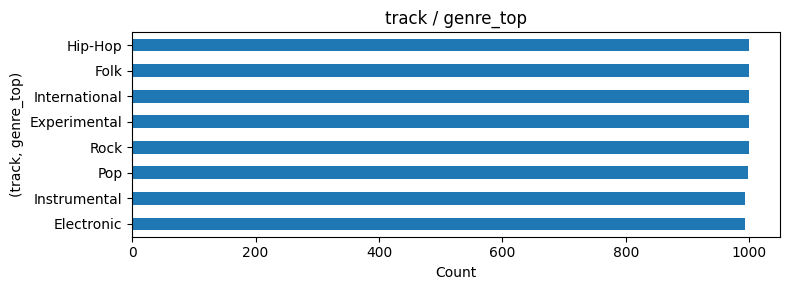

=== set / split (missing: 0 / 0.0%) ===
(set, split)
training      0.801
validation    0.100
test          0.099
Name: proportion, dtype: float64



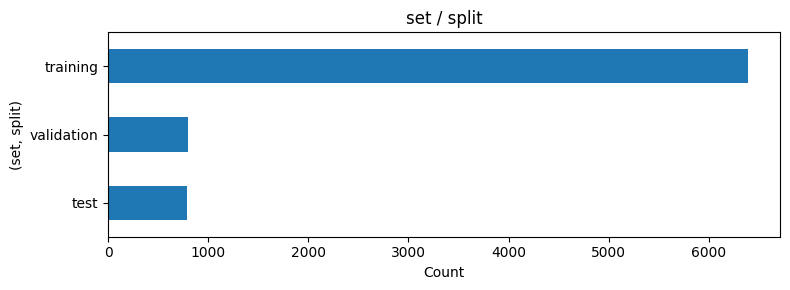

In [17]:
# Categorical: Target Label & Dataset Split
cat_cols = [
    ('track', 'genre_top'),
    ('set', 'split'),
]

for col in cat_cols:
    print(f"=== {' / '.join(col)} (missing: {clean_tracks[col].isna().sum()} / {clean_tracks[col].isna().mean()*100:.1f}%) ===")
    print(clean_tracks[col].value_counts(normalize=True).round(3).head(15))
    print()
    clean_tracks[col].value_counts().head(15).plot.barh(figsize=(8, 3))
    plt.title(" / ".join(col))
    plt.xlabel("Count")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

**Observations (V.1):**
- **`track / genre_top`**: All 8 top-level genres are virtually balanced at ~12.4–12.5% each (0 missing values, 0 rare levels), making this an ideal multi-class classification target that requires no resampling or class-weight adjustments.
- **`set / split`**: The official benchmark partition is cleanly divided into 80.1% `training`, 10.0% `validation`, and 9.9% `test` (0 missing values), providing a standardized split for model training, hyperparameter tuning, and unbiased evaluation.

## **V.2 Audio File Technical Context (`clean_tracks`)**

Inspects `track / bit_rate` (since MP3 compression can alter high-frequency spectral features) and `track / duration` (confirming original track lengths before FMA's 30-second audio clipping).

count        mean        std       min       25%       50%  \
track bit_rate  7983.0  265391.509  60903.055  105237.0  214011.5  262289.0   
      duration  7983.0     228.849     98.432      60.0     161.0     215.0   

                     75%       max   skew  
track bit_rate  320000.0  322541.0 -0.722  
      duration     279.0     600.0  0.940

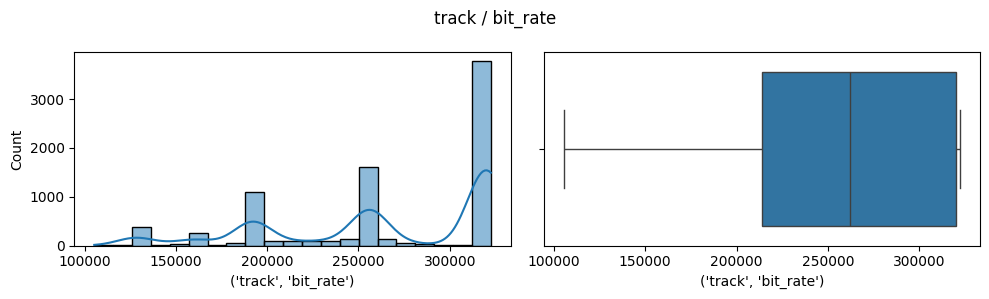

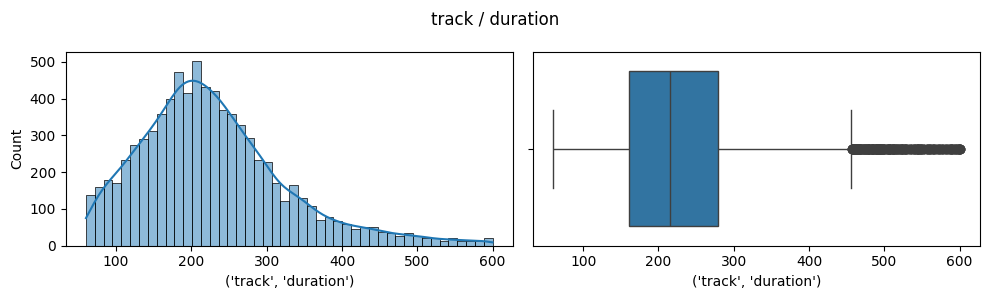

In [18]:
# Numeric: Audio File Technical Context
num_cols = [
    ('track', 'bit_rate'),
    ('track', 'duration'),
]

display(clean_tracks[num_cols].describe().T.assign(skew=clean_tracks[num_cols].skew()).round(3))

for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    sns.histplot(clean_tracks[col], kde=True, ax=axes[0])
    sns.boxplot(x=clean_tracks[col], ax=axes[1])
    fig.suptitle(" / ".join(col))
    plt.tight_layout()
    plt.show()

**Observations (V.2):**
- **`track / bit_rate`**: Bit rate is moderately left-skewed (`skew = -0.72`), clustering near standard high-quality MP3 encodings with a median of 262.3 kbps (mean = 265.4 kbps, SD = 60.9 kbps, IQR = 106.0 kbps from 214.0 to 320.0 kbps). Values span 105.2 to 322.5 kbps with zero IQR outliers and discrete spikes at standard bit rates (128, 192, 256, and 320 kbps), meaning most tracks have high enough audio quality to preserve upper-frequency spectral features.
- **`track / duration`**: Full track duration is moderately right-skewed (`skew = 0.94`); the median of 215 s (~3.6 min; IQR = 118 s, 161–279 s) is a slightly better summary of center than the mean of 228.8 s (SD = 98.4 s). All cleaned tracks are at least 60 s long (well above FMA-Small's 30 s clip length), with 270 upper-tail outliers (3.4%) extending up to 600 s.

## **V.3 Spectral Shape & Brightness (`clean_features`)**

Examines primary `mean / 01` frequency-domain descriptors: `spectral_centroid` (brightness), `spectral_bandwidth` (frequency spread), `spectral_rolloff` (high-frequency cutoff), and `spectral_contrast` (peak-to-valley spectral separation).

,,,count,mean,std,min,25%,50%,75%,max,skew
feature,statistics,number,,,,,,,,,
spectral_centroid,mean,01,7983.0,1175.064,501.726,140.754,818.903,1125.441,1460.532,5575.108,1.038
spectral_bandwidth,mean,01,7983.0,1420.851,440.942,241.755,1119.570,1410.866,1700.045,3789.372,0.316
spectral_rolloff,mean,01,7983.0,2371.575,1112.917,167.247,1566.877,2262.460,3041.472,9401.771,0.796
spectral_contrast,mean,01,7983.0,20.587,3.392,10.350,18.274,20.262,22.533,38.504,0.675


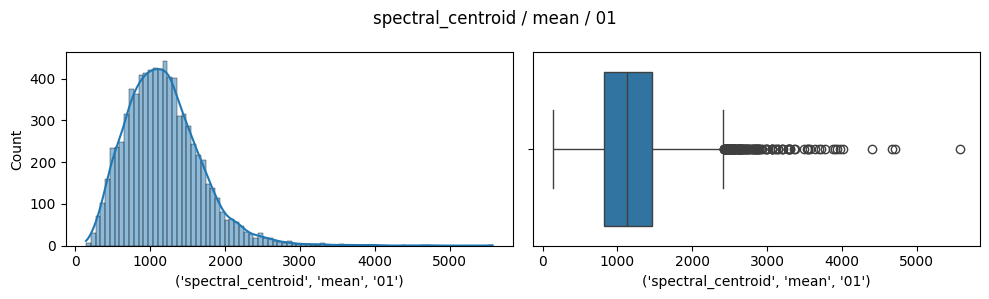

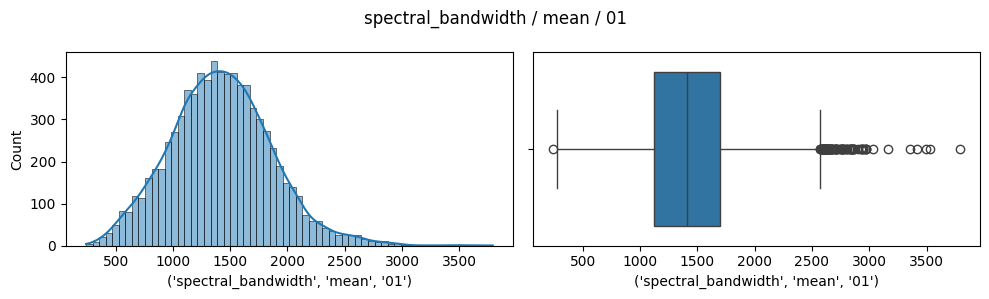

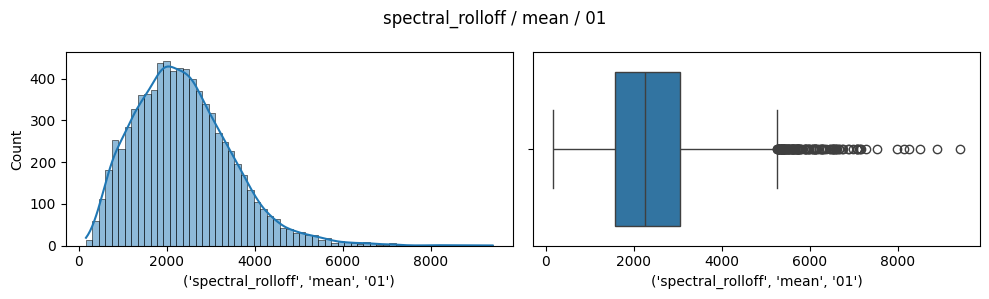

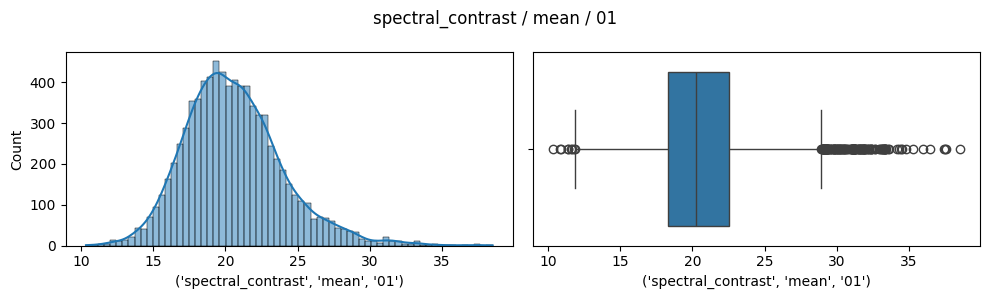

In [19]:
# Numeric: Spectral Shape & Brightness
num_cols = [
    ('spectral_centroid', 'mean', '01'),
    ('spectral_bandwidth', 'mean', '01'),
    ('spectral_rolloff', 'mean', '01'),
    ('spectral_contrast', 'mean', '01'),
]

display(clean_features[num_cols].describe().T.assign(skew=clean_features[num_cols].skew()).round(3))

for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    sns.histplot(clean_features[col], kde=True, ax=axes[0])
    sns.boxplot(x=clean_features[col], ax=axes[1])
    fig.suptitle(" / ".join(col))
    plt.tight_layout()
    plt.show()

**Observations (V.3):**
- **`spectral_centroid / mean / 01`**: Mean spectral centroid is heavily right-skewed (`skew = 1.04`); the median of 1,125.4 Hz (IQR = 641.6 Hz) is slightly more robust than the mean of 1,175.1 Hz (SD = 501.7 Hz). Values span 140.8 to 5,575.1 Hz with 152 upper-tail outliers (1.9%) reflecting unusually bright, high-frequency tracks.
- **`spectral_bandwidth / mean / 01`**: Mean spectral bandwidth is approximately symmetric (`skew = 0.32`), so the mean (1,420.9 Hz, SD = 440.9 Hz) and median (1,410.9 Hz, IQR = 580.5 Hz) agree closely. Values range from 241.8 to 3,789.4 Hz with only 93 IQR outliers (1.2%, nearly all upper-tail).
- **`spectral_rolloff / mean / 01`**: Mean spectral rolloff is moderately right-skewed (`skew = 0.80`), with a median of 2,262.5 Hz (IQR = 1,474.6 Hz) slightly below the mean of 2,371.6 Hz (SD = 1,112.9 Hz). Values span 167.2 to 9,401.8 Hz, including 132 upper-tail outliers (1.7%) driven by high-frequency content.
- **`spectral_contrast / mean / 01`**: Mean spectral contrast is moderately right-skewed (`skew = 0.67`), centered around a median of 20.26 (IQR = 4.26) and a mean of 20.59 (SD = 3.39). Values range from 10.35 to 38.50 with 158 IQR outliers (2.0%; 9 low, 149 high), marking tracks with sharper harmonic peaks relative to background noise.

## **V.4 Timbre / MFCCs (`clean_features`)**

Inspects the first four Mel-Frequency Cepstral Coefficient means (`mfcc / mean / 01`–`04`), which capture overall spectral energy (`01`) and the core timbral spectral envelope (`02`–`04`)—typically the highest-importance feature family in music genre classification.

count     mean     std      min      25%      50%  \
feature statistics number                                                       
mfcc    mean       01      7983.0 -202.492  93.799 -985.114 -258.302 -191.371   
                   02      7983.0  146.495  31.802  -18.084  126.392  146.334   
                   03      7983.0  -11.212  29.901 -146.494  -30.105  -12.393   
                   04      7983.0   30.264  17.185  -68.000   21.173   31.741   

                               75%      max   skew  
feature statistics number                           
mfcc    mean       01     -136.644  138.372 -0.680  
                   02      166.384  268.769 -0.056  
                   03        6.250  117.980  0.218  
                   04       41.250  125.015 -0.661

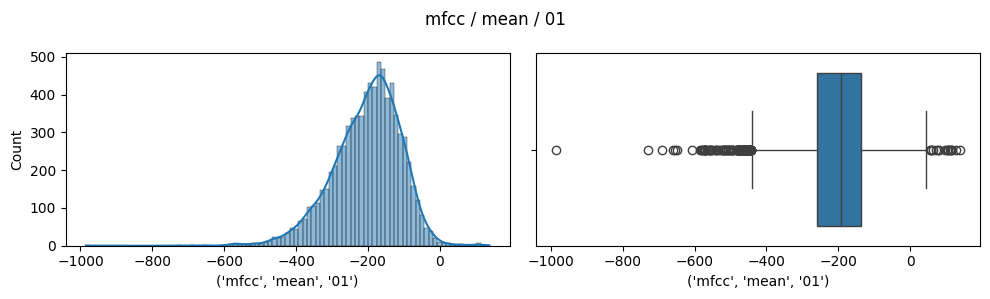

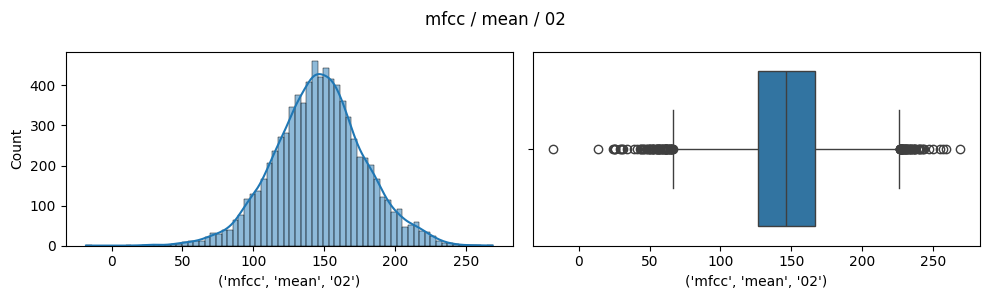

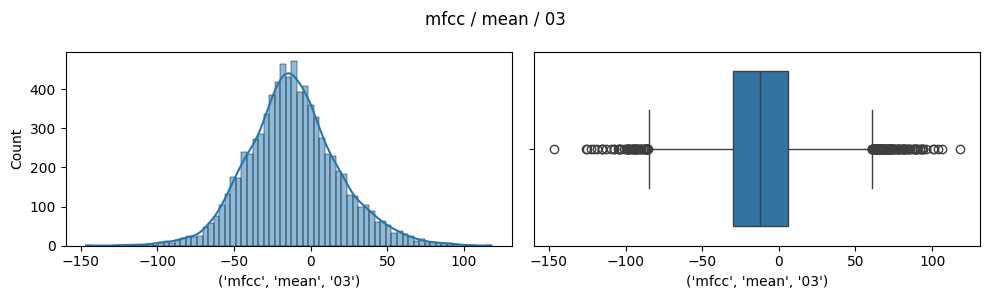

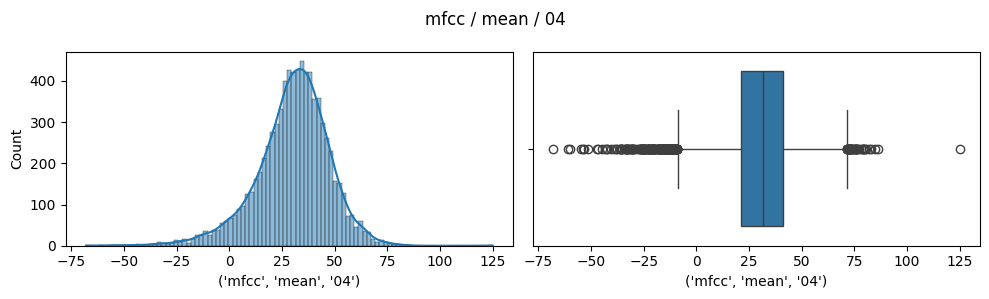

In [20]:
# Numeric: Timbre / MFCCs
num_cols = [
    ('mfcc', 'mean', '01'),
    ('mfcc', 'mean', '02'),
    ('mfcc', 'mean', '03'),
    ('mfcc', 'mean', '04'),
]

display(clean_features[num_cols].describe().T.assign(skew=clean_features[num_cols].skew()).round(3))

for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    sns.histplot(clean_features[col], kde=True, ax=axes[0])
    sns.boxplot(x=clean_features[col], ax=axes[1])
    fig.suptitle(" / ".join(col))
    plt.tight_layout()
    plt.show()

**Observations (V.4):**
- **`mfcc / mean / 01`**: The first MFCC mean (overall spectral energy) is moderately left-skewed (`skew = -0.68`); the median of -191.4 (IQR = 121.7) is slightly higher than the mean of -202.5 (SD = 93.8). Values span -985.1 to 138.4 with 131 IQR outliers (1.6%; 114 low, 17 high), where extreme negative values correspond to quiet or sparse audio.
- **`mfcc / mean / 02`**: The second MFCC mean (broad low-to-high spectral slope) is nearly symmetric (`skew = -0.06`), with virtually identical mean (146.5, SD = 31.8) and median (146.3, IQR = 40.0). Values range from -18.1 to 268.8 with only 122 balanced IQR outliers (1.5%; 69 low, 53 high).
- **`mfcc / mean / 03`**: The third MFCC mean is approximately symmetric (`skew = 0.22`), centered near -12.4 (median; IQR = 36.4) and -11.2 (mean; SD = 29.9). Values span -146.5 to 118.0 with 185 IQR outliers (2.3%; 64 low, 121 high).
- **`mfcc / mean / 04`**: The fourth MFCC mean is moderately left-skewed (`skew = -0.66`); the median of 31.7 (IQR = 20.1) is slightly above the mean of 30.3 (SD = 17.2). Values span -68.0 to 125.0 with 254 IQR outliers (3.2%; 214 low, 40 high), showing a heavier lower tail than `mfcc 02` and `03`.

## **V.5 Energy, Percussion & Harmony (`clean_features`)**

Evaluates loudness (`rmse`), percussiveness/noisiness (`zcr`), pitch-class energy (`chroma_cens`), and tonal centroid (`tonnetz`) via their primary `mean / 01` descriptors.

,,,count,mean,std,min,25%,50%,75%,max,skew
feature,statistics,number,,,,,,,,,
rmse,mean,01,7983.0,4.565,2.478,0.000,2.734,4.283,6.008,21.608,1.336
zcr,mean,01,7983.0,0.051,0.028,0.003,0.032,0.046,0.063,0.630,3.477
chroma_cens,mean,01,7983.0,0.251,0.082,0.004,0.200,0.250,0.299,0.706,0.368
tonnetz,mean,01,7983.0,0.001,0.014,-0.095,-0.006,0.001,0.009,0.077,0.020


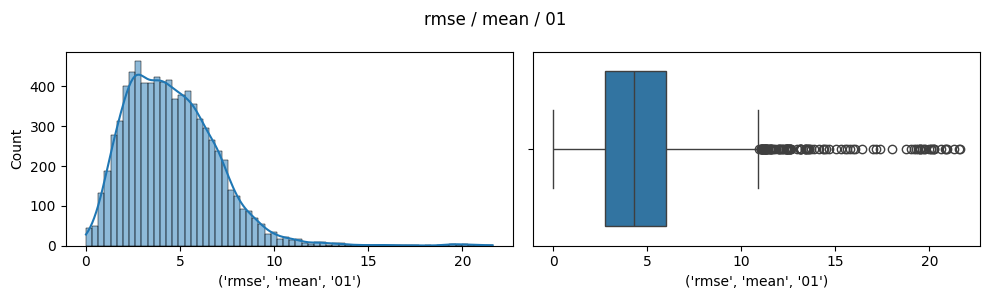

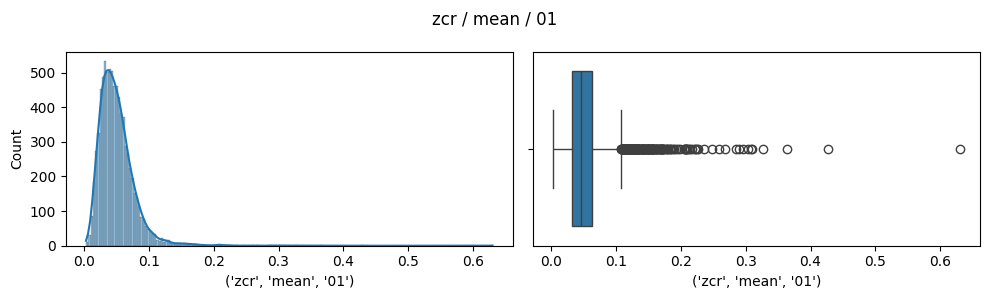

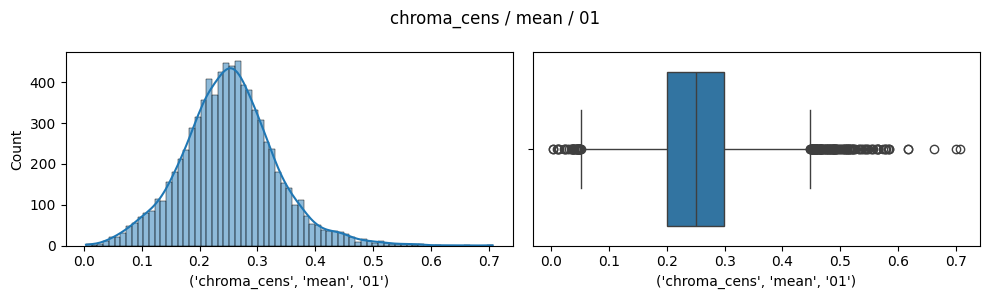

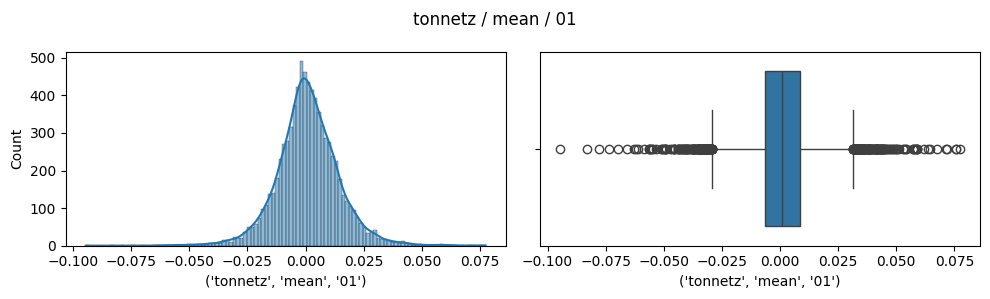

In [21]:
# Numeric: Energy, Percussion & Harmony
num_cols = [
    ('rmse', 'mean', '01'),
    ('zcr', 'mean', '01'),
    ('chroma_cens', 'mean', '01'),
    ('tonnetz', 'mean', '01'),
]

display(clean_features[num_cols].describe().T.assign(skew=clean_features[num_cols].skew()).round(3))

for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    sns.histplot(clean_features[col], kde=True, ax=axes[0])
    sns.boxplot(x=clean_features[col], ax=axes[1])
    fig.suptitle(" / ".join(col))
    plt.tight_layout()
    plt.show()

**Observations (V.5):**
- **`rmse / mean / 01`**: Mean root-mean-square energy (loudness) is heavily right-skewed (`skew = 1.34`), with a median of 4.28 (IQR = 3.27) below the mean of 4.57 (SD = 2.48). Values span near-silence (0.000) to 21.61, with 113 upper-tail outliers (1.4%) representing unusually loud or heavily compressed tracks.
- **`zcr / mean / 01`**: Mean zero-crossing rate is heavily right-skewed (`skew = 3.48`); the median of 0.046 (IQR = 0.030) is a better summary than the mean of 0.051 (SD = 0.028). Values extend from 0.003 to 0.630 with 244 upper-tail outliers (3.1%) marking highly percussive, distorted, or noisy audio.
- **`chroma_cens / mean / 01`**: Mean chroma energy is approximately symmetric (`skew = 0.37`), with closely matching mean (0.251, SD = 0.082) and median (0.250, IQR = 0.099). It spans 0.004 to 0.706 with 183 IQR outliers (2.3%; 41 low, 142 high).
- **`tonnetz / mean / 01`**: Mean tonal centroid is tightly symmetric around zero (`skew = 0.02`; mean = 0.001, median = 0.001, SD = 0.014, IQR = 0.015). Despite clean centering, it shows moderately heavy tails with 280 symmetric IQR outliers (3.5%; 138 low, 142 high) spanning -0.095 to 0.077.

## **V.6 Temporal Variability (`clean_features`)**

Inspects frame-level standard deviation (`std / 01`) across loudness, spectral brightness, noisiness, and timbre to capture how much a track's acoustic properties fluctuate across its 30-second clip.

,,,count,mean,std,min,25%,50%,75%,max,skew
feature,statistics,number,,,,,,,,,
rmse,std,01,7983.0,2.197,1.023,0.000,1.435,2.077,2.820,8.914,0.768
spectral_centroid,std,01,7983.0,604.842,278.979,55.690,400.998,569.971,758.585,3023.301,1.126
zcr,std,01,7983.0,0.040,0.026,0.003,0.023,0.034,0.051,0.318,2.080
mfcc,std,01,7983.0,82.711,22.171,8.798,67.493,81.895,96.674,236.649,0.347


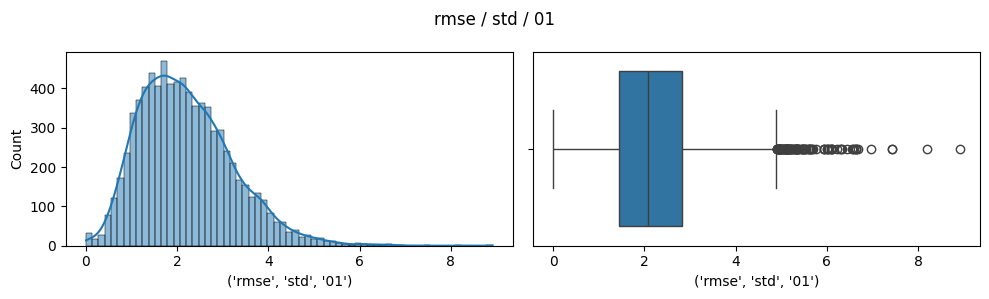

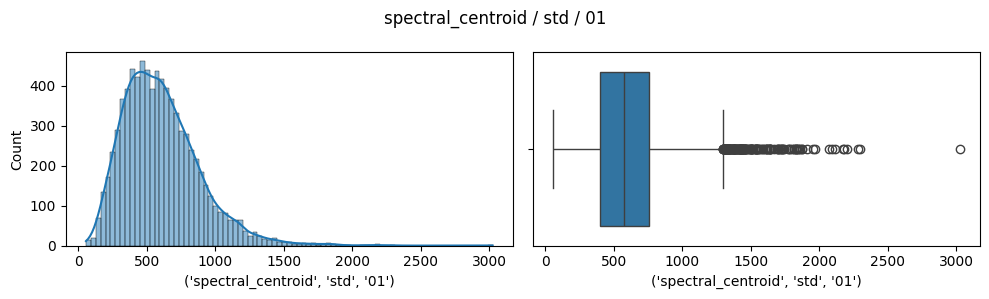

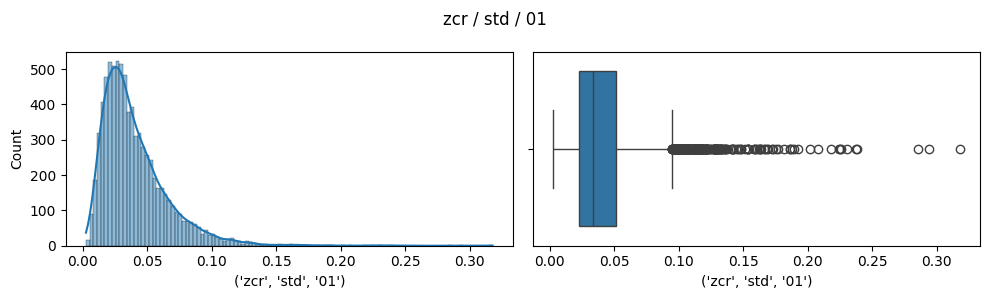

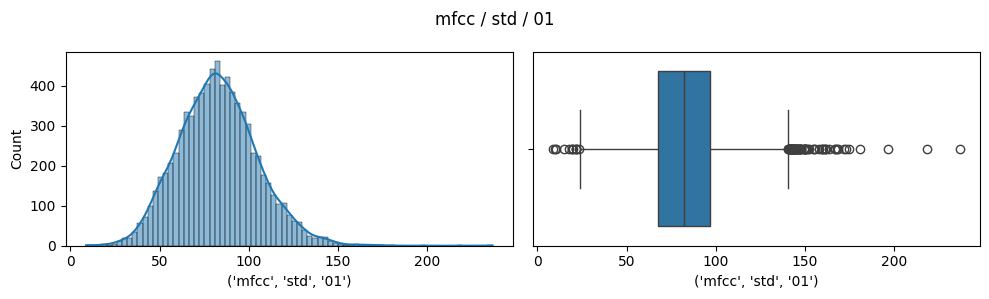

In [22]:
# Numeric: Temporal Variability (std)
num_cols = [
    ('rmse', 'std', '01'),
    ('spectral_centroid', 'std', '01'),
    ('zcr', 'std', '01'),
    ('mfcc', 'std', '01'),
]

display(clean_features[num_cols].describe().T.assign(skew=clean_features[num_cols].skew()).round(3))

for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    sns.histplot(clean_features[col], kde=True, ax=axes[0])
    sns.boxplot(x=clean_features[col], ax=axes[1])
    fig.suptitle(" / ".join(col))
    plt.tight_layout()
    plt.show()

**Observations (V.6):**
- **`rmse / std / 01`**: Loudness variability is moderately right-skewed (`skew = 0.77`), with a median of 2.08 (IQR = 1.39) slightly below the mean of 2.20 (SD = 1.02). Values span 0.000 to 8.91 with 105 upper-tail outliers (1.3%), distinguishing tracks with sharp dynamic swings from steadily compressed tracks.
- **`spectral_centroid / std / 01`**: Brightness variability is heavily right-skewed (`skew = 1.13`); the median of 570.0 Hz (IQR = 357.6 Hz) is a better summary than the mean of 604.8 Hz (SD = 279.0 Hz). Values range from 55.7 to 3,023.3 Hz with 167 upper-tail outliers (2.1%) reflecting abrupt timbral shifts.
- **`zcr / std / 01`**: Zero-crossing rate variability is heavily right-skewed (`skew = 2.08`); the median of 0.034 (IQR = 0.029) better represents typical tracks than the mean of 0.040 (SD = 0.026). Values reach up to 0.318 with 310 upper-tail outliers (3.9%), capturing intermittent bursts of percussion or noise.
- **`mfcc / std / 01`**: First-MFCC variability is approximately symmetric (`skew = 0.35`), with closely matching mean (82.7, SD = 22.2) and median (81.9, IQR = 29.2). Values span 8.8 to 236.6 with only 88 IQR outliers (1.1%; 12 low, 76 high).

---

### **Key Takeaways for Audio-Feature Data Mining**
- **No Class-Imbalance Correction Needed**: `track / genre_top` is evenly balanced across all 8 genres (~12.5% each), and `set / split` provides a ready-to-use 80/10/10 benchmark partition.
- **Feature Scaling Is Essential**: Audio features span **6 orders of magnitude**—from `tonnetz / mean / 01` (~0.001) and `zcr / mean / 01` (~0.05) up to `spectral_rolloff / mean / 01` (~2,372)—so distance-, margin-, and gradient-based models (KNN, SVM, Logistic Regression, Neural Networks, PCA) require `StandardScaler` or `RobustScaler`.
- **Right-Skewed Features & Outliers**: Several acoustic predictors (`zcr`, `rmse`, `spectral_centroid`, and their `std` counterparts) exhibit right-skewness (`skew = 1.0–3.5`) with 1–4% upper-tail outliers; tree-based models (Random Forest, Gradient Boosting/XGBoost) handle these natively, while linear/distance-based models will benefit from power/log transforms or robust scaling.

# **VI. Bivariate and multivariate analysis**

To investigate **the importance of audio features in music genre classification using data mining techniques**, this section moves beyond single-variable distributions to examine how acoustic descriptors relate to one another and how effectively they separate the 8 genres in `track / genre_top`. Specifically, we test for non-acoustic technical confounds across genres, audit feature-to-feature multicollinearity across all 518 `librosa` descriptors, compare acoustic profiles across genres, rank feature and feature-family importance using complementary statistical and data-mining methods (computed strictly on the `training` split to prevent data leakage), and explore multivariate genre separability using Principal Component Analysis (PCA).

- **VI.1 Technical Confound & Split Stratification Check (`clean_tracks`)**
- **VI.2 Feature-to-Feature Correlation & Multicollinearity (`clean_features`)**
- **VI.3 Acoustic Feature Profiles Across Genres (`clean_features` × `genre_top`)**
- **VI.4 Data-Mining Feature Importance Across All 518 Descriptors (`training` split)**
- **VI.5 Multivariate Structure & Genre Separability via PCA (`clean_features`)**
- **Key Takeaways for Feature Importance & Genre Classification**

## **VI.1 Technical Confound & Split Stratification Check (`clean_tracks`)**

Verifies that genre balance holds across the official `training`, `validation`, and `test` splits (`track / genre_top` × `set / split`), and tests whether technical file attributes (`track / bit_rate` and `track / duration`) vary systematically by genre—which would signal non-acoustic confounds if left unchecked.

=== Genre x Official Split Contingency Table ===


"(set, split)",training,validation,test,Total
"(track, genre_top)",,,,
Electronic,798,100,95,993
Experimental,799,100,100,999
Folk,800,100,100,1000
Hip-Hop,800,100,100,1000
Instrumental,797,100,97,994
International,800,100,100,1000
Pop,798,100,100,998
Rock,799,100,100,999


Chi-square test of independence: chi2 = 0.219, dof = 14, p = 1.0000

=== Bit Rate (kbps) medians by genre (Kruskal-Wallis H=424.43, p=1.37e-87, eta2_H=0.0523) ===
genre
Electronic       320.0
Hip-Hop          320.0
Instrumental     320.0
Pop              265.2
Experimental     259.6
Folk             256.0
International    256.0
Rock             256.0 

=== Original Track Duration (s) medians by genre (Kruskal-Wallis H=285.62, p=7.09e-58, eta2_H=0.0349) ===
genre
Electronic       243.0
International    239.0
Folk             222.0
Pop              214.0
Rock             213.0
Experimental     208.0
Hip-Hop          201.0
Instrumental     190.0 



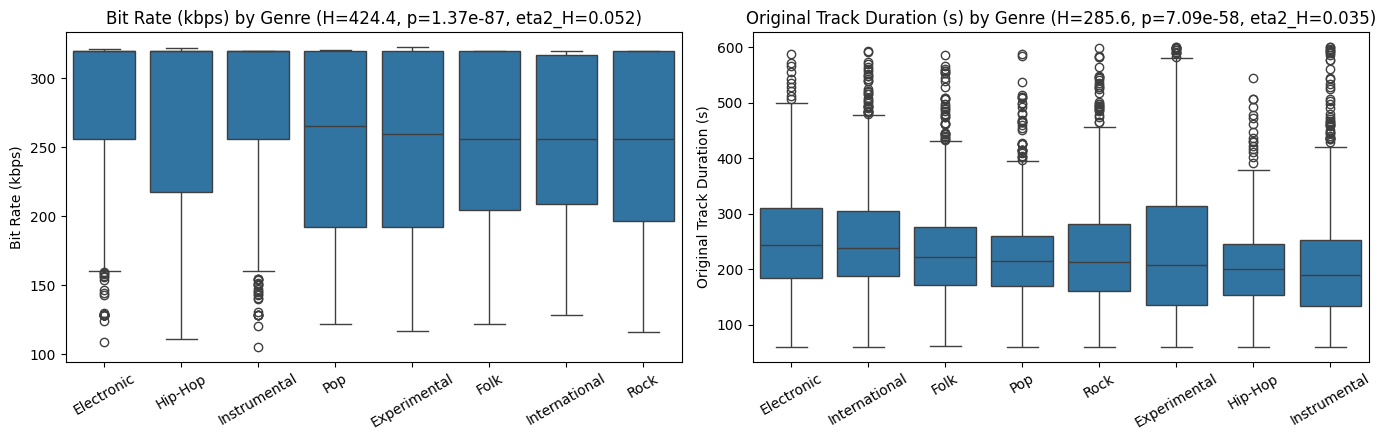

In [29]:
# VI.1 Split Stratification & Technical Confound Check
genre = clean_tracks[('track', 'genre_top')]
split = clean_tracks[('set', 'split')]

# 1. Contingency table: Genre vs. Official Split
ct = pd.crosstab(genre, split)[['training', 'validation', 'test']]
chi2, p_chi2, dof, _ = stats.chi2_contingency(ct)
print("=== Genre x Official Split Contingency Table ===")
display(ct.assign(Total=ct.sum(axis=1)))
print(f"Chi-square test of independence: chi2 = {chi2:.3f}, dof = {dof}, p = {p_chi2:.4f}\n")

# 2. Technical attributes across genres (Kruskal-Wallis + Boxplots)
tech_cols = [('track', 'bit_rate'), ('track', 'duration')]
tech_df = pd.DataFrame({
    'genre': genre,
    'bit_rate_kbps': clean_tracks[('track', 'bit_rate')] / 1000.0,
    'duration_sec': clean_tracks[('track', 'duration')],
})

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (col_name, label) in zip(axes, [('bit_rate_kbps', 'Bit Rate (kbps)'), ('duration_sec', 'Original Track Duration (s)')]):
    groups = [grp[col_name].values for _, grp in tech_df.groupby('genre')]
    H, p_kw = stats.kruskal(*groups)
    n = len(tech_df)
    k = len(groups)
    eta2_h = max(0.0, (H - k + 1) / (n - k))
    order = tech_df.groupby('genre')[col_name].median().sort_values(ascending=False).index
    sns.boxplot(data=tech_df, x='genre', y=col_name, order=order, ax=ax)
    ax.set_title(f"{label} by Genre (H={H:.1f}, p={p_kw:.2e}, eta2_H={eta2_h:.3f})")
    ax.set_xlabel("")
    ax.set_ylabel(label)
    ax.tick_params(axis='x', rotation=30)
    medians = tech_df.groupby('genre')[col_name].median().loc[order].round(1)
    print(f"=== {label} medians by genre (Kruskal-Wallis H={H:.2f}, p={p_kw:.2e}, eta2_H={eta2_h:.4f}) ===")
    print(medians.to_string(), "\n")

plt.tight_layout()
plt.show()

**Observations (VI.1):**
- **Split Stratification (`genre_top` × `set / split`)**: Class balance remains intact across all three partitions after removing the 17 duplicate rows—797–800 `training`, exactly 100 `validation`, and 95–100 `test` tracks per genre ($\chi^2 = 0.219$, $\text{dof} = 14$, $p = 1.0000$). No resampling or re-splitting is needed.
- **Bit Rate Confound (`track / bit_rate` by genre)**: Bit rate differs significantly across genres with a small-to-moderate effect ($H = 424.43$, $p = 1.37 \times 10^{-87}$, $\eta^2_H = 0.052$). Electronic, Hip-Hop, and Instrumental tracks have a higher median encoding (320.0 kbps) than Folk, International, and Rock (256.0 kbps). While all genre medians are $\ge 256$ kbps (preserving most audible high-frequency content), this confirms **`bit_rate` must be excluded from model features** to prevent encoding-bias leakage.
- **Original Duration (`track / duration` by genre)**: Full track length varies modestly by genre ($H = 285.62$, $p = 7.09 \times 10^{-58}$, $\eta^2_H = 0.035$), with Electronic (243 s) and International (239 s) longest and Instrumental (190 s) and Hip-Hop (201 s) shortest. Excluding `duration` keeps classification strictly anchored on the standardized 30-second `librosa` audio features.

## **VI.2 Feature-to-Feature Correlation & Multicollinearity (`clean_features`)**

Inspects pairwise relationships among the 16 representative audio features from Section V (using Spearman rank correlation to handle skewness and outliers robustly), and audits redundancy across all 518 `librosa` descriptors to diagnose multicollinearity before feature selection and modeling.

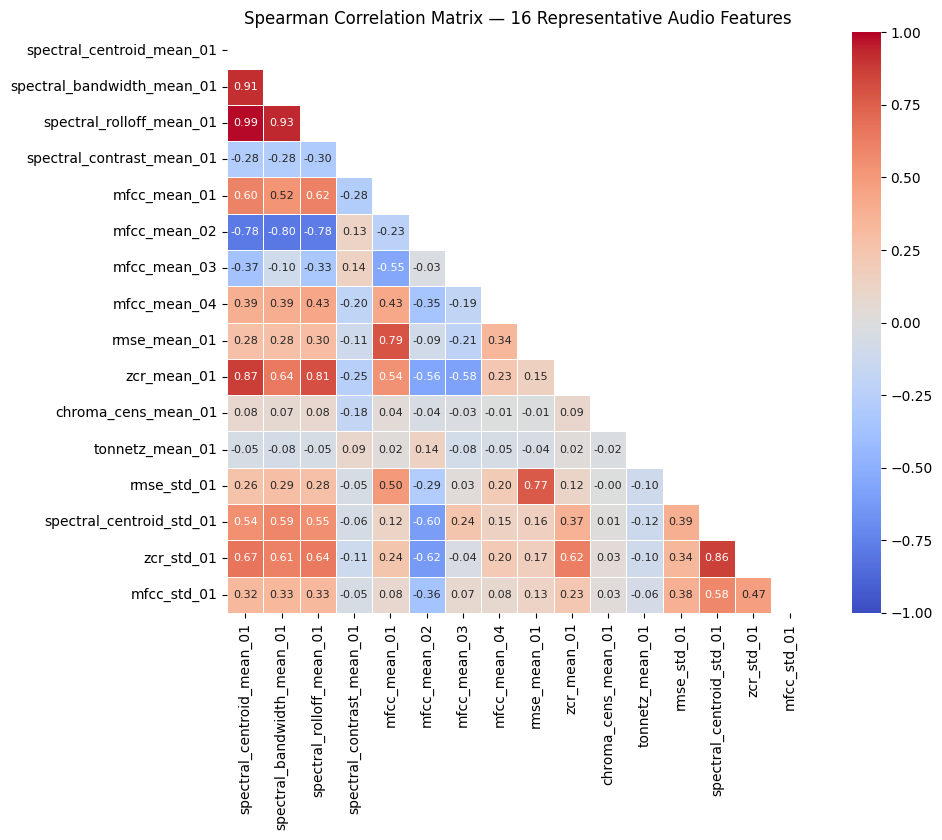

=== Top 10 Strongest Pairwise Correlations (16 Representative Features, Spearman) ===


,Feature A,Feature B,spearman_r
1,spectral_centroid_mean_01,spectral_rolloff_mean_01,0.988
15,spectral_bandwidth_mean_01,spectral_rolloff_mean_01,0.935
0,spectral_centroid_mean_01,spectral_bandwidth_mean_01,0.915
8,spectral_centroid_mean_01,zcr_mean_01,0.868
117,spectral_centroid_std_01,zcr_std_01,0.860
35,spectral_rolloff_mean_01,zcr_mean_01,0.811
18,spectral_bandwidth_mean_01,mfcc_mean_02,-0.795
57,mfcc_mean_01,rmse_mean_01,0.792
4,spectral_centroid_mean_01,mfcc_mean_02,-0.783
31,spectral_rolloff_mean_01,mfcc_mean_02,-0.780



=== Full 518-Feature Multicollinearity Audit (Pearson |r|) ===
Total unique feature pairs : 133,903
Pairs with |r| >= 0.85     : 248 (0.19%)
Pairs with |r| >= 0.90     : 164 (0.12%)
Pairs with |r| >= 0.95     : 80 (0.06%)
Features with >=1 partner at |r| >= 0.85: 204 / 518 (39.4%)

=== Features with at Least One |r| >= 0.85 Partner, by Feature Family ===


,total_features,collinear_features_r85,pct_collinear
feature,,,
spectral_centroid,7,5,71.4
spectral_rolloff,7,5,71.4
chroma_stft,84,50,59.5
spectral_bandwidth,7,4,57.1
chroma_cqt,84,37,44.0
zcr,7,3,42.9
rmse,7,3,42.9
mfcc,140,47,33.6
chroma_cens,84,24,28.6


In [30]:
# VI.2 Feature-to-Feature Correlation & Full-Dataset Multicollinearity Audit
rep_cols = [
    ('spectral_centroid', 'mean', '01'),
    ('spectral_bandwidth', 'mean', '01'),
    ('spectral_rolloff', 'mean', '01'),
    ('spectral_contrast', 'mean', '01'),
    ('mfcc', 'mean', '01'),
    ('mfcc', 'mean', '02'),
    ('mfcc', 'mean', '03'),
    ('mfcc', 'mean', '04'),
    ('rmse', 'mean', '01'),
    ('zcr', 'mean', '01'),
    ('chroma_cens', 'mean', '01'),
    ('tonnetz', 'mean', '01'),
    ('rmse', 'std', '01'),
    ('spectral_centroid', 'std', '01'),
    ('zcr', 'std', '01'),
    ('mfcc', 'std', '01'),
]
rep_labels = [f"{a}_{b}_{c}" for a, b, c in rep_cols]
rep_df = clean_features[rep_cols].copy()
rep_df.columns = rep_labels

# 1. Spearman correlation heatmap of the 16 representative features
corr_spearman = rep_df.corr(method='spearman')
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(11, 8.5))
sns.heatmap(
    corr_spearman,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.4,
    annot_kws={'size': 8},
)
plt.title("Spearman Correlation Matrix — 16 Representative Audio Features")
plt.tight_layout()
plt.show()

# Top correlated pairs among representative features
upper_rep = corr_spearman.where(np.triu(np.ones(corr_spearman.shape), k=1).astype(bool))
rep_pairs = (
    upper_rep.stack()
    .rename('spearman_r')
    .reset_index()
    .rename(columns={'level_0': 'Feature A', 'level_1': 'Feature B'})
)
rep_pairs['abs_r'] = rep_pairs['spearman_r'].abs()
print("=== Top 10 Strongest Pairwise Correlations (16 Representative Features, Spearman) ===")
display(rep_pairs.sort_values('abs_r', ascending=False).head(10)[['Feature A', 'Feature B', 'spearman_r']].round(3))

# 2. Full 518-feature multicollinearity audit (Pearson |r|)
full_corr = clean_features.corr(method='pearson').abs()
upper_mask = np.triu(np.ones(full_corr.shape, dtype=bool), k=1)
vals = full_corr.values[upper_mask]
total_pairs = len(vals)
n_85 = int((vals >= 0.85).sum())
n_90 = int((vals >= 0.90).sum())
n_95 = int((vals >= 0.95).sum())

# Features involved in at least one |r| >= 0.85 pair
adj = (full_corr.values >= 0.85).copy()
np.fill_diagonal(adj, False)
features_with_collinear = int(adj.any(axis=1).sum())

print(f"\n=== Full 518-Feature Multicollinearity Audit (Pearson |r|) ===")
print(f"Total unique feature pairs : {total_pairs:,}")
print(f"Pairs with |r| >= 0.85     : {n_85:,} ({n_85 / total_pairs * 100:.2f}%)")
print(f"Pairs with |r| >= 0.90     : {n_90:,} ({n_90 / total_pairs * 100:.2f}%)")
print(f"Pairs with |r| >= 0.95     : {n_95:,} ({n_95 / total_pairs * 100:.2f}%)")
print(f"Features with >=1 partner at |r| >= 0.85: {features_with_collinear} / {clean_features.shape[1]} ({features_with_collinear / clean_features.shape[1] * 100:.1f}%)")

# Breakdown of highly collinear features by feature family
families = clean_features.columns.get_level_values(0)
fam_summary = pd.DataFrame({
    'total_features': pd.Series(families).value_counts(),
    'collinear_features_r85': pd.Series(families[adj.any(axis=1)]).value_counts(),
}).fillna(0).astype(int)
fam_summary['pct_collinear'] = (fam_summary['collinear_features_r85'] / fam_summary['total_features'] * 100).round(1)
print("\n=== Features with at Least One |r| >= 0.85 Partner, by Feature Family ===")
display(fam_summary.sort_values('pct_collinear', ascending=False))

**Observations (VI.2):**
- **Tight Spectral-Brightness Cluster**: `spectral_centroid / mean / 01`, `spectral_rolloff / mean / 01`, and `spectral_bandwidth / mean / 01` are nearly collinear ($\rho = 0.915\text{–}0.988$), and also correlate strongly with `zcr / mean / 01` ($\rho = 0.811\text{–}0.868$); their temporal variabilities (`spectral_centroid / std / 01` and `zcr / std / 01`) move together similarly ($\rho = 0.860$).
- **Meaningful Cross-Family Acoustic Links**: `mfcc / mean / 01` tracks loudness (`rmse / mean / 01`, $\rho = 0.792$), while `mfcc / mean / 02` (spectral slope) inversely tracks brightness and bandwidth ($\rho = -0.780$ to $-0.795$). By contrast, tonal/harmonic descriptors (`chroma_cens` and `tonnetz`) remain largely orthogonal to the spectral/loudness block, contributing independent musical information.
- **Substantial Redundancy Across All 518 Features**: Nearly **40% of all descriptors (204 / 518)** share $|r| \ge 0.85$ with at least one other feature (248 pairs at $|r| \ge 0.85$, 80 pairs at $|r| \ge 0.95$), concentrated most heavily in `spectral_centroid` (71.4%), `spectral_rolloff` (71.4%), `chroma_stft` (59.5%), and `spectral_bandwidth` (57.1%). For data mining, this means regularized models (Ridge/Lasso/SVM), PCA, or feature pruning are advisable—and individual tree importances may split credit across correlated siblings.

## **VI.3 Acoustic Feature Profiles Across Genres (`clean_features` × `genre_top`)**

Tests how strongly each of the 16 representative audio features differentiates the 8 genres using non-parametric Kruskal-Wallis $H$ tests and effect sizes ($\eta^2_H$), visualizes genre-level standardized acoustic signatures (z-score heatmap), and plots class-wise distributions for the top-discriminating features.

=== Kruskal-Wallis Genre Separation Across 16 Representative Features ===


,Feature,Kruskal_H,p_value,eta2_H
0,spectral_rolloff_mean_01,2158.3,0.000000e+00,0.2698
1,spectral_centroid_mean_01,2078.6,0.000000e+00,0.2598
2,mfcc_mean_01,2049.6,0.000000e+00,0.2561
3,spectral_bandwidth_mean_01,1741.9,0.000000e+00,0.2175
4,mfcc_mean_03,1580.3,0.000000e+00,0.1973
5,rmse_std_01,1568.5,0.000000e+00,0.1958
6,mfcc_mean_02,1516.1,0.000000e+00,0.1892
7,zcr_mean_01,1477.1,0.000000e+00,0.1843
8,rmse_mean_01,1345.3,2.641872e-286,0.1678
9,spectral_centroid_std_01,1320.2,7.249022e-281,0.1647


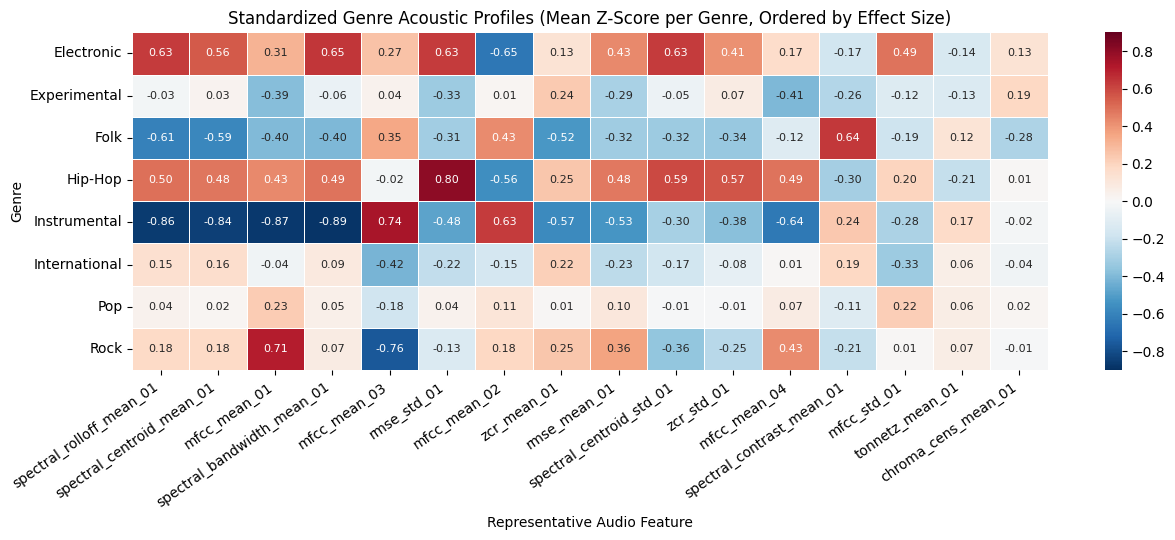

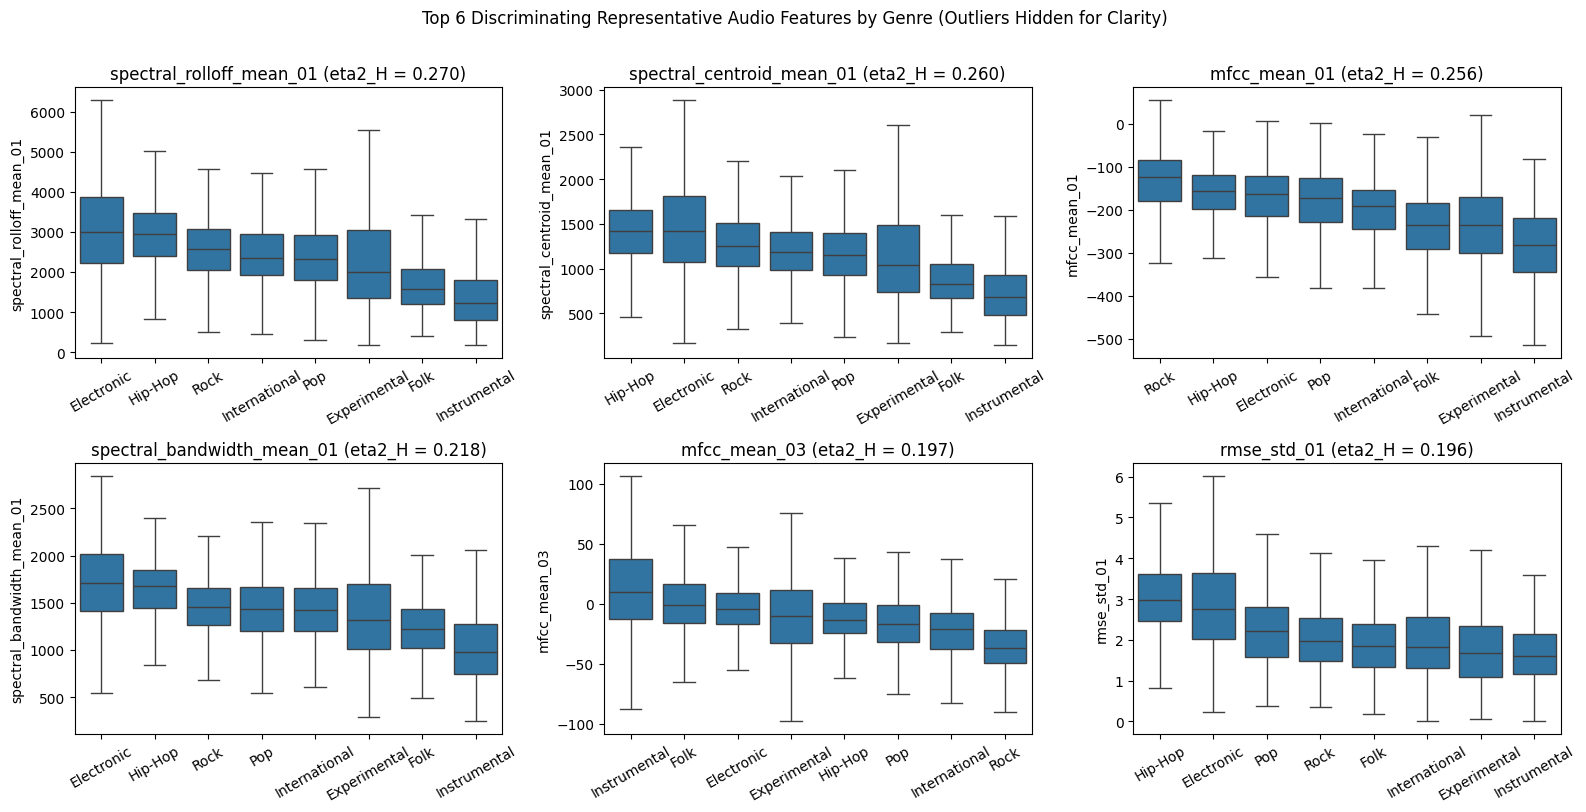

In [31]:
# VI.3 Bivariate Discrimination: Representative Audio Features vs. Genre
genre = clean_tracks[('track', 'genre_top')]

# 1. Kruskal-Wallis H test & effect size (eta^2_H) for the 16 representative features
kw_rows = []
n = len(rep_df)
k = genre.nunique()
for col in rep_df.columns:
    groups = [rep_df.loc[genre == g, col].values for g in sorted(genre.unique())]
    H, p = stats.kruskal(*groups)
    eta2_h = max(0.0, (H - k + 1) / (n - k))
    kw_rows.append({'Feature': col, 'Kruskal_H': H, 'p_value': p, 'eta2_H': eta2_h})

kw_df = pd.DataFrame(kw_rows).sort_values('eta2_H', ascending=False).reset_index(drop=True)
print("=== Kruskal-Wallis Genre Separation Across 16 Representative Features ===")
display(kw_df.assign(Kruskal_H=kw_df['Kruskal_H'].round(1), eta2_H=kw_df['eta2_H'].round(4)))

# 2. Standardized (z-score) genre acoustic profile heatmap
z_rep = (rep_df - rep_df.mean()) / rep_df.std()
z_rep['genre'] = genre.values
genre_profile = z_rep.groupby('genre')[kw_df['Feature'].tolist()].mean()

plt.figure(figsize=(13, 5.5))
sns.heatmap(
    genre_profile,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-0.9,
    vmax=0.9,
    linewidths=0.4,
    annot_kws={'size': 8},
)
plt.title("Standardized Genre Acoustic Profiles (Mean Z-Score per Genre, Ordered by Effect Size)")
plt.xlabel("Representative Audio Feature")
plt.ylabel("Genre")
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

# 3. Boxplots for the top 6 discriminating representative features
top6_feats = kw_df['Feature'].head(6).tolist()
plot_df = rep_df[top6_feats].copy()
plot_df['genre'] = genre.values

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, feat in zip(axes.flat, top6_feats):
    order = plot_df.groupby('genre')[feat].median().sort_values(ascending=False).index
    sns.boxplot(data=plot_df, x='genre', y=feat, order=order, showfliers=False, ax=ax)
    eta = kw_df.loc[kw_df['Feature'] == feat, 'eta2_H'].values[0]
    ax.set_title(f"{feat} (eta2_H = {eta:.3f})")
    ax.set_xlabel("")
    ax.tick_params(axis='x', rotation=30)

plt.suptitle("Top 6 Discriminating Representative Audio Features by Genre (Outliers Hidden for Clarity)", y=1.01)
plt.tight_layout()
plt.show()

**Observations (VI.3):**
- **Strongest Univariate Genre Separators**: Spectral shape, loudness/energy, and lower-order MFCCs produce large genre effects—led by `spectral_rolloff / mean / 01` ($\eta^2_H = 0.270$), `spectral_centroid / mean / 01` ($\eta^2_H = 0.260$), `mfcc / mean / 01` ($\eta^2_H = 0.256$), `spectral_bandwidth / mean / 01` ($\eta^2_H = 0.218$), `mfcc / mean / 03` ($\eta^2_H = 0.197$), and `rmse / std / 01` ($\eta^2_H = 0.196$). By contrast, single-index harmonic means (`tonnetz / mean / 01`, `chroma_cens / mean / 01`) show minimal standalone effect ($\eta^2_H \approx 0.017$) because individual pitch-class bins depend on musical key rather than genre.
- **Clear Genre Acoustic Fingerprints**:
  - **Instrumental & Folk**: Warm, darker, lower-energy profiles (negative spectral rolloff/centroid/bandwidth and `mfcc_mean_01`, positive `mfcc_mean_02`/`03`), with **Folk** standing out sharply on `spectral_contrast / mean / 01` ($z = +0.64$) due to clean acoustic harmonic peaks.
  - **Electronic & Hip-Hop**: High spectral brightness/bandwidth ($z = +0.48$ to $+0.65$) paired with high dynamic and timbral variability (`rmse_std_01`: $+0.80$ for Hip-Hop, $+0.63$ for Electronic; `spectral_centroid_std_01`: $+0.59$ to $+0.63$).
  - **Rock**: Highest overall loudness (`mfcc_mean_01` $z = +0.71$) and lowest `mfcc_mean_03` ($z = -0.76$), combined with *below-average* temporal brightness variability (`spectral_centroid_std_01` $z = -0.36$), reflecting sustained, dynamically compressed instrumentation.
- **Expected Hard-to-Classify Genres**: **Pop** hovers near zero ($|z| \le 0.23$) across all 16 features, and **Experimental** and **International** also overlap heavily near the global average—indicating that univariate rules cannot isolate these genres and that **multivariate, non-linear data mining models** across the broader feature set are essential.

## **VI.4 Data-Mining Feature Importance Across All 518 Descriptors (`training` split)**

Directly evaluates which audio features and acoustic families carry the highest predictive importance for music genre classification across all 518 `librosa` descriptors. To avoid data leakage into validation or test evaluation, all rankings are computed **strictly on the official `training` split** using three complementary data-mining lenses: **ANOVA F-statistic** (linear class separation), **Mutual Information** (non-linear dependency), and **Random Forest Gini Importance** (multivariate interaction importance).

=== Cross-Method Feature Ranking Agreement (Spearman rho across 518 features) ===


,anova_F,mutual_info,rf_importance
anova_F,1.000,0.872,0.742
mutual_info,0.872,1.000,0.750
rf_importance,0.742,0.750,1.000



=== Audio Feature Family Importance Summary (Training Split) ===


,n_features,rf_total_pct,rf_mean_x1e3,mean_anova_F,mean_MI
family,,,,,
mfcc,140,34.307,2.451,86.348,0.065
spectral_contrast,49,13.859,2.828,101.036,0.087
chroma_stft,84,11.741,1.398,56.010,0.054
chroma_cens,84,10.982,1.307,25.969,0.029
chroma_cqt,84,10.201,1.214,31.072,0.031
tonnetz,42,7.884,1.877,51.518,0.048
spectral_rolloff,7,2.514,3.592,118.934,0.131
spectral_centroid,7,2.373,3.390,115.398,0.121
spectral_bandwidth,7,2.200,3.143,99.850,0.103



=== Summary-Statistic Importance Breakdown (Training Split) ===


,n_features,rf_total_pct,rf_mean_x1e3,mean_anova_F,mean_MI
stat,,,,,
std,74,18.064,2.441,76.379,0.068
mean,74,17.259,2.332,96.775,0.070
median,74,17.154,2.318,97.165,0.078
skew,74,13.572,1.834,49.909,0.043
kurtosis,74,12.552,1.696,21.949,0.037
min,74,10.830,1.463,46.986,0.049
max,74,10.570,1.428,46.416,0.041


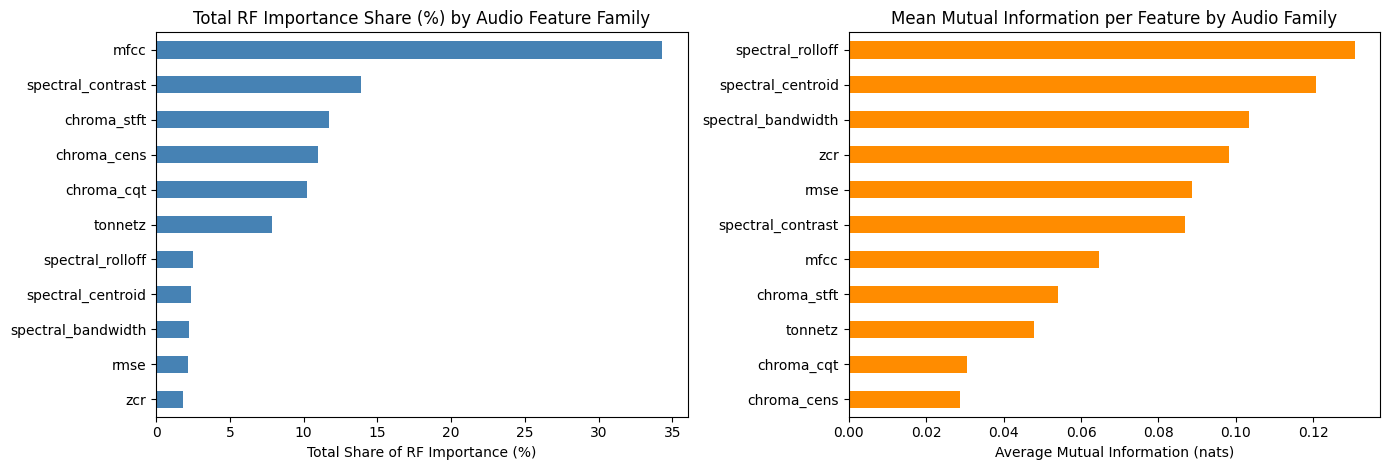


=== Top 20 Individual Audio Features (Consensus Across ANOVA F, MI, and RF) ===


,feature_name,anova_F,mutual_info,rf_importance,consensus_score
292,mfcc / mean / 01,305.9629,0.1902,0.0062,0.9374
312,mfcc / median / 01,305.0249,0.1856,0.0057,0.9071
465,spectral_rolloff / median / 01,227.3260,0.2118,0.0065,0.9029
464,spectral_rolloff / mean / 01,248.8488,0.1984,0.0060,0.8826
430,spectral_contrast / mean / 04,254.9779,0.1823,0.0061,0.8678
437,spectral_contrast / median / 04,253.2420,0.1746,0.0062,0.8577
428,spectral_contrast / mean / 02,265.3085,0.1862,0.0054,0.8513
294,mfcc / mean / 03,256.4765,0.1570,0.0063,0.8395
435,spectral_contrast / median / 02,268.6427,0.1831,0.0052,0.8394
314,mfcc / median / 03,250.2100,0.1650,0.0061,0.8353


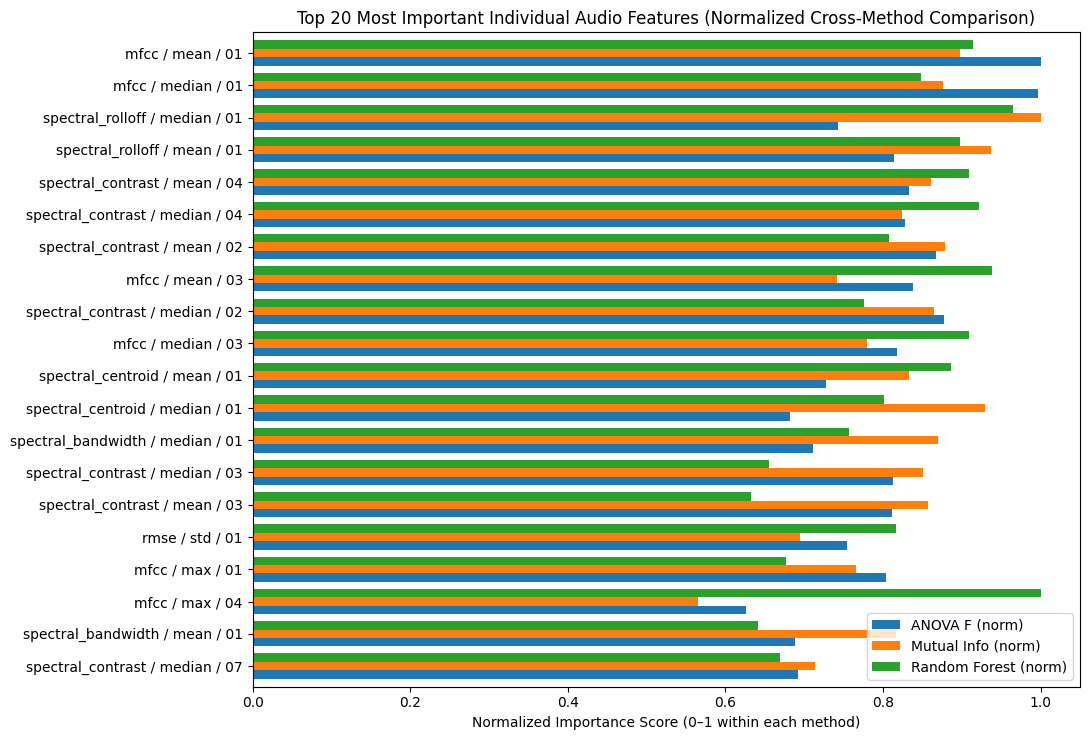

In [32]:
# VI.4 Feature Importance Across All 518 Audio Descriptors (Training Split Only)
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder

train_mask = clean_tracks[('set', 'split')] == 'training'
X_train = clean_features.loc[train_mask].copy()
y_train = LabelEncoder().fit_transform(clean_tracks.loc[train_mask, ('track', 'genre_top')])

# 1. Compute three complementary feature-importance metrics on the training split
f_scores, _ = f_classif(X_train, y_train)
mi_scores = mutual_info_classif(X_train, y_train, random_state=42)
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_imp = rf.feature_importances_

# Build full importance table
imp_df = pd.DataFrame({
    'feature_name': [' / '.join(c) for c in X_train.columns],
    'family': [c[0] for c in X_train.columns],
    'stat': [c[1] for c in X_train.columns],
    'anova_F': f_scores,
    'mutual_info': mi_scores,
    'rf_importance': rf_imp,
})
# Normalized 0-1 scores & composite rank for cross-method comparison
for m in ['anova_F', 'mutual_info', 'rf_importance']:
    imp_df[f'{m}_norm'] = imp_df[m] / imp_df[m].max()
imp_df['consensus_score'] = imp_df[['anova_F_norm', 'mutual_info_norm', 'rf_importance_norm']].mean(axis=1)

# 2. Rank agreement across the three methods
rank_corr = imp_df[['anova_F', 'mutual_info', 'rf_importance']].corr(method='spearman')
print("=== Cross-Method Feature Ranking Agreement (Spearman rho across 518 features) ===")
display(rank_corr.round(3))

# 3. Feature-family summary (Total RF share vs. Per-feature average quality)
fam_imp = imp_df.groupby('family').agg(
    n_features=('feature_name', 'count'),
    rf_total_pct=('rf_importance', lambda s: s.sum() * 100),
    rf_mean_x1e3=('rf_importance', lambda s: s.mean() * 1000),
    mean_anova_F=('anova_F', 'mean'),
    mean_MI=('mutual_info', 'mean'),
).sort_values('rf_total_pct', ascending=False)
print("\n=== Audio Feature Family Importance Summary (Training Split) ===")
display(fam_imp.round(3))

# 4. Summary-statistic breakdown (mean, std, median, etc.)
stat_imp = imp_df.groupby('stat').agg(
    n_features=('feature_name', 'count'),
    rf_total_pct=('rf_importance', lambda s: s.sum() * 100),
    rf_mean_x1e3=('rf_importance', lambda s: s.mean() * 1000),
    mean_anova_F=('anova_F', 'mean'),
    mean_MI=('mutual_info', 'mean'),
).sort_values('rf_mean_x1e3', ascending=False)
print("\n=== Summary-Statistic Importance Breakdown (Training Split) ===")
display(stat_imp.round(3))

# 5. Plot Feature Family Total Share vs. Mean Per-Feature Quality
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
fam_imp['rf_total_pct'].sort_values().plot.barh(ax=axes[0], color='steelblue')
axes[0].set_title("Total RF Importance Share (%) by Audio Feature Family")
axes[0].set_xlabel("Total Share of RF Importance (%)")
axes[0].set_ylabel("")

fam_imp['mean_MI'].sort_values().plot.barh(ax=axes[1], color='darkorange')
axes[1].set_title("Mean Mutual Information per Feature by Audio Family")
axes[1].set_xlabel("Average Mutual Information (nats)")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

# 6. Top 20 individual audio features by consensus importance
top20 = imp_df.sort_values('consensus_score', ascending=False).head(20)
print("\n=== Top 20 Individual Audio Features (Consensus Across ANOVA F, MI, and RF) ===")
display(top20[['feature_name', 'anova_F', 'mutual_info', 'rf_importance', 'consensus_score']].round(4))

top20_plot = top20.set_index('feature_name')[['anova_F_norm', 'mutual_info_norm', 'rf_importance_norm']].iloc[::-1]
top20_plot.columns = ['ANOVA F (norm)', 'Mutual Info (norm)', 'Random Forest (norm)']
top20_plot.plot.barh(figsize=(11, 7.5), width=0.78)
plt.title("Top 20 Most Important Individual Audio Features (Normalized Cross-Method Comparison)")
plt.xlabel("Normalized Importance Score (0–1 within each method)")
plt.ylabel("")
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Observations (VI.4):**
- **Strong Cross-Method Agreement**: Feature rankings are highly consistent across linear (ANOVA $F$), non-linear (Mutual Information), and multivariate tree-based (Random Forest) methods ($\rho = 0.872$ between $F$ and MI; $\rho = 0.742\text{–}0.750$ with RF), confirming that top acoustic predictors are not artifacts of a single algorithm.
- **Total Family Share vs. Per-Feature Signal Density**:
  - By **total RF share**, `mfcc` (34.3% across 140 features) and `spectral_contrast` (13.9% across 49 features) dominate, jointly supplying **48.2%** of overall tree importance. By contrast, `chroma_stft` (11.7%), `chroma_cens` (11.0%), and `chroma_cqt` (10.2%) owe their total share largely to high column count (84 features each) rather than individual strength.
  - By **per-feature importance**, the compact 7-feature spectral and energy families are the most information-dense: `spectral_rolloff` (mean MI = 0.131, mean $F = 118.9$), `spectral_centroid` (mean MI = 0.121, mean $F = 115.4$), `spectral_bandwidth` (mean MI = 0.103), `rmse` (mean $F = 103.4$), and `spectral_contrast` (mean $F = 101.0$) lead, whereas `chroma_cens` and `chroma_cqt` have the weakest per-feature signal (mean MI = 0.029–0.031).
- **Most Informative Summary Statistics**: Across the 7 temporal aggregations (74 features each), **`std` (18.1%), `mean` (17.3%), and `median` (17.2%)** account for **52.5%** of total RF importance. Interestingly, `std` leads Random Forest importance (highlighting how dynamic variation over the 30-second clip adds strong non-linear value), whereas `median` leads univariate ANOVA $F$ (97.2) and MI (0.078) due to robustness against skew/outliers; `min`, `max`, and `kurtosis` contribute the least on average.
- **Top 20 Individual Features**: All 20 consensus leaders belong to `mfcc`, `spectral_contrast` (especially mid-frequency bands `02`–`04`), `spectral_rolloff`, `spectral_centroid`, `spectral_bandwidth`, and `rmse / std / 01`—with **zero** chroma or tonnetz descriptors in the top 20. Frequent `mean`/`median` twin pairs (e.g., `mfcc / mean / 01` & `mfcc / median / 01`) also reinforce VI.2's finding that correlated summary statistics split importance and can be pruned cleanly.

## **VI.5 Multivariate Structure & Genre Separability via PCA (`clean_features`)**

Applies `StandardScaler` and Principal Component Analysis (PCA) on all 518 audio descriptors (fit on the `training` split) to measure intrinsic dimensionality, identify which acoustic dimensions drive the largest variance across tracks, and visualize how cleanly the 8 genres separate in low-dimensional linear feature space.

Components needed for 50% variance:  16 / 518 (3.1% of original dimensions)
Components needed for 80% variance:  81 / 518 (15.6% of original dimensions)
Components needed for 90% variance: 143 / 518 (27.6% of original dimensions)
Components needed for 95% variance: 204 / 518 (39.4% of original dimensions)
Variance explained by PC1: 11.56%, PC2: 7.36%, PC1+PC2: 18.92%

=== Top 8 Features Driving PC1 (by |loading|) ===


,PC1_loading
spectral_contrast / mean / 02,0.108
spectral_contrast / median / 02,0.107
spectral_contrast / mean / 03,0.104
spectral_contrast / median / 03,0.103
spectral_contrast / mean / 04,0.097
spectral_contrast / median / 04,0.094
tonnetz / std / 04,0.086
tonnetz / std / 03,0.086



=== Top 8 Features Driving PC2 (by |loading|) ===


,PC2_loading
mfcc / max / 08,0.105
mfcc / max / 10,0.104
mfcc / max / 06,0.101
mfcc / max / 12,0.100
mfcc / max / 09,0.100
mfcc / std / 09,0.098
spectral_rolloff / std / 01,0.098
mfcc / std / 08,0.097


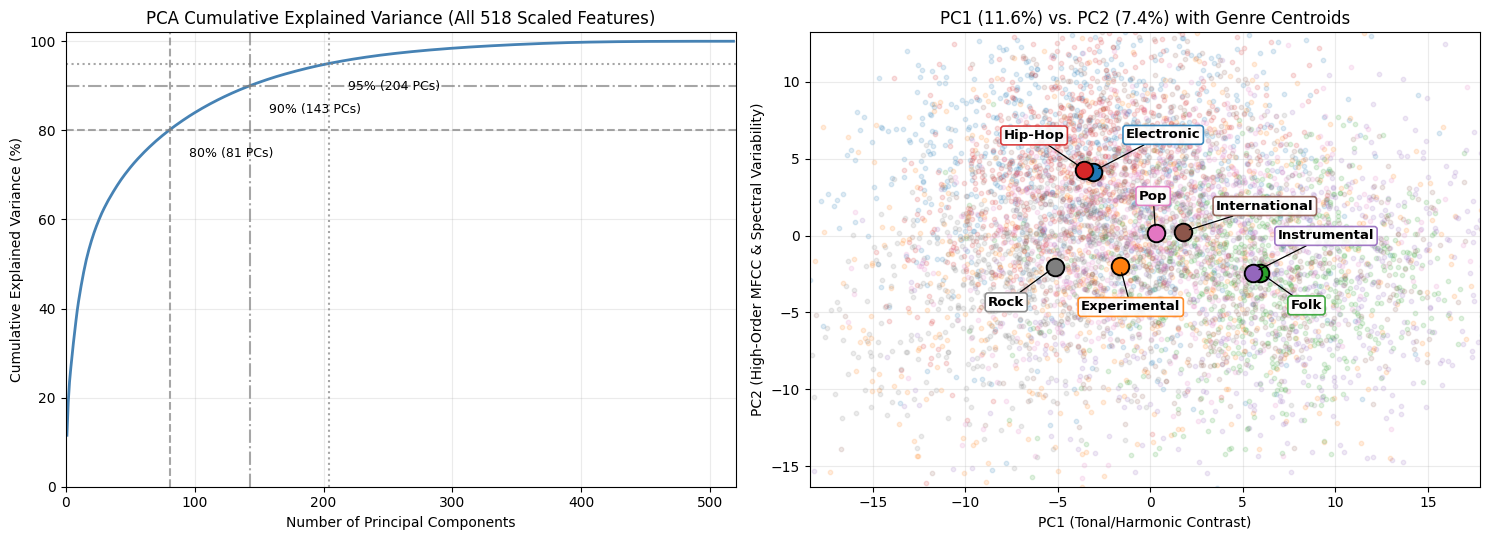

In [34]:
# VI.5 Multivariate PCA: Dimensionality, Feature Loadings & Genre Separability (Training Split)
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

train_mask = clean_tracks[('set', 'split')] == 'training'
X_train_raw = clean_features.loc[train_mask]
y_train_labels = clean_tracks.loc[train_mask, ('track', 'genre_top')]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)

pca = PCA(random_state=42)
X_pca = pca.fit_transform(X_train_scaled)
cum_var = np.cumsum(pca.explained_variance_ratio_)

# Components needed for key variance thresholds
for thresh in [0.50, 0.80, 0.90, 0.95]:
    n_comp = int(np.searchsorted(cum_var, thresh) + 1)
    print(f"Components needed for {int(thresh*100)}% variance: {n_comp:3d} / {X_train_raw.shape[1]} ({n_comp / X_train_raw.shape[1] * 100:.1f}% of original dimensions)")
print(f"Variance explained by PC1: {pca.explained_variance_ratio_[0]*100:.2f}%, PC2: {pca.explained_variance_ratio_[1]*100:.2f}%, PC1+PC2: {cum_var[1]*100:.2f}%\n")

# Top feature loadings on PC1 and PC2 for musical interpretability
feat_names = [' / '.join(c) for c in X_train_raw.columns]
loadings = pd.DataFrame(
    pca.components_[:2].T,
    index=feat_names,
    columns=['PC1_loading', 'PC2_loading'],
)
print("=== Top 8 Features Driving PC1 (by |loading|) ===")
display(loadings.reindex(loadings['PC1_loading'].abs().sort_values(ascending=False).head(8).index)[['PC1_loading']].round(3))
print("\n=== Top 8 Features Driving PC2 (by |loading|) ===")
display(loadings.reindex(loadings['PC2_loading'].abs().sort_values(ascending=False).head(8).index)[['PC2_loading']].round(3))

# Plot 1: Cumulative Explained Variance & Plot 2: PC1 vs PC2 with Genre Centroids
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Cumulative variance plot
axes[0].plot(range(1, len(cum_var) + 1), cum_var * 100, color='steelblue', lw=2)
for thresh, ls in [(80, '--'), (90, '-.'), (95, ':')]:
    n_c = int(np.searchsorted(cum_var, thresh / 100.0) + 1)
    axes[0].axhline(thresh, color='gray', linestyle=ls, alpha=0.7)
    axes[0].axvline(n_c, color='gray', linestyle=ls, alpha=0.7)
    axes[0].annotate(f"{thresh}% ({n_c} PCs)", xy=(n_c, thresh), xytext=(n_c + 15, thresh - 6), fontsize=9)
axes[0].set_title("PCA Cumulative Explained Variance (All 518 Scaled Features)")
axes[0].set_xlabel("Number of Principal Components")
axes[0].set_ylabel("Cumulative Explained Variance (%)")
axes[0].set_xlim(0, 520)
axes[0].set_ylim(0, 102)
axes[0].grid(alpha=0.25)

# 2D PCA scatter + non-overlapping genre centroid annotations
pca_df = pd.DataFrame({'PC1': X_pca[:, 0], 'PC2': X_pca[:, 1], 'genre': y_train_labels.values})
palette = dict(zip(sorted(pca_df['genre'].unique()), sns.color_palette('tab10', 8)))

x_lo, x_hi = np.percentile(pca_df['PC1'], [1, 99])
y_lo, y_hi = np.percentile(pca_df['PC2'], [1, 99])

for g, color in palette.items():
    sub = pca_df[pca_df['genre'] == g]
    axes[1].scatter(sub['PC1'], sub['PC2'], s=10, alpha=0.14, color=color)

offsets = {
    'Hip-Hop': (-58, 22),
    'Electronic': (24, 24),
    'Pop': (-12, 24),
    'International': (24, 16),
    'Rock': (-48, -28),
    'Experimental': (-28, -32),
    'Instrumental': (18, 24),
    'Folk': (22, -26),
}
centroids = pca_df.groupby('genre')[['PC1', 'PC2']].mean()
for g, row in centroids.iterrows():
    axes[1].scatter(row['PC1'], row['PC2'], s=160, color=palette[g], edgecolor='black', linewidth=1.4, zorder=5)
    dx, dy = offsets.get(g, (15, 15))
    axes[1].annotate(
        g,
        xy=(row['PC1'], row['PC2']),
        xytext=(dx, dy),
        textcoords='offset points',
        fontsize=9.5,
        fontweight='bold',
        color='black',
        bbox=dict(boxstyle='round,pad=0.22', facecolor='white', alpha=0.88, edgecolor=palette[g], lw=1.2),
        arrowprops=dict(arrowstyle='-', color='black', lw=0.9, shrinkA=0, shrinkB=5),
        zorder=6,
    )

axes[1].set_xlim(x_lo, x_hi)
axes[1].set_ylim(y_lo, y_hi)
axes[1].set_title(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%) vs. PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%) with Genre Centroids")
axes[1].set_xlabel("PC1 (Tonal/Harmonic Contrast)")
axes[1].set_ylabel("PC2 (High-Order MFCC & Spectral Variability)")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

**Observations (VI.5):**
- **High Compressibility of the 518-Feature Space**: Only **16 PCs (3.1%)** capture 50% of total variance, **81 PCs (15.6%)** capture 80%, **143 PCs (27.6%)** capture 90%, and **204 PCs (39.4%)** capture 95%—reinforcing VI.2's multicollinearity finding and demonstrating that PCA can cut dimensionality by 60–85% with minimal information loss.
- **Musically Interpretable Principal Axes**:
  - **PC1 (11.6% variance)** loads most heavily on mid-band `spectral_contrast` (`mean`/`median` bands `02`–`04`, loadings `+0.094` to `+0.108`) and `tonnetz / std`, separating clean, acoustic genres (**Folk**, **Instrumental**) on the right from loud, dense, or heavily produced genres (**Rock**, **Hip-Hop**, **Electronic**) on the left.
  - **PC2 (7.4% variance)** loads on higher-order MFCC extremes/variability (`mfcc / max / 06–12`, `mfcc / std / 08–09`) and `spectral_rolloff / std / 01` (`+0.097` to `+0.105`), lifting **Hip-Hop** and **Electronic** sharply above **Rock**, **Experimental**, **Folk**, and **Instrumental**.
- **Macro-Clusters vs. Individual Track Overlap**: While genre centroids organize into clear acoustic neighborhoods (*Folk/Instrumental*, *Hip-Hop/Electronic*, *Rock*, with *Pop/International/Experimental* bridging the center), PC1 + PC2 explain only **18.9%** of variance and individual track clouds overlap substantially—signaling that **high-dimensional, non-linear classifiers** are necessary to separate neighboring genres (e.g., Folk vs. Instrumental, Hip-Hop vs. Electronic, and Pop vs. International).

---

### **Summary & Key Takeaways (Section VI — Audio Feature Importance & Data Mining Roadmap)**
- **Which Audio Features Matter Most for Genre Classification**: Across Kruskal-Wallis tests, ANOVA $F$, Mutual Information, and Random Forest Gini importance (training split only), **timbre (`mfcc`)** and **spectral shape/contrast (`spectral_contrast`, `spectral_rolloff`, `spectral_centroid`, `spectral_bandwidth`)** plus **loudness dynamics (`rmse`)** are the primary drivers of genre discrimination. `mfcc` (34.3%) and `spectral_contrast` (13.9%) deliver nearly half of total Random Forest importance, while compact 7-feature spectral families (`spectral_rolloff`, `spectral_centroid`, `spectral_bandwidth`, `rmse`) exhibit the highest *per-feature* signal density. Conversely, `chroma_*` and `tonnetz` carry weak standalone per-feature power, though they remain nearly orthogonal to spectral/loudness features and contribute complementary harmonic context.
- **Temporal Dynamics Matter as Much as Average Sound**: Among the 7 summary statistics, **`std` (18.1%), `mean` (17.3%), and `median` (17.2%)** provide over half of total Random Forest importance—confirming that *how loudness and timbre fluctuate* across a 30-second clip is just as informative as its average level, while `min`, `max`, and `kurtosis` are prime candidates for pruning.
- **Exclude Technical Confounds**: Because `track / bit_rate` ($\eta^2_H = 0.052$) and `track / duration` ($\eta^2_H = 0.035$) differ systematically by genre, modeling pipelines must use only the 518 `clean_features` audio descriptors and respect the verified `set / split` partition (80/10/10, perfectly stratified across genres).
- **Recommended Data-Mining Strategy**: Because 39.4% of features are strongly collinear ($|r| \ge 0.85$) and 2D linear projections overlap heavily—especially for **Pop**, **International**, and **Experimental**—downstream classification should pair **feature scaling + dimensionality reduction or feature selection** (e.g., pruning redundant `mean`/`median` twins or applying PCA retaining 80–95% variance) with **non-linear and regularized models** (Random Forest, Gradient Boosting/XGBoost, RBF-SVM, MLP) and evaluate feature-family ablations (e.g., MFCC-only vs. Spectral+MFCC vs. All Features) using the official `validation` and `test` splits.

# **VII. Type-specific analysis**

Beyond standard tabular distributions, the FMA-Small dataset contains specialized data structures—**hierarchical groups** (`artist / id`, `album / id`), **temporal metadata** (`track / date_created`, `album / date_released`), **domain-specific multi-band audio descriptors** (ordered MFCC coefficients, frequency sub-bands, and 12 pitch classes), and **structured list/text metadata** (`track / genres_all`, `track / tags`, `track / title`). *(Image data does not apply to this tabular/audio feature dataset.)* Examining these specialized structures directly supports **analyzing the importance of audio features in music genre classification** by auditing artist/album leakage, checking temporal stability across eras, pinpointing *which acoustic sub-bands* carry the most genre signal, and explaining genre overlap via sub-genre taxonomy.

- **VII.1 Group-Structure Analysis: Artist & Album Clustering (`artist / id`, `album / id`)**
- **VII.2 Temporal Analysis: Upload Timeline & Acoustic Feature Stability (`track / date_created`, `album / date_released`)**
- **VII.3 Audio-Domain Structure: Band-by-Band Importance Across MFCCs, Spectral Contrast & Chroma (`clean_features`)**
- **VII.4 Taxonomy & Text Metadata Analysis: Multi-Genre Complexity & Tag Sparsity (`track / genres_all`, `track / tags`, `track / title`)**
- **Summary & Key Takeaways (Section VII)**

## **VII.1 Group-Structure Analysis: Artist & Album Clustering (`artist / id`, `album / id`)**

Tracks are nested inside **artists** and **albums**. This subsection audits artist/album concentration across genres, verifies whether FMA's official `set / split` prevents cross-split artist/album leakage, and quantifies the **"artist effect"** in standardized audio-feature space (comparing acoustic distances within the same artist vs. same genre vs. different genres).

=== Group Cardinality & Concentration (Cleaned Dataset: 7,983 tracks) ===
Unique artists : 2,309 | Median tracks/artist: 1 | Max: 206 | % tracks from multi-track artists: 85.0%
Unique albums  : 2,464 | Median tracks/album : 2 | Max: 36 | % tracks from multi-track albums : 87.6%

=== Artist & Album Diversity by Genre ===


,n_tracks,unique_artists,unique_albums,max_tracks_one_artist,tracks_per_artist
genre,,,,,
Experimental,999,483,435,29,2.07
Rock,999,449,500,21,2.22
Electronic,993,360,343,29,2.76
Pop,998,297,267,41,3.36
International,1000,256,203,29,3.91
Folk,1000,249,311,91,4.02
Hip-Hop,1000,194,279,68,5.15
Instrumental,994,120,212,206,8.28



=== Cross-Split Overlap Audit (set / split) ===
Artist ID overlap -> train & val: 0, train & test: 0, val & test: 0
Album ID  overlap -> train & val: 58, train & test: 49, val & test: 21

=== Pairwise Acoustic Distance Summary (Training Split, 4,000 Pairs Each) ===


,median,mean,std
Pair Type,,,
Different Genre,28.96,30.71,10.37
Same Artist,22.73,24.90,11.83
Same Genre (Diff. Artist),27.20,29.20,10.26


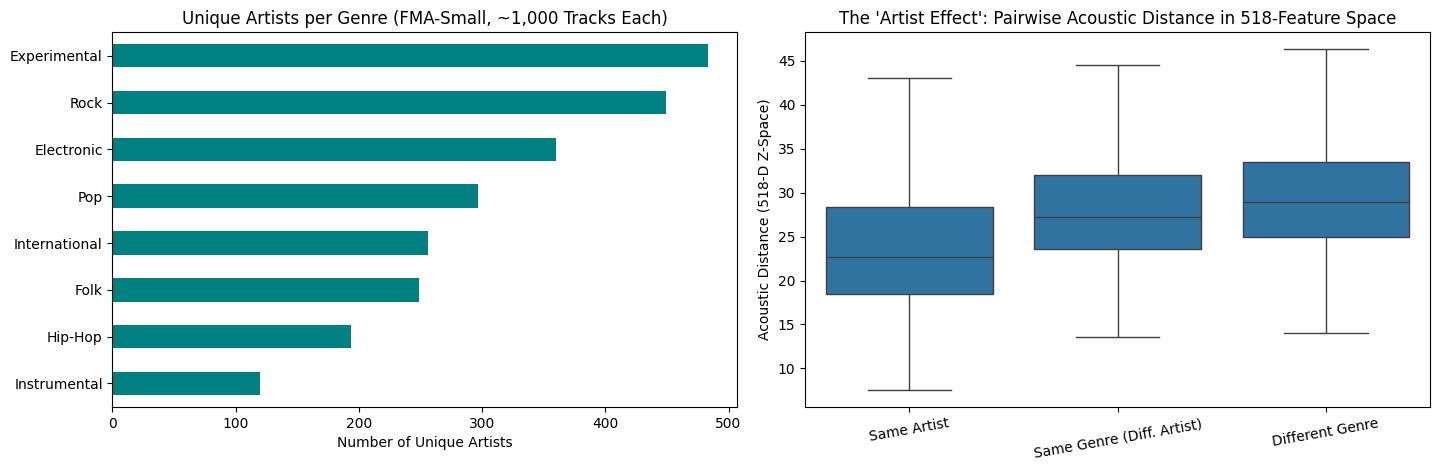

In [35]:
# VII.1 Group-Structure Analysis: Artist & Album Concentration, Split Leakage Audit & Artist Effect
from sklearn.preprocessing import StandardScaler

artist_id = clean_tracks[('artist', 'id')]
album_id = clean_tracks[('album', 'id')]
genre = clean_tracks[('track', 'genre_top')]
split = clean_tracks[('set', 'split')]

# 1. Cardinality & Concentration Summary
artist_counts = artist_id.value_counts()
album_counts = album_id.value_counts()
print("=== Group Cardinality & Concentration (Cleaned Dataset: 7,983 tracks) ===")
print(f"Unique artists : {artist_id.nunique():,} | Median tracks/artist: {artist_counts.median():.0f} | Max: {artist_counts.max()} | % tracks from multi-track artists: {(artist_counts[artist_id].values > 1).mean()*100:.1f}%")
print(f"Unique albums  : {album_id.nunique():,} | Median tracks/album : {album_counts.median():.0f} | Max: {album_counts.max()} | % tracks from multi-track albums : {(album_counts[album_id].values > 1).mean()*100:.1f}%")

# Genre-level artist diversity
group_df = pd.DataFrame({'genre': genre, 'artist_id': artist_id, 'album_id': album_id, 'split': split})
genre_artist_stats = group_df.groupby('genre').agg(
    n_tracks=('artist_id', 'size'),
    unique_artists=('artist_id', 'nunique'),
    unique_albums=('album_id', 'nunique'),
    max_tracks_one_artist=('artist_id', lambda s: s.value_counts().max()),
)
genre_artist_stats['tracks_per_artist'] = (genre_artist_stats['n_tracks'] / genre_artist_stats['unique_artists']).round(2)
print("\n=== Artist & Album Diversity by Genre ===")
display(genre_artist_stats.sort_values('unique_artists', ascending=False))

# 2. Official Split Cross-Partition Leakage Audit
print("\n=== Cross-Split Overlap Audit (set / split) ===")
for label, col_name in [('Artist ID', 'artist_id'), ('Album ID', 'album_id')]:
    sets = {sp: set(group_df.loc[group_df['split'] == sp, col_name]) for sp in ['training', 'validation', 'test']}
    tr_va = len(sets['training'] & sets['validation'])
    tr_te = len(sets['training'] & sets['test'])
    va_te = len(sets['validation'] & sets['test'])
    print(f"{label:9s} overlap -> train & val: {tr_va}, train & test: {tr_te}, val & test: {va_te}")

# 3. Quantifying the 'Artist Effect' in Standardized 518-Feature Acoustic Space (Training Split)
train_mask = split == 'training'
X_tr = StandardScaler().fit_transform(clean_features.loc[train_mask].values)
y_tr = genre.loc[train_mask].values
a_tr = artist_id.loc[train_mask].values

rng = np.random.default_rng(42)
n_pairs = 4000

# Sample Same-Artist pairs
artist_to_idx = {}
for idx, aid in enumerate(a_tr):
    artist_to_idx.setdefault(aid, []).append(idx)
multi_artists = [idxs for idxs in artist_to_idx.values() if len(idxs) >= 2]

same_artist_dists = []
for _ in range(n_pairs):
    idxs = multi_artists[rng.integers(len(multi_artists))]
    i, j = rng.choice(idxs, size=2, replace=False)
    same_artist_dists.append(np.linalg.norm(X_tr[i] - X_tr[j]))

# Sample Same-Genre / Different-Artist pairs
genre_to_idx = {g: np.where(y_tr == g)[0] for g in np.unique(y_tr)}
genre_list = list(genre_to_idx.keys())
same_genre_diff_artist_dists = []
while len(same_genre_diff_artist_dists) < n_pairs:
    g = genre_list[rng.integers(len(genre_list))]
    idxs = genre_to_idx[g]
    i, j = rng.choice(idxs, size=2, replace=False)
    if a_tr[i] != a_tr[j]:
        same_genre_diff_artist_dists.append(np.linalg.norm(X_tr[i] - X_tr[j]))

# Sample Different-Genre pairs
diff_genre_dists = []
while len(diff_genre_dists) < n_pairs:
    i, j = rng.integers(0, len(X_tr), size=2)
    if y_tr[i] != y_tr[j]:
        diff_genre_dists.append(np.linalg.norm(X_tr[i] - X_tr[j]))

dist_df = pd.DataFrame({
    'Acoustic Distance (518-D Z-Space)': same_artist_dists + same_genre_diff_artist_dists + diff_genre_dists,
    'Pair Type': (['Same Artist'] * n_pairs + ['Same Genre (Diff. Artist)'] * n_pairs + ['Different Genre'] * n_pairs),
})
print("\n=== Pairwise Acoustic Distance Summary (Training Split, 4,000 Pairs Each) ===")
display(dist_df.groupby('Pair Type')['Acoustic Distance (518-D Z-Space)'].agg(['median', 'mean', 'std']).round(2))

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.8))
genre_artist_stats['unique_artists'].sort_values().plot.barh(ax=axes[0], color='teal')
axes[0].set_title("Unique Artists per Genre (FMA-Small, ~1,000 Tracks Each)")
axes[0].set_xlabel("Number of Unique Artists")
axes[0].set_ylabel("")

sns.boxplot(
    data=dist_df,
    x='Pair Type',
    y='Acoustic Distance (518-D Z-Space)',
    order=['Same Artist', 'Same Genre (Diff. Artist)', 'Different Genre'],
    showfliers=False,
    ax=axes[1],
)
axes[1].set_title("The 'Artist Effect': Pairwise Acoustic Distance in 518-Feature Space")
axes[1].set_xlabel("")
axes[1].tick_params(axis='x', rotation=10)
plt.tight_layout()
plt.show()

**Observations (VII.1):**
- **Strong Artist Concentration (Especially in Instrumental & Hip-Hop)**: Across the 7,983 cleaned tracks, **85.0%** come from multi-track artists (2,309 unique artists) and **87.6%** from multi-track albums (2,464 unique albums). Diversity differs sharply by genre: **Experimental** (483 artists; 2.07 tracks/artist) and **Rock** (449 artists; 2.22 tracks/artist) span many distinct creators, whereas **Instrumental** has only **120 unique artists** (8.28 tracks/artist, with a single artist accounting for **206 tracks**—over 20% of the class), followed by **Hip-Hop** (194 artists; max 68) and **Folk** (249 artists; max 91). Models trained on Instrumental or Folk risk learning prolific artists' styles unless regularized.
- **Official Split Integrity (`artist / id` vs. `album / id`)**: FMA's official `set / split` maintains **zero artist overlap** across `training`, `validation`, and `test` (0 / 0 / 0), guaranteeing artist-disjoint evaluation. A small number of multi-artist compilation `album / id` values do span splits (58 train–val, 49 train–test, 21 val–test), worth noting as minor shared-compilation context.
- **Quantified "Artist Effect" in Audio-Feature Space**: In standardized 518-feature space, **Same-Artist** pairs are markedly closer (median distance **22.73**) than **Same-Genre / Different-Artist** pairs (**27.20**) and **Different-Genre** pairs (**28.96**). Because the within-artist similarity drop (4.47 units) is over **2.5× larger** than the between-genre drop (1.76 units), naive random cross-validation would leak artist identity; downstream model tuning on the training split should therefore use **`GroupKFold` grouped by `artist / id`**.

## **VII.2 Temporal Analysis: Upload Timeline & Acoustic Feature Stability (`track / date_created`, `album / date_released`)**

Examines how FMA-Small's genre mix, official split assignment, and top-importance audio descriptors (`mfcc / mean / 01`, `spectral_rolloff / mean / 01`, `spectral_contrast / mean / 04`, `rmse / std / 01`) behave over upload years (`track / date_created`, 0% missing) and release years (`album / date_released`, non-null subset)—testing for temporal shift or production-era drift.

=== Temporal Coverage Summary ===
track / date_created  : 2008-11-25 to 2017-03-24 (missing: 0)
album / date_released : 1930-01-01 to 2021-03-01 (missing: 2654 / 33.2%)
Release-year span     : 109 tracks pre-2000 (2.0% of dated), 88.5% released 2008 or later

=== Official Split Share by Track Upload Year ===


split,training,validation,test,n_tracks
upload_year,,,,
2008,0.879,0.052,0.069,248
2009,0.708,0.091,0.201,692
2010,0.745,0.117,0.138,686
2011,0.841,0.088,0.071,886
2012,0.796,0.108,0.096,883
2013,0.817,0.115,0.068,924
2014,0.787,0.099,0.114,877
2015,0.842,0.092,0.066,1501
2016,0.785,0.117,0.098,1193



=== Temporal Drift of Top Audio Features (Spearman Correlation) ===


,Audio Feature,rho_upload_year,p_upload,rho_release_2005_2017,p_release
0,mfcc / mean / 01,0.033,3.28e-03,0.040,4.54e-03
1,spectral_rolloff / mean / 01,-0.053,2.20e-06,-0.039,5.61e-03
2,spectral_contrast / mean / 04,0.030,7.73e-03,-0.001,9.53e-01
3,rmse / std / 01,0.109,1.71e-22,0.151,3.02e-27


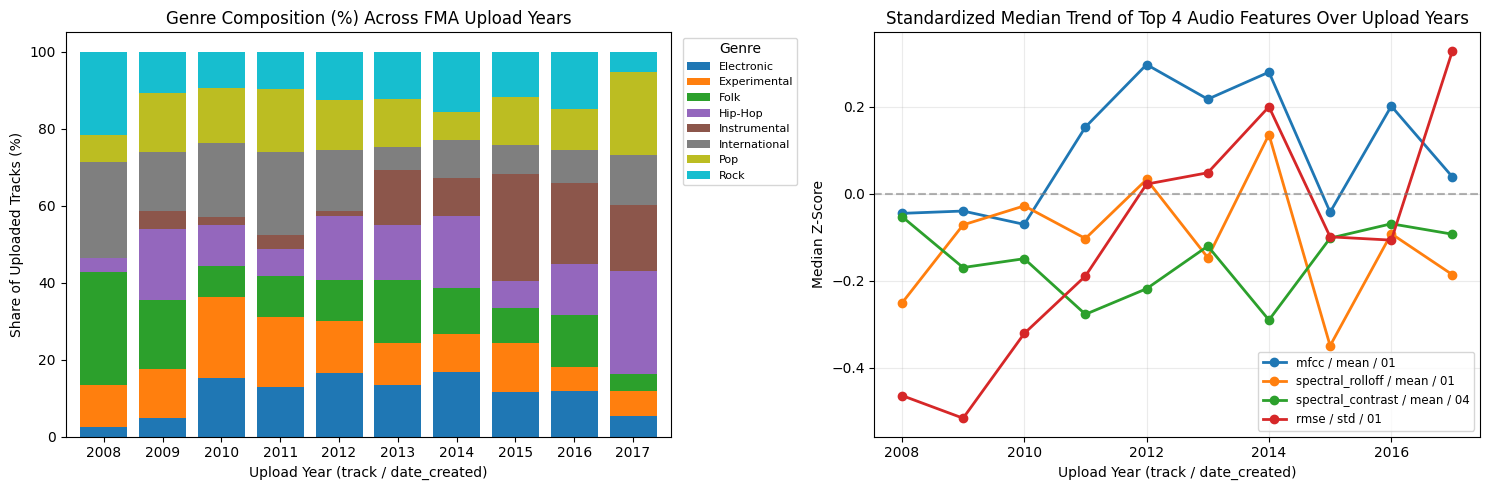

In [36]:
# VII.2 Temporal Analysis: Upload Timeline, Split Stability & Acoustic Drift
upload_dt = pd.to_datetime(clean_tracks[('track', 'date_created')], errors='coerce')
release_dt = pd.to_datetime(clean_tracks[('album', 'date_released')], errors='coerce')

temp_df = pd.DataFrame({
    'upload_year': upload_dt.dt.year,
    'release_year': release_dt.dt.year,
    'genre': clean_tracks[('track', 'genre_top')],
    'split': clean_tracks[('set', 'split')],
})

print("=== Temporal Coverage Summary ===")
print(f"track / date_created  : {upload_dt.min().date()} to {upload_dt.max().date()} (missing: {upload_dt.isna().sum()})")
print(f"album / date_released : {release_dt.min().date()} to {release_dt.max().date()} (missing: {release_dt.isna().sum()} / {release_dt.isna().mean()*100:.1f}%)")
valid_rel = temp_df['release_year'].dropna()
print(f"Release-year span     : {(valid_rel < 2000).sum()} tracks pre-2000 ({(valid_rel < 2000).mean()*100:.1f}% of dated), {(valid_rel >= 2008).mean()*100:.1f}% released 2008 or later\n")

# 1. Split proportions by upload year
year_counts = temp_df['upload_year'].value_counts().sort_index()
split_by_year = pd.crosstab(temp_df['upload_year'], temp_df['split'], normalize='index')[['training', 'validation', 'test']].round(3)
split_by_year['n_tracks'] = year_counts
print("=== Official Split Share by Track Upload Year ===")
display(split_by_year)

# 2. Temporal drift test on top-importance audio features (Spearman rho vs upload_year & release_year)
top_audio_cols = [
    ('mfcc', 'mean', '01'),
    ('spectral_rolloff', 'mean', '01'),
    ('spectral_contrast', 'mean', '04'),
    ('rmse', 'std', '01'),
]
drift_rows = []
for col in top_audio_cols:
    name = ' / '.join(col)
    vals = clean_features[col]
    r_up, p_up = stats.spearmanr(temp_df['upload_year'], vals, nan_policy='omit')
    rel_mask = temp_df['release_year'].between(2005, 2017)
    r_rel, p_rel = stats.spearmanr(temp_df.loc[rel_mask, 'release_year'], vals.loc[rel_mask])
    drift_rows.append({
        'Audio Feature': name,
        'rho_upload_year': round(r_up, 3),
        'p_upload': f"{p_up:.2e}",
        'rho_release_2005_2017': round(r_rel, 3),
        'p_release': f"{p_rel:.2e}",
    })
print("\n=== Temporal Drift of Top Audio Features (Spearman Correlation) ===")
display(pd.DataFrame(drift_rows))

# 3. Visualizations: Genre mix by upload year & standardized feature medians over time
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Filter upload years with >= 50 tracks for clean proportions
valid_years = year_counts[year_counts >= 50].index
genre_year_pct = pd.crosstab(
    temp_df.loc[temp_df['upload_year'].isin(valid_years), 'upload_year'],
    temp_df.loc[temp_df['upload_year'].isin(valid_years), 'genre'],
    normalize='index',
) * 100
genre_year_pct.plot(kind='bar', stacked=True, ax=axes[0], colormap='tab10', width=0.8)
axes[0].set_title("Genre Composition (%) Across FMA Upload Years")
axes[0].set_xlabel("Upload Year (track / date_created)")
axes[0].set_ylabel("Share of Uploaded Tracks (%)")
axes[0].legend(title="Genre", bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8)
axes[0].tick_params(axis='x', rotation=0)

# Standardized median trends for top 4 audio features across upload years
trend_df = pd.DataFrame({'upload_year': temp_df['upload_year']})
for col in top_audio_cols:
    s = clean_features[col]
    trend_df[' / '.join(col)] = (s - s.mean()) / s.std()
yearly_medians = trend_df[trend_df['upload_year'].isin(valid_years)].groupby('upload_year').median()
yearly_medians.plot(marker='o', linewidth=2, ax=axes[1])
axes[1].axhline(0, color='gray', linestyle='--', alpha=0.6)
axes[1].set_title("Standardized Median Trend of Top 4 Audio Features Over Upload Years")
axes[1].set_xlabel("Upload Year (track / date_created)")
axes[1].set_ylabel("Median Z-Score")
axes[1].legend(fontsize=8.5, loc='best')
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

**Observations (VII.2):**
- **Temporal Coverage & Metadata Quirks**: `track / date_created` cleanly spans **2008-11-25 to 2017-03-24** (0 missing, peaking in 2015–2016). `album / date_released` is missing for 33.2% of tracks (2,654 rows), includes 109 archival pre-2000 recordings (2.0% of dated tracks, back to 1930), and contains at least one post-collection metadata anomaly (`2021-03-01`), though 88.5% of dated tracks were released from 2008 onward.
- **Strong Catalog Upload Waves by Genre**: Genre proportions shift substantially across upload years—most notably **Instrumental**, which is nearly absent in 2008–2012 (<5%) before surging to ~28% of all 2015 uploads and ~21% of 2016 uploads (whereas **Folk** and **International** are more heavily represented in 2008–2011). Because `set / split` draws `training`, `validation`, and `test` tracks from *every* year (70.8%–87.9% training per year) rather than splitting chronologically, **upload/release dates must be excluded from model inputs** to prevent catalog-wave leakage.
- **High Temporal Stability of Core Audio Features**: Three of the top four predictors show virtually zero monotonic drift across 2008–2017 (`mfcc / mean / 01`: $\rho = 0.033$; `spectral_rolloff / mean / 01`: $\rho = -0.053$; `spectral_contrast / mean / 04`: $\rho = 0.030$). The visible dip in `spectral_rolloff` and `mfcc / mean / 01` in 2015 mirrors that year's Instrumental upload wave rather than audio degradation. Only `rmse / std / 01` drifts modestly upward over upload years ($\rho = 0.109$) and 2005–2017 release years ($\rho = 0.151$), confirming that core timbral and spectral features generalize stably across recording eras.

## **VII.3 Audio-Domain Structure: Band-by-Band Importance Across MFCCs, Spectral Contrast & Chroma (`clean_features`)**

Unlike generic tabular columns, `clean_features` encodes ordered acoustic indices—20 cepstral coefficients (`mfcc`), 7 octave frequency sub-bands (`spectral_contrast`), and 12 chromatic pitch classes (`chroma_stft`). Evaluating genre discrimination ($\eta^2_H$ on the `training` split) band by band for both `mean` and `std` reveals *where* inside each audio family the predictive signal actually lives.

=== Band-Level Effect Size (eta2_H) Summary on Training Split ===
MFCC (mean)        : bands 1-5 avg = 0.1765 | bands 6-10 avg = 0.0905 | bands 11-20 avg = 0.1281
MFCC (std)         : bands 1-5 avg = 0.0790 | bands 6-10 avg = 0.1252 | bands 11-20 avg = 0.1182
Spectral Contrast  : mean peak = band 4 (0.2540), min = band 6 (0.0392) | std peak = band 4 (0.1417)
Chroma STFT (mean) : min = 0.0772, max = 0.1462, avg = 0.1106 (std across 12 pitch classes = 0.0205)
Chroma STFT (std)  : min = 0.0206, max = 0.0495, avg = 0.0344 (std across 12 pitch classes = 0.0088)


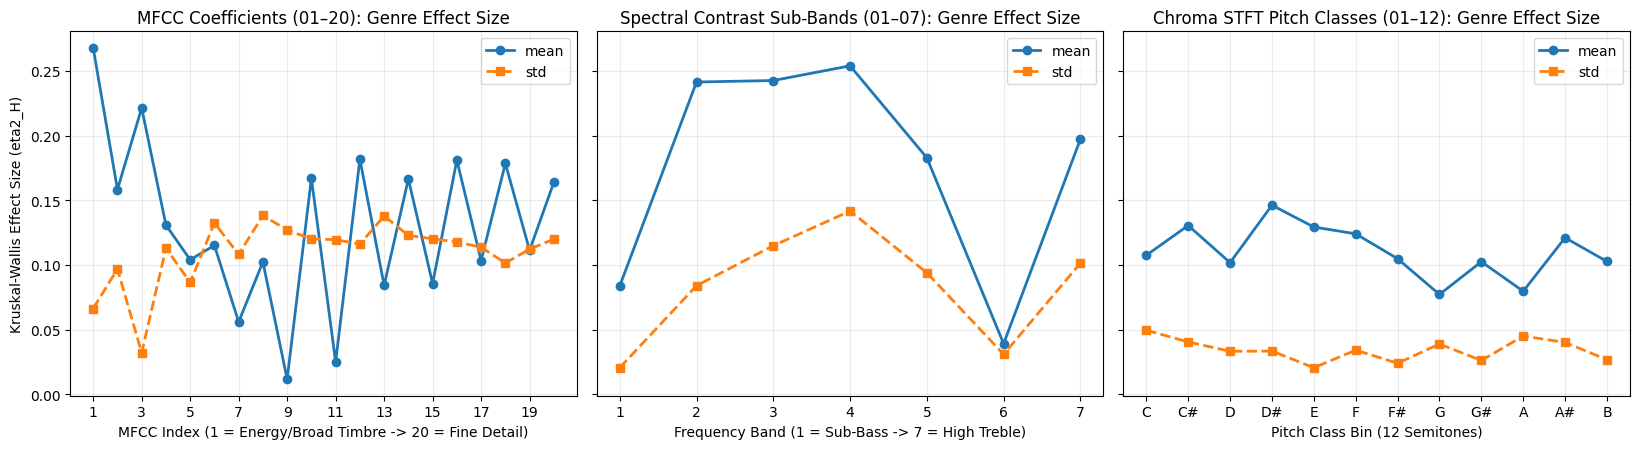

In [37]:
# VII.3 Audio-Domain Band-by-Band Importance: MFCC (1-20), Spectral Contrast (1-7), Chroma STFT (1-12)
train_mask = clean_tracks[('set', 'split')] == 'training'
X_tr_df = clean_features.loc[train_mask]
y_tr_ser = clean_tracks.loc[train_mask, ('track', 'genre_top')]
genres_sorted = sorted(y_tr_ser.unique())
n_tr = len(X_tr_df)
k_tr = len(genres_sorted)

def band_eta2(family, stat_name):
    cols = sorted([c for c in X_tr_df.columns if c[0] == family and c[1] == stat_name], key=lambda x: int(x[2]))
    bands, etas = [], []
    for c in cols:
        groups = [X_tr_df.loc[y_tr_ser == g, c].values for g in genres_sorted]
        H, _ = stats.kruskal(*groups)
        etas.append(max(0.0, (H - k_tr + 1) / (n_tr - k_tr)))
        bands.append(int(c[2]))
    return pd.Series(etas, index=bands)

# Compute band-wise Kruskal-Wallis effect sizes (eta2_H) for mean and std
mfcc_mean = band_eta2('mfcc', 'mean')
mfcc_std = band_eta2('mfcc', 'std')
sc_mean = band_eta2('spectral_contrast', 'mean')
sc_std = band_eta2('spectral_contrast', 'std')
ch_mean = band_eta2('chroma_stft', 'mean')
ch_std = band_eta2('chroma_stft', 'std')

print("=== Band-Level Effect Size (eta2_H) Summary on Training Split ===")
print(f"MFCC (mean)        : bands 1-5 avg = {mfcc_mean.loc[1:5].mean():.4f} | bands 6-10 avg = {mfcc_mean.loc[6:10].mean():.4f} | bands 11-20 avg = {mfcc_mean.loc[11:20].mean():.4f}")
print(f"MFCC (std)         : bands 1-5 avg = {mfcc_std.loc[1:5].mean():.4f} | bands 6-10 avg = {mfcc_std.loc[6:10].mean():.4f} | bands 11-20 avg = {mfcc_std.loc[11:20].mean():.4f}")
print(f"Spectral Contrast  : mean peak = band {sc_mean.idxmax()} ({sc_mean.max():.4f}), min = band {sc_mean.idxmin()} ({sc_mean.min():.4f}) | std peak = band {sc_std.idxmax()} ({sc_std.max():.4f})")
print(f"Chroma STFT (mean) : min = {ch_mean.min():.4f}, max = {ch_mean.max():.4f}, avg = {ch_mean.mean():.4f} (std across 12 pitch classes = {ch_mean.std():.4f})")
print(f"Chroma STFT (std)  : min = {ch_std.min():.4f}, max = {ch_std.max():.4f}, avg = {ch_std.mean():.4f} (std across 12 pitch classes = {ch_std.std():.4f})")

# Plot 1x3 Band-by-Band Effect Size Profiles
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.6), sharey=True)

# 1. MFCC 1-20
axes[0].plot(mfcc_mean.index, mfcc_mean.values, marker='o', lw=2, label='mean')
axes[0].plot(mfcc_std.index, mfcc_std.values, marker='s', lw=2, linestyle='--', label='std')
axes[0].set_title("MFCC Coefficients (01–20): Genre Effect Size")
axes[0].set_xlabel("MFCC Index (1 = Energy/Broad Timbre -> 20 = Fine Detail)")
axes[0].set_ylabel("Kruskal-Wallis Effect Size (eta2_H)")
axes[0].set_xticks(range(1, 21, 2))
axes[0].legend()
axes[0].grid(alpha=0.25)

# 2. Spectral Contrast 1-7
axes[1].plot(sc_mean.index, sc_mean.values, marker='o', lw=2, label='mean')
axes[1].plot(sc_std.index, sc_std.values, marker='s', lw=2, linestyle='--', label='std')
axes[1].set_title("Spectral Contrast Sub-Bands (01–07): Genre Effect Size")
axes[1].set_xlabel("Frequency Band (1 = Sub-Bass -> 7 = High Treble)")
axes[1].set_xticks(range(1, 8))
axes[1].legend()
axes[1].grid(alpha=0.25)

# 3. Chroma STFT 1-12
pitch_labels = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']
axes[2].plot(ch_mean.index, ch_mean.values, marker='o', lw=2, label='mean')
axes[2].plot(ch_std.index, ch_std.values, marker='s', lw=2, linestyle='--', label='std')
axes[2].set_title("Chroma STFT Pitch Classes (01–12): Genre Effect Size")
axes[2].set_xlabel("Pitch Class Bin (12 Semitones)")
axes[2].set_xticks(range(1, 13))
axes[2].set_xticklabels(pitch_labels)
axes[2].legend()
axes[2].grid(alpha=0.25)

plt.tight_layout()
plt.show()

**Observations (VII.3):**
- **Why Keeping All 20 MFCCs Beats Speech-Style Truncation**: While broad spectral-envelope coefficients (`mfcc / mean / 01–05`, avg $\eta^2_H = 0.1765$) lead overall, higher-order coefficients do **not** fade to noise—even-indexed `mfcc / mean` terms (`10`, `12`, `14`, `16`, `18`, `20`) rebound sharply ($\eta^2_H \approx 0.16\text{–}0.18$, lifting `11–20` avg to `0.1281`), and **`mfcc / std` is actually *stronger* in bands `06–20`** (avg `0.1252` for `6–10` and `0.1182` for `11–20` vs. `0.0790` for `1–5`). Truncating at 12–13 MFCCs (common in speech processing) would discard substantial music-genre signal.
- **Mid-Frequency & High-Treble Dominance in `spectral_contrast`**: Genre separation concentrates sharply in **mid-frequency bands `02–04`** (peaking at band `04` with $\eta^2_H = 0.2540$ for `mean` and `0.1417` for `std`, where vocals, guitars, and melodic instruments sit) plus **high-treble band `07`** ($\approx 0.20$), while **sub-bass band `01`** ($\approx 0.08$) and **band `06`** (trough at `0.0392` for both `mean` and `std`) contribute far less. This directly explains why mid-band `spectral_contrast` dominated both VI.4's Top 20 and VI.5's PC1 loadings.
- **Key-Invariance in `chroma_stft` (Pitch Classes `C`–`B`)**: Effect sizes stay flat across all 12 semitones (`mean` avg `0.1106`, cross-pitch SD `0.0205`; `std` avg `0.0344`, SD `0.0088`). Because musical genres are largely invariant to song key, individual pitch bins carry redundant tonal-density signal rather than key-specific discrimination—explaining why `chroma_stft` showed 59.5% multicollinearity in VI.2 and why key-invariant summaries (e.g., mean/std across the 12 chroma bins) could compress these 84 columns effectively.

## **VII.4 Taxonomy & Text Metadata Analysis: Multi-Genre Complexity & Tag Sparsity (`track / genres_all`, `track / tags`, `track / title`)**

Inspects FMA's list-formatted sub-genre hierarchy (`track / genres_all`, `track / genres`) and free-text metadata (`track / tags`, `track / title`). Analyzing how many sub-genres each top-level class encompasses—and how sparse user tags are—explains why certain genres exhibit wider acoustic overlap and confirms why audio features remain indispensable over text metadata.

=== Sub-Genre Taxonomy, Acoustic Dispersion & Text Coverage by Genre ===


,unique_subgenres,avg_labels_per_track,pct_multi_label,acoustic_dispersion,pct_with_tags,avg_title_words
genre,,,,,,
Rock,29,3.02,89.29,18.05,16.02,2.62
International,26,2.36,92.00,18.67,18.90,2.82
Electronic,19,2.98,92.15,21.47,23.77,2.62
Experimental,19,2.47,88.09,26.47,25.53,3.33
Hip-Hop,7,1.49,40.20,17.95,9.40,3.37
Folk,6,1.54,46.80,19.33,10.00,2.82
Instrumental,5,2.02,85.21,22.55,18.31,2.67
Pop,3,1.58,52.81,18.29,13.93,2.77



=== Free-Text Tag Sparsity (track / tags) ===
Tracks with >= 1 user tag : 1,355 / 7,983 (17.0%)
Unique tag tokens         : 1,191
Top 12 most frequent tags : [('electronic', 145), ('instrumental', 140), ('experimental', 98), ('acoustic', 84), ('soundtrack', 71), ('electronica', 70), ('folk', 66), ('ambient', 65), ('tracks to sync', 63), ('pop', 52), ('dub', 48), ('rock', 44)]

Spearman correlation (unique_subgenres vs. acoustic_dispersion across 8 genres): rho = -0.120, p = 0.778


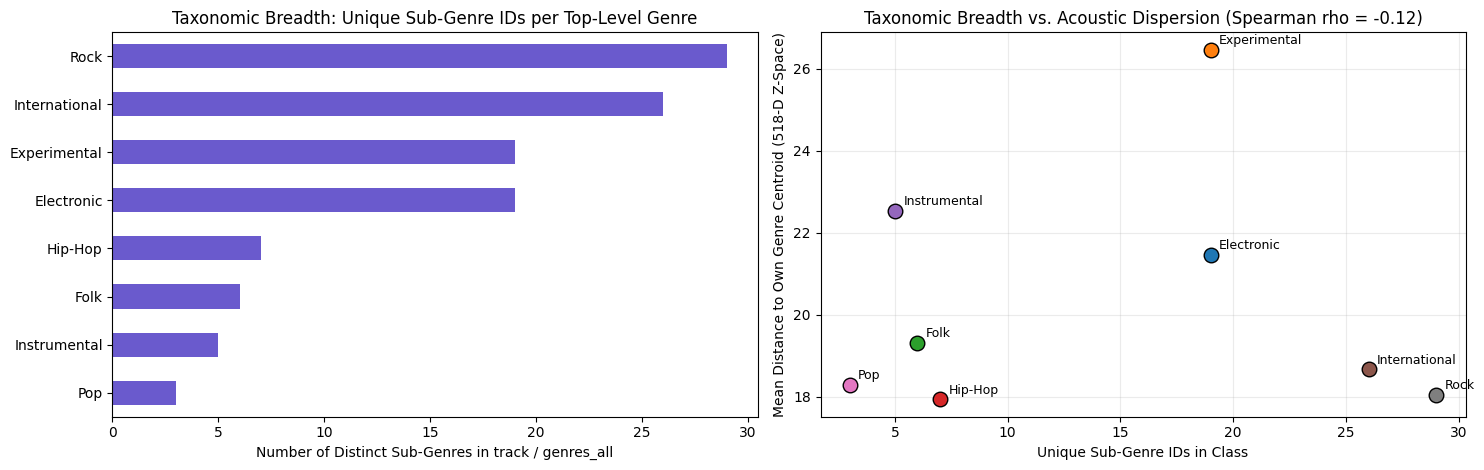

In [38]:
# VII.4 Taxonomy & Text Metadata Analysis: Multi-Genre Complexity, Tag Sparsity & Acoustic Dispersion
import ast
from collections import Counter
from sklearn.preprocessing import StandardScaler

def safe_parse_list(val):
    if isinstance(val, list):
        return val
    if pd.isna(val):
        return []
    try:
        parsed = ast.literal_eval(str(val))
        return parsed if isinstance(parsed, list) else []
    except Exception:
        return []

genre = clean_tracks[('track', 'genre_top')]
genres_all = clean_tracks[('track', 'genres_all')].apply(safe_parse_list)
tags_parsed = clean_tracks[('track', 'tags')].apply(safe_parse_list)
titles = clean_tracks[('track', 'title')].fillna('').astype(str)

# 1. Sub-genre hierarchy breadth & tag coverage by top-level genre
tax_df = pd.DataFrame({
    'genre': genre,
    'n_subgenres': genres_all.apply(len),
    'has_multi_genre': genres_all.apply(lambda x: len(x) > 1),
    'n_tags': tags_parsed.apply(len),
    'has_tags': tags_parsed.apply(lambda x: len(x) > 0),
    'title_words': titles.str.split().str.len(),
})

# Compute within-genre acoustic dispersion (mean distance to own genre centroid in standardized 518-D space)
X_all_z = pd.DataFrame(StandardScaler().fit_transform(clean_features), index=clean_features.index)
centroids_all = X_all_z.groupby(genre).transform('mean')
tax_df['dist_to_genre_centroid'] = np.linalg.norm(X_all_z.values - centroids_all.values, axis=1)

unique_subgenres_per_genre = genres_all.groupby(genre).apply(lambda s: len(set(g for lst in s for g in lst)))
genre_tax_summary = tax_df.groupby('genre').agg(
    avg_labels_per_track=('n_subgenres', 'mean'),
    pct_multi_label=('has_multi_genre', lambda s: s.mean() * 100),
    pct_with_tags=('has_tags', lambda s: s.mean() * 100),
    avg_title_words=('title_words', 'mean'),
    acoustic_dispersion=('dist_to_genre_centroid', 'mean'),
)
genre_tax_summary['unique_subgenres'] = unique_subgenres_per_genre
genre_tax_summary = genre_tax_summary[['unique_subgenres', 'avg_labels_per_track', 'pct_multi_label', 'acoustic_dispersion', 'pct_with_tags', 'avg_title_words']]

print("=== Sub-Genre Taxonomy, Acoustic Dispersion & Text Coverage by Genre ===")
display(genre_tax_summary.sort_values('unique_subgenres', ascending=False).round(2))

# 2. Overall tag sparsity & top user tags
all_tags = [str(t).strip().lower() for lst in tags_parsed for t in lst if str(t).strip()]
print(f"\n=== Free-Text Tag Sparsity (track / tags) ===")
print(f"Tracks with >= 1 user tag : {tax_df['has_tags'].sum():,} / {len(tax_df):,} ({tax_df['has_tags'].mean()*100:.1f}%)")
print(f"Unique tag tokens         : {len(set(all_tags)):,}")
print("Top 12 most frequent tags :", Counter(all_tags).most_common(12))

# 3. Correlation between taxonomic breadth and acoustic dispersion across the 8 genres
r_disp, p_disp = stats.spearmanr(genre_tax_summary['unique_subgenres'], genre_tax_summary['acoustic_dispersion'])
print(f"\nSpearman correlation (unique_subgenres vs. acoustic_dispersion across 8 genres): rho = {r_disp:.3f}, p = {p_disp:.3f}")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

genre_tax_summary['unique_subgenres'].sort_values().plot.barh(ax=axes[0], color='slateblue')
axes[0].set_title("Taxonomic Breadth: Unique Sub-Genre IDs per Top-Level Genre")
axes[0].set_xlabel("Number of Distinct Sub-Genres in track / genres_all")
axes[0].set_ylabel("")

for g, row in genre_tax_summary.iterrows():
    axes[1].scatter(row['unique_subgenres'], row['acoustic_dispersion'], s=110, edgecolor='black', zorder=4)
    axes[1].annotate(
        g,
        xy=(row['unique_subgenres'], row['acoustic_dispersion']),
        xytext=(6, 4),
        textcoords='offset points',
        fontsize=9,
    )
axes[1].set_title(f"Taxonomic Breadth vs. Acoustic Dispersion (Spearman rho = {r_disp:.2f})")
axes[1].set_xlabel("Unique Sub-Genre IDs in Class")
axes[1].set_ylabel("Mean Distance to Own Genre Centroid (518-D Z-Space)")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

**Observations (VII.4):**
- **Taxonomic Breadth vs. Acoustic Dispersion**: Although **Rock** (29 unique sub-genres; 89.3% multi-label) and **International** (26 sub-genres; 92.0% multi-label) carry the richest sub-genre hierarchies, their audio features remain relatively compact (mean centroid distances **18.05** and **18.67**, comparable to **Hip-Hop** at **17.95** and **Pop** at **18.29**). By contrast, **Experimental** is by far the most acoustically scattered class (**26.47**, nearly 50% wider than Hip-Hop/Rock), followed by **Instrumental** (**22.55**, despite only 5 sub-genre IDs) and **Electronic** (**21.47**)—showing that label-hierarchy count alone does not predict acoustic spread ($\rho = -0.12$, $p = 0.778$).
- **Why Free-Text Tags Cannot Replace Audio Features**: Only **17.0%** of tracks (1,355 / 7,983) contain any user tag in `track / tags` (dropping to 9.4% in Hip-Hop and 10.0% in Folk), scattered across 1,191 inconsistent tokens. Moreover, the top tags directly echo the target labels (`electronic`, `instrumental`, `experimental`, `folk`, `pop`, `rock`), creating **direct target leakage** if included as predictors. Track titles are uniformly brief (2.6–3.4 words across all genres).
- **Modeling Implication**: `track / genres_all`, `track / tags`, and `track / title` must be excluded from model inputs, while `genres_all` and within-class acoustic dispersion provide valuable diagnostic context for interpreting confusion matrices (e.g., high error expected on dispersed **Experimental** tracks and multi-label crossover tracks).

### **Summary & Key Takeaways (Section VII — Type-Specific Insights for Audio-Based Genre Mining)**
- **Respect Group Structure (`artist / id`) During Cross-Validation**: Because 85.0% of tracks belong to multi-track artists (with extreme concentration in **Instrumental**—one artist alone supplies 206 tracks) and same-artist tracks sit far closer in 518-D audio space (median distance **22.73**) than same-genre/different-artist tracks (**27.20**), FMA's artist-disjoint `set / split` (0 artist overlap) is essential. Any k-fold tuning inside the `training` split should use **`GroupKFold` grouped by `artist / id`**.
- **Exclude Temporal & Text Metadata to Prevent Leakage**: Genre upload waves vary sharply by year (e.g., 2015's Instrumental surge) while `set / split` spans all years, and `track / tags` is 83% empty yet leaks literal genre names. Meanwhile, core top-ranked audio features (`mfcc / mean / 01`, `spectral_rolloff / mean / 01`, `spectral_contrast / mean / 04`) remain temporally stable across 2008–2017 ($|\rho| \le 0.05$).
- **Domain-Guided Feature Selection Inside Audio Families**: Band-level analysis shows *not all indices within a family are equal*: (1) retain **all 20 MFCCs** (do not truncate at 12–13, as even higher-order MFCC `mean`s and `mfcc / std` bands `06–20` retain strong genre signal); (2) prioritize **mid-frequency `spectral_contrast` bands `02–04` and high-treble band `07`** over weak band `06`; and (3) treat the 12 **chroma pitch classes** as key-invariant tonal-density indicators that are prime candidates for summary aggregation or dimensionality reduction.
- **Anticipating Class-Specific Error Patterns**: Combining VI.3/VI.5 with VII.4 reveals two distinct sources of classification difficulty—**centroid proximity** (Pop/International sitting near the global mean) and **high internal acoustic dispersion** (Experimental at 26.47 and Instrumental at 22.55)—guiding downstream error analysis after model training.

# **VIII. Summary of findings**

This exploratory data analysis examined the FMA-Small dataset (`tracks.csv` and `features.csv`) to lay a verified, leakage-free foundation for **analyzing the importance of audio features in music genre classification using data mining techniques**. Across data quality auditing, cleaning, univariate profiling, bivariate/multivariate modeling diagnostics, and type-specific analysis, five core findings stand out:


### **1. Clean, Balanced, and Leakage-Safe Benchmark Dataset**
- After removing **17 duplicate feature rows** and **8 metadata columns exceeding 90% missingness**, `clean_features` (`7,983 × 518` `float64`) and `clean_tracks` (`7,983 × 44`) are 1-to-1 aligned on `track_id` with **0 missing audio features**, **0 missing target labels**, and **0 impossible values**.
- The target `track / genre_top` remains virtually balanced across all 8 genres (~12.4–12.5% each), and FMA's official `set / split` maintains clean ~80/10/10 stratification across genres ($\chi^2 = 0.219$, $p = 1.000$) with **zero cross-split artist overlap**—eliminating the need for class resampling or manual re-splitting.

### **2. Timbre (`mfcc`) and Spectral Shape/Contrast Drive Genre Discrimination**
- Across three complementary feature-ranking methods computed strictly on the `training` split—**ANOVA $F$**, **Mutual Information (MI)**, and **Random Forest (RF) Gini importance**—rankings show strong cross-method agreement ($\rho = 0.742\text{–}0.872$).
- **Total vs. Per-Feature Importance**: By total RF share, **`mfcc` (34.3%)** and **`spectral_contrast` (13.9%)** jointly supply **48.2%** of overall tree importance. By *per-feature* signal density, the compact 7-feature spectral and energy families lead—**`spectral_rolloff`** (mean MI = 0.131, mean $F = 118.9$), **`spectral_centroid`** (mean MI = 0.121, mean $F = 115.4$), **`spectral_bandwidth`**, **`rmse`**, and **`spectral_contrast`**—while `chroma_cens` and `chroma_cqt` rank weakest per feature (mean MI = 0.029–0.031).
- **Temporal Variability Matters as Much as Average Level**: Among the 7 frame-level summary statistics, **`std` (18.1%), `mean` (17.3%), and `median` (17.2%)** account for **52.5%** of total RF importance, confirming that dynamic fluctuations over a 30-second clip are just as informative as average acoustic levels (`min`, `max`, and `kurtosis` contribute least).
- **Band-Specific Acoustic Nuances**: Retaining **all 20 MFCCs** is warranted (even higher-order `mfcc / mean` indices `10–20` rebound to $\eta^2_H \approx 0.16\text{–}0.18$, and `mfcc / std` is stronger in bands `06–20` than `01–05`). Within `spectral_contrast`, **mid-frequency bands `02–04`** (peaking at band `04`, $\eta^2_H = 0.254$) and high-treble band `07` carry the strongest genre signal, whereas band `06` drops sharply (`0.039`). Meanwhile, `chroma_stft` stays flat across all 12 pitch classes (reflecting musical key invariance) but remains orthogonal to spectral/loudness descriptors.

### **3. Scaling, Skewness, and Heavy Multicollinearity Shape Preprocessing**
- Audio descriptors span **6 orders of magnitude** (from ~`0.001` in `tonnetz` to `>2,300` Hz in `spectral_rolloff`), with heavily right-skewed tails (`skew = 1.0–3.5`) and 1–4% legitimate musical outliers—making feature scaling (`StandardScaler` / `RobustScaler`) essential for linear, margin-, distance-, and neural models.
- **39.4% of all features (204 / 518)** share $|r| \ge 0.85$ with at least one other feature, led by a near-collinear spectral brightness block (`spectral_centroid`, `spectral_rolloff`, `spectral_bandwidth`; $\rho = 0.915\text{–}0.988$) and `mean`/`median` twin pairs. PCA confirms strong redundancy: **81 PCs (15.6%)** capture 80% of variance and **204 PCs (39.4%)** capture 95%.

### **4. Distinct Genre Signatures—But High-Dimensional, Non-Linear Models Are Required**
- Genre acoustic profiles separate clearly into macro-neighborhoods: **Folk & Instrumental** (warm, dark, lower-energy; Folk elevated on low-band spectral contrast), **Electronic & Hip-Hop** (bright, wide-band, high dynamic variability), and **Rock** (loudest overall with low temporal brightness variability).
- However, PC1 + PC2 capture only **18.9%** of total variance with heavy track-level overlap. Two distinct mechanisms predict where classification errors will cluster: **centroid proximity to the global mean** (**Pop** with $|z| \le 0.23$ across all 16 representative descriptors, plus **International**) and **high internal acoustic dispersion** (**Experimental** at mean centroid distance **26.47** and **Instrumental** at **22.55**).

### **5. Structural Confounds & the "Artist Effect" Dictate Strict Modeling Hygiene**
- **Strong Artist Clustering**: **85.0%** of tracks belong to multi-track artists (with extreme concentration in **Instrumental**: 120 unique artists, max **206 tracks** from one artist), and same-artist pairs sit much closer in 518-D audio space (median distance **22.73**) than same-genre/different-artist pairs (**27.20**). Random row-level CV would leak artist identity; tuning must use **`GroupKFold` by `artist / id`**.
- **Mandatory Metadata Exclusion**: Non-acoustic columns—`track / bit_rate` ($\eta^2_H = 0.052$), `track / duration` ($\eta^2_H = 0.035$), upload/release dates (sharp genre upload waves such as 2015's Instrumental surge), non-MCAR missing metadata, and `track / tags` (83% empty yet leaking literal genre names)—must be excluded so classifiers learn purely from temporally stable audio features ($|\rho| \le 0.05$ across 2008–2017 for top spectral/MFCC descriptors).

### **EDA-to-Modeling Synthesis Table**

| EDA Area | Key Quantitative Finding | Direct Modeling / Data-Mining Implication |
| :--- | :--- | :--- |
| **Target & Split (V.1, VI.1, VII.1)** | 8 balanced genres (~12.5% each); 80/10/10 split ($p=1.000$); 0 cross-split artist overlap | Use official `set / split`; no class reweighting needed; use `GroupKFold(artist_id)` inside `training` |
| **Feature Importance (VI.4, VII.3)** | `mfcc` (34.3%) + `spectral_contrast` (13.9%) = 48.2% RF share; `std`/`mean`/`median` = 52.5%; all 20 MFCCs & contrast bands `02–04`, `07` strongest | Prioritize timbre, spectral shape/contrast, and `std`/`mean`/`median`; run family & stat ablation studies |
| **Scale & Skew (V.3–V.6)** | 6 orders of magnitude across features; right-skew up to 3.48; 1–4% valid acoustic outliers | Retain outliers; apply `StandardScaler`/`RobustScaler` (or power transforms) inside training pipelines |
| **Multicollinearity (VI.2, VI.5)** | 204/518 features (39.4%) have $|r|\ge 0.85$; 81 PCs = 80% variance, 204 PCs = 95% variance | Use regularization (L1/L2, SVM), PCA, or collinearity pruning; validate with grouped permutation/SHAP importance |
| **Confound & Group Risks (III.2, VI.1, VII.1–4)** | Same-artist distance `22.73` vs. same-genre `27.20`; `bit_rate`, dates, and tags leak non-acoustic bias | Train strictly on `clean_features` (518 audio columns); audit confusion matrices on Pop, International, and Experimental |

# **IX. Limitations and next steps**

While this EDA establishes a clean, leakage-free baseline and strong exploratory evidence on audio-feature importance, several dataset and analytical boundaries must be accounted for as the project transitions into formal data-mining modeling and evaluation.

## **IX.1 Limitations**

1. **Temporal Information Lost in Pre-Aggregated 30-Second Summaries**: `features.csv` summarizes fixed 30-second audio clips into 7 global frame statistics (`mean`, `std`, `median`, `min`, `max`, `skew`, `kurtosis`). This discards sequential musical structure—such as tempo/beat periodicity, rhythm patterns, intro/chorus dynamics, and instrumentation outside the 30-second excerpt.
2. **Single-Label Evaluation on Inherently Multi-Genre Tracks**: Between **40.2% (Hip-Hop)** and **92.2% (Electronic)** of tracks carry multiple sub-genres in `track / genres_all`. Collapsing multi-genre tracks into a single top-level label (`track / genre_top`) introduces irreducible label ambiguity—particularly for crossover **Pop**, **International**, and acoustically dispersed **Experimental** tracks.
3. **Artist Concentration & Minor Compilation-Album Overlap**: Although `set / split` enforces strict zero-artist overlap across partitions, artist diversity is uneven across genres (e.g., **Instrumental** has only 120 unique artists, with one artist contributing 206 tracks). Models may overfit prolific artists' acoustic signatures inside the training split. Additionally, a small number of multi-artist compilation `album / id` values span splits (58 train–val, 49 train–test), and genre-level MP3 bit-rate differences (256 vs. 320 kbps medians) remain subtle background encoding variation.
4. **Exploratory Feature Importance vs. True Out-of-Sample Predictive Value**: The Random Forest Gini importances in Section VI.4 were computed on the training split to avoid test leakage, and Gini scores can be diluted across highly collinear pairs (e.g., `mean`/`median` twins or `spectral_centroid`/`spectral_rolloff`) and biased toward high-cardinality continuous splits. Feature importance claims must therefore be corroborated using **out-of-sample permutation importance, SHAP values, and ablation experiments**.
5. **Dataset Scope & External Generalizability**: FMA-Small covers 7,983 cleaned independent/Creative Commons tracks uploaded between 2008 and 2017 across 8 broad genres. Feature rankings and classification accuracy may not transfer identically to commercial mainstream catalogs, post-2017 production trends, or finer-grained sub-genre taxonomies (`fma-medium` / `fma-large`).

## **IX.2 Next Steps (Data Mining & Modeling Roadmap)**

1. **Build Leakage-Free Preprocessing & Group-Aware Tuning Pipelines**:
   - Use strictly the 518 `clean_features` descriptors as model inputs and honor the official `set / split` (`training` / `validation` / `test`).
   - Encapsulate scaling (`StandardScaler` and `RobustScaler`), optional power transforms (`Yeo-Johnson`) for skewed descriptors (`zcr`, `rmse`, `spectral_centroid`), feature selection, and PCA inside `sklearn.pipeline.Pipeline` objects fit exclusively on training folds.
   - Perform hyperparameter tuning inside `training` using **`GroupKFold` grouped by `artist / id`** so cross-validation mirrors the artist-disjoint `validation` and `test` partitions.
2. **Benchmark Multiple Data-Mining Model Families**:
   - Train and compare complementary classifiers on `validation` (before a single final evaluation on `test`): **regularized linear/margin models** (L2/L1 Logistic Regression, Linear & RBF-kernel SVM), **tree ensembles** (Random Forest, Gradient Boosting / XGBoost / LightGBM), **distance-based models** (KNN on PCA-reduced features), and a **tabular Multi-Layer Perceptron (MLP)**.
   - Report **Macro-F1**, **Overall Accuracy**, **Top-2 Accuracy**, and **per-genre confusion matrices** to diagnose where acoustic overlap limits performance.
3. **Validate Audio Feature Importance via Ablations & Explainable AI**:
   - **Feature-Family Ablation Study**: Train the top-performing classifier(s) on isolated and combined subsets—`MFCC only`, `Spectral Shape & Contrast only`, `MFCC + Spectral + RMSE`, `Chroma + Tonnetz only`, and `All 518 Features`—to quantify each family's real Macro-F1 contribution.
   - **Summary-Statistic & Redundancy Ablation**: Compare compact feature sets (`mean + median + std` only, collinearity-pruned subsets at $|r| < 0.85$, and PCA retaining 80% / 90% / 95% variance) against the full 518-feature baseline.
   - **Redundancy-Aware Attribution**: Compute **grouped permutation importance** (permuting entire feature families together on `validation`) and **SHAP values** on the best ensemble model to obtain per-genre feature explanations (e.g., confirming which features specifically drive Folk vs. Instrumental or Rock vs. Hip-Hop decisions).
4. **Domain-Aware Feature Engineering & Error Analysis**:
   - Test **key-invariant chroma summaries** (aggregating mean, std, and entropy across the 12 chromatic pitch bins) to compress the 252 redundant chroma columns without losing tonal-density information.
   - Cross-reference misclassified `validation` tracks against `track / genres_all`, `artist / id`, and `track / bit_rate` to separate genuine acoustic ambiguity (e.g., dispersed **Experimental** or multi-label crossover tracks) from artist-concentration bias.
5. **Optional Comparative Extension (Raw Audio / Deep Representations)**:
   - As a benchmark extension, compare tabular `librosa` feature-mining models against Mel-spectrogram CNNs or pretrained audio embeddings extracted from the `fma_small` MP3 audio files to quantify the trade-off between feature-level interpretability and end-to-end classification accuracy.

# **X. References**

### **Dataset & Repository**
- Defferrard, M., Benzi, K., Vandergheynst, P., & Bresson, X. (2017). FMA: A Dataset for Music Analysis. In *Proceedings of the 18th International Society for Music Information Retrieval Conference (ISMIR 2017)*, 316–323. https://arxiv.org/abs/1612.01840
- Defferrard, M. (2017). *FMA: A Dataset for Music Analysis* [Software and dataset repository]. GitHub. https://github.com/mdeff/fma

### **Audio Feature Extraction & Music Information Retrieval (MIR)**
- Flexer, A., & Schnitzer, D. (2009). Album and artist effects for audio similarity at the scale of the web. In *Proceedings of the 6th Sound and Music Computing Conference (SMC 2009)*, 59–64.
- Harte, C., Sandler, M., & Gasser, M. (2006). Detecting harmonic change in musical audio. In *Proceedings of the 1st ACM Workshop on Audio and Music Computing Multimedia (AMCMM 2006)*, 21–26. https://doi.org/10.1145/1178723.1178727
- Jiang, D.-N., Lu, L., Zhang, H.-J., Tao, J.-H., & Cai, L.-H. (2002). Music type classification by spectral contrast feature. In *Proceedings of the IEEE International Conference on Multimedia and Expo (ICME 2002)*, 1, 113–116. https://doi.org/10.1109/ICME.2002.1035731
- McFee, B., Raffel, C., Liang, D., Ellis, D. P. W., McVicar, M., Battenberg, E., & Nieto, O. (2015). librosa: Audio and music signal analysis in Python. In *Proceedings of the 14th Python in Science Conference (SciPy 2015)*, 18–25. https://doi.org/10.25080/Majora-7b98e3ed-003
- Tzanetakis, G., & Cook, P. (2002). Musical genre classification of audio signals. *IEEE Transactions on Speech and Audio Processing*, 10(5), 293–302. https://doi.org/10.1109/TSA.2002.800560

### **Statistical & Data Mining Methods**
- Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5–32. https://doi.org/10.1023/A:1010933404324
- Jolliffe, I. T., & Cadima, J. (2016). Principal component analysis: A review and recent developments. *Philosophical Transactions of the Royal Society A: Mathematical, Physical and Engineering Sciences*, 374(2065), 20150202. https://doi.org/10.1098/rsta.2015.0202
- Kraskov, A., Stögbauer, H., & Grassberger, P. (2004). Estimating mutual information. *Physical Review E*, 69(6), 066138. https://doi.org/10.1103/PhysRevE.69.066138
- Kruskal, W. H., & Wallis, W. A. (1952). Use of ranks in one-criterion variance analysis. *Journal of the American Statistical Association*, 47(260), 583–621. https://doi.org/10.1080/01621459.1952.10483441

### **Python Libraries & Software Tools**
- Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., Wieser, E., Taylor, J., Berg, S., Smith, N. J., Kern, R., Picus, M., Hoyer, S., van Kerkwijk, M. H., Brett, M., Haldane, A., Fernández del Río, J., Wiebe, M., Peterson, P., ... Oliphant, T. E. (2020). Array programming with NumPy. *Nature*, 585(7825), 357–362. https://doi.org/10.1038/s41586-020-2649-2
- Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering*, 9(3), 90–95. https://doi.org/10.1109/MCSE.2007.55
- McKinney, W. (2010). Data structures for statistical computing in Python. In *Proceedings of the 9th Python in Science Conference (SciPy 2010)*, 56–61. https://doi.org/10.25080/Majora-92bf1922-00a
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- Virtanen, P., Gommers, R., Oliphant, T. E., Haberland, M., Reddy, T., Cournapeau, D., Burovski, E., Peterson, P., Weckesser, W., Bright, J., van der Walt, S. J., Brett, M., Wilson, J., Millman, K. J., Mayorov, N., Nelson, A. R. J., Jones, E., Kern, R., Larson, E., ... SciPy 1.0 Contributors. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods*, 17(3), 261–272. https://doi.org/10.1038/s41592-019-0686-2
- Waskom, M. L. (2021). seaborn: Statistical data visualization. *Journal of Open Source Software*, 6(60), 3021. https://doi.org/10.21105/joss.03021